# TOPIC 10 – PORTFOLIO RISK MEASUREMENT FOR VN30 STOCKS WITH DCC-GARCH

| Part | Content |
|---|---|
| 0 | Setup: libraries, paths, shared constants |
| 1 | Data, cleaning, log returns, stylized facts (JB, ADF/KPSS, ACF/Ljung-Box, ARCH-LM, ARMA) |
| 2 | GARCH / GJR-GARCH × Normal / Student-t, model selection, residuals, out-of-sample comparison |
| 3 | DCC-GARCH, CCC & static benchmarks, dynamic correlation, VAR / cointegration |
| 4 | VaR, ES, backtesting, Basel tests, out-of-sample forecasts, copulas |
| 5 | Euler risk contribution, stress testing, integration check, recommendations |
| 6 | Conclusions, limitations and future work |

In [1]:
# ===================== 0.0 AUTO-INSTALL MISSING LIBRARIES (new machine) =====================
import importlib.util, subprocess, sys
_REQUIRED = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "matplotlib": "matplotlib",
             "openpyxl": "openpyxl", "yfinance": "yfinance"}        # required: import name -> pip name
_OPTIONAL = {"statsmodels": "statsmodels"}                          # optional: still runs if missing (fallback code exists)


def _pip_install(pkgs):
    return subprocess.call([sys.executable, "-m", "pip", "install", "-q", *pkgs]) == 0


_miss_req = [p for m, p in _REQUIRED.items() if importlib.util.find_spec(m) is None]
_miss_opt = [p for m, p in _OPTIONAL.items() if importlib.util.find_spec(m) is None]
if _miss_req or _miss_opt:
    print("Installing missing libraries:", _miss_req + _miss_opt)
if _miss_req and not _pip_install(_miss_req):
    raise RuntimeError(f"Could not install {_miss_req}. Check your internet connection or run: pip install {' '.join(_miss_req)}")
if _miss_opt and not _pip_install(_miss_opt):
    print(f"[!] Skipping optional library {_miss_opt} (could not install) - notebook uses fallback code.")
if _miss_req or _miss_opt:
    importlib.invalidate_caches()

# ===================== 0.1 LIBRARIES =====================
import os                     # read environment variables
import re                     # regular expressions: split dividend / stock-split rows in the Yahoo file
import warnings               # silence unneeded warnings
import datetime as dt         # date types
from itertools import combinations   # build stock pairs
from pathlib import Path      # safe path handling on Windows

import numpy as np            # matrix computation
import pandas as pd           # data tables
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats                     # Normal / t / chi-square distributions, JB
from scipy.optimize import minimize         # maximise the likelihood (MLE)
from scipy.signal import lfilter            # fast linear filter for the GARCH recursion
from scipy.special import gammaln           # log-Gamma for the Student-t density

try:                                        # statsmodels: only used for ADF / KPSS (if available)
    from statsmodels.tsa.stattools import adfuller, kpss
    from statsmodels.tools.sm_exceptions import InterpolationWarning
    HAS_SM = True
except ImportError:
    HAS_SM = False

try:                                        # display() is built into Jupyter; when running a .py file use print instead
    display
except NameError:
    display = print

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100
print("statsmodels available:", HAS_SM)

statsmodels available: True


In [2]:
# ===================== 0.2 SHARED CONFIGURATION =====================
# ---- AUTOMATIC PATHS (no edits needed when changing machine) ----
# Layout:  <project folder>/code/ (this notebook) , input/ (5 raw Excel files) , ouput/ (auto-created)
# Override if needed: set the environment variables PROJECT_DIR / INPUT_DIR / OUTPUT_DIR before opening the notebook.
MEMBER_DIRS = {"TV1": "TV1_Data_EDA", "TV2": "TV2_GARCH", "TV3": "TV3_DCC",
               "TV4": "TV4_VaR_Backtest", "TV5": "TV5_Euler_Stress"}


def find_base_dir() -> Path:
    """PROJECT_DIR -> parent of code/ -> folder (cwd or its parent) containing input/ -> parent of cwd."""
    env = os.environ.get("PROJECT_DIR")
    if env:
        return Path(env).expanduser().resolve()
    cwd = Path.cwd().resolve()
    if cwd.name.lower() == "code":
        return cwd.parent
    for p in [cwd, *cwd.parents]:                              # walk up to find the folder containing input/
        if (p / "input").is_dir() or (p / "Input").is_dir():
            return p
    for p in cwd.iterdir():                                    # opened in the parent folder by mistake: search one level down
        if p.is_dir() and ((p / "input").is_dir() or (p / "Input").is_dir()) and (p / "code").is_dir():
            return p
    return cwd


def pick_dir(base: Path, names) -> Path:
    """Pick an existing sub-folder (accepts input/Input); if none exists use the first name."""
    return next((base / n for n in names if (base / n).is_dir()), base / names[0])


BASE_DIR = find_base_dir()
INPUT_DIR = (Path(os.environ["INPUT_DIR"]).expanduser().resolve() if os.environ.get("INPUT_DIR")
             else pick_dir(BASE_DIR, ["input", "Input"]))
OUTPUT_DIR = (Path(os.environ["OUTPUT_DIR"]).expanduser().resolve() if os.environ.get("OUTPUT_DIR")
              else pick_dir(BASE_DIR, ["ouput", "Ouput", "output", "Output"]))
INPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ROOT_OUT = OUTPUT_DIR                                    # one sub-folder per part in ouput/
OUT = {k: ROOT_OUT / v for k, v in MEMBER_DIRS.items()}
for d in OUT.values():
    d.mkdir(parents=True, exist_ok=True)

# ---- Shared constants ----
TICKERS_ORDER = ["FPT", "HPG", "MWG", "VCB", "VHM"]    # display order (other tickers in Input are still read)
ALPHA = 0.05                 # significance level for all tests
LB_LAGS = [5, 10, 20]        # Ljung-Box lags
TRADING_DAYS = 252           # trading days per year for annualisation
SCALE = 100.0                # estimate GARCH on returns in % (r × 100) for numerical stability
SELECT_BY = "BIC"            # GARCH model selection criterion: "AIC" or "BIC"
PAIRS = [("VCB", "VHM"), ("HPG", "FPT")]               # pairs for dynamic correlation (as required)
VAR_LEVELS = [0.95, 0.99]    # VaR confidence levels
HS_WINDOW = 250              # Historical Simulation window (≈ 1 year)
BASEL_WINDOW = 250           # Basel Traffic Light window (last 250 sessions)
N_TEST = 500                 # number of out-of-sample test days (sections 2.6 and 4.5)
REFIT = 20                   # re-estimate the model every REFIT sessions (sections 2.6 and 4.5)
WINDOW_MAX = 1000            # maximum estimation window (sessions); shrinks automatically for short samples
VIOL_MODEL = "Normal"        # >>> MODEL USED TO MARK VIOLATIONS ON ALL PLOTS & PART 4 COMMENTARY: "Normal" or "t" <<<
VIOL_OOS = {"Normal": "DCC-N", "t": "DCC-t"}[VIOL_MODEL]   # corresponding name in the out-of-sample part
EULER_CL = 0.99              # confidence level for Euler risk allocation
STRESS = {                   # stress periods (as required)
    "Covid-19 (02–04/2020)": ("2020-02-01", "2020-04-30"),
    "Bond & interest-rate stress (04–11/2022)": ("2022-04-01", "2022-11-30"),
}


STRESS_COLORS = ["tab:red", "tab:orange"]   # one colour per period to tell Covid-19 apart from Bond & interest-rate stress


def shade_stress(ax, alpha=0.12, label=True, xlim=None):
    """Shade each stress period (one colour per period, legend by period name).
    xlim=(start, end): skip periods entirely outside this range (avoids stretching the time axis)."""
    for (name, (s, e)), c in zip(STRESS.items(), STRESS_COLORS):
        s, e = pd.Timestamp(s), pd.Timestamp(e)
        if xlim is not None and (e < xlim[0] or s > xlim[1]):
            continue
        ax.axvspan(s, e, color=c, alpha=alpha, label=(name if label else None))


def grid_axes(n, ncol=2, h=3.2, w=13, **kw):
    """Create a grid of axes for n tickers, hiding unused ones."""
    ncol = min(ncol, n)
    nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(w, h * nrow), squeeze=False, **kw)
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    return fig, axes.flat


print("BASE_DIR  :", BASE_DIR)
print("INPUT_DIR :", INPUT_DIR, "| exists:", INPUT_DIR.exists())
print("OUTPUT_DIR:", OUTPUT_DIR)

BASE_DIR  : D:\Năm 3\Ứng dụng công nghệ trong TCNH\final 2
INPUT_DIR : D:\Năm 3\Ứng dụng công nghệ trong TCNH\final 2\input | exists: True
OUTPUT_DIR: D:\Năm 3\Ứng dụng công nghệ trong TCNH\final 2\ouput


---
# PART 1: DATA PIPELINE & EXPLORATORY ANALYSIS
## 1.1 – 1.2 Data collection & cleaning

In [3]:
# ===================== 1.1 READ RAW DATA =====================
REQUIRED_COLS = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
FFILL_LIMIT = 10          # maximum consecutive sessions to forward-fill when a stock is suspended
GAP_THRESHOLD_DAYS = 4    # two real sessions more than 4 calendar days apart => record a long break
PRICE_LIMIT = 0.07        # HOSE daily price limit (±7%)
EVENTS = {}               # dividend / split events extracted from the Yahoo file
REPORT = []               # cleaning log -> cleaning_report.txt


def log(msg=""):
    print(msg)
    REPORT.append(str(msg))


def _map_col(col):
    """Normalise column names: 'Adj Close     Adjusted close price...' -> 'Adj Close'."""
    c = str(col).strip().lower()
    for key, name in [("adj", "Adj Close"), ("date", "Date"), ("open", "Open"), ("high", "High"),
                      ("low", "Low"), ("close", "Close"), ("volume", "Volume")]:
        if c.startswith(key):
            return name
    return col


def _to_number(s: pd.Series) -> pd.Series:
    """Safe number parsing: '1,234.56', '1.234,56', '-', '#N/A' ... -> float (non-numeric cell -> NaN)."""
    if pd.api.types.is_numeric_dtype(s):
        return pd.to_numeric(s, errors="coerce")

    def conv(v):
        if v is None or (isinstance(v, float) and np.isnan(v)):
            return np.nan
        if isinstance(v, (int, float, np.number)):
            return float(v)
        t = str(v).strip().replace("\u00a0", "").replace(" ", "")
        if t in ("", "-", "--", "#N/A", "N/A", "NA", "nan", "None"):
            return np.nan
        if "," in t and "." in t:                    # the separator appearing last is the decimal separator
            t = t.replace(".", "").replace(",", ".") if t.rfind(",") > t.rfind(".") else t.replace(",", "")
        elif "," in t:
            t = t.replace(",", "") if re.fullmatch(r"-?\d{1,3}(,\d{3})+", t) else t.replace(",", ".")
        elif t.count(".") > 1:
            t = t.replace(".", "")
        try:
            return float(t)
        except ValueError:
            return np.nan
    return s.map(conv).astype(float)


def _parse_dates(s: pd.Series, swap: bool) -> pd.Series:
    """Parse a mixed date column (real datetimes + dd/mm/yyyy strings). swap=True: swap day<->month for cells Excel mis-converted."""
    out = []
    for v in s:
        if pd.isna(v):
            out.append(pd.NaT)
        elif isinstance(v, (pd.Timestamp, dt.datetime, dt.date)):
            ts = pd.Timestamp(v)
            if swap and ts.day <= 12:
                ts = pd.Timestamp(year=ts.year, month=ts.day, day=ts.month)
            out.append(ts)
        else:
            txt = str(v).strip()
            iso = re.match(r"^\d{4}-\d{2}-\d{2}", txt) is not None
            out.append(pd.to_datetime(txt, dayfirst=not iso, errors="coerce"))
    return pd.Series(pd.to_datetime(out), index=s.index)


def parse_dates(s: pd.Series, name: str) -> pd.Series:
    """Try 2 ways of parsing dates and keep the one that is chronologically ordered with the fewest duplicate dates."""
    def score(d):
        diff = d.dropna().diff().dropna()
        order = int(min((diff < pd.Timedelta(0)).sum(), (diff > pd.Timedelta(0)).sum()))
        return order + int(d.dropna().duplicated().sum())
    cands = {False: _parse_dates(s, False)}
    if any(isinstance(v, (pd.Timestamp, dt.datetime, dt.date)) for v in s):
        cands[True] = _parse_dates(s, True)
    best = min(cands, key=lambda k: score(cands[k]))
    if best:
        log(f"  - {name}: detected day/month swapped by Excel -> fixed")
    return cands[best]


def load_stock(path: Path) -> pd.DataFrame:
    """Read one Excel file -> DataFrame indexed by Date with normalised numeric columns; split off dividend/split event rows."""
    tk = path.stem.upper()
    df = pd.read_excel(path, sheet_name=0)
    df.columns = [_map_col(c) for c in df.columns]
    missing = [c for c in ["Date"] + REQUIRED_COLS if c not in df.columns]
    if missing:
        raise ValueError(f"{path.name}: missing columns {missing}")
    df = df[["Date"] + REQUIRED_COLS].copy()
    raw = df[REQUIRED_COLS].map(lambda v: "" if pd.isna(v) else str(v))   # as strings to detect event rows
    df["Date"] = parse_dates(df["Date"], tk)

    # Event rows: Yahoo inserts "790.5 Dividend ..." or "23:20 Stock Splits ..." into the price table
    is_event = raw.apply(lambda c: c.str.contains(r"dividend|stock\s*split", case=False, regex=True)).any(axis=1)
    if is_event.any():
        txt = raw.loc[is_event].apply(lambda r: next((v for v in r if re.search("ividend|plit", str(v))), ""), axis=1)
        m = txt.str.extract(r"^\s*([\d.,:]+)\s*(Dividend|Stock\s*Splits?)", flags=re.I)
        EVENTS[tk] = pd.DataFrame({"Date": df.loc[is_event, "Date"].values, "Ticker": tk,
                                   "Type": m[1].str.title().values, "Value": m[0].values}).drop_duplicates()
        n_div = int((EVENTS[tk]["Type"] == "Dividend").sum())
        log(f"      {tk}: split off {int(is_event.sum())} event rows ({n_div} dividends, "
            f"{len(EVENTS[tk]) - n_div} splits/bonus shares)")
        df = df.loc[~is_event].copy()

    for c in REQUIRED_COLS:
        df[c] = _to_number(df[c])
    n_bad = int(df["Date"].isna().sum())
    df = df.dropna(subset=["Date"])
    df["Date"] = df["Date"].dt.normalize()
    n_dup = int(df["Date"].duplicated().sum())
    df = df.drop_duplicates(subset="Date", keep="last").sort_values("Date").set_index("Date")
    log(f"  - Read {path.name}: {len(df)} rows | {df.index.min().date()} -> {df.index.max().date()} "
        f"| bad dates dropped: {n_bad} | duplicate dates dropped: {n_dup}")
    return df


# ---------------- DATA SOURCE ----------------
DATA_SOURCE = "yahoo"        # "yahoo": download fresh from Yahoo Finance (needs internet) | "local": re-read the saved file input/my_prices.csv
YF_SYMBOLS = {"FPT": "FPT.VN", "HPG": "HPG.VN", "MWG": "MWG.VN", "VCB": "VCB.VN", "VHM": "VHM.VN"}   # internal ticker -> Yahoo ticker
START_DATE = "2019-01-01"    # download start date (inclusive)
END_DATE = "2024-12-31"      # download end date (inclusive)
MY_PRICES = INPUT_DIR / "my_prices.csv"   # raw data downloaded and saved so results are reproducible even if Yahoo changes later
RAW_COLS = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]


def download_yahoo(symbols: dict, start: str, end: str, retries: int = 3) -> pd.DataFrame:
    """Download price history from Yahoo Finance (unadjusted + Adj Close + dividends/splits) -> long table (Date, Ticker, ...)."""
    import time
    import yfinance as yf
    end_excl = (pd.Timestamp(end) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")   # Yahoo: the end date is exclusive
    frames = []
    for tk, sym in symbols.items():
        h = None
        for k in range(retries):
            try:
                h = yf.Ticker(sym).history(start=start, end=end_excl, auto_adjust=False, actions=True)
                if h is not None and len(h):
                    break
            except Exception as e:                                   # network error / rate limit -> retry
                print(f"  ! {sym}: attempt {k + 1}/{retries} failed: {e}")
            time.sleep(2 * (k + 1))
        if h is None or h.empty:
            raise RuntimeError(f"Yahoo Finance returned no data for {sym}. Check your internet connection / ticker.")
        h = h.copy()
        h.index = pd.DatetimeIndex(h.index).tz_localize(None).normalize()
        h.index.name = "Date"
        for c in ["Dividends", "Stock Splits"]:
            if c not in h.columns:
                h[c] = 0.0
        h["Ticker"] = tk
        frames.append(h[["Ticker"] + RAW_COLS + ["Dividends", "Stock Splits"]].reset_index())
        print(f"  ✔ {sym}: {len(h)} rows | {h.index.min().date()} -> {h.index.max().date()}")
    return pd.concat(frames, ignore_index=True)


def split_raw(long_df: pd.DataFrame):
    """Long table -> dict {ticker: DataFrame(index=Date, 6 price/volume columns)} + store dividend/split events in EVENTS."""
    out = {}
    for tk, g in long_df.groupby("Ticker", sort=False):
        g = g.drop_duplicates(subset="Date", keep="last").sort_values("Date").set_index("Date")
        for c in RAW_COLS:
            g[c] = pd.to_numeric(g[c], errors="coerce")
        ev = []
        for col, typ in [("Dividends", "Dividend"), ("Stock Splits", "Stock Splits")]:
            if col in g.columns:
                x = pd.to_numeric(g[col], errors="coerce").fillna(0)
                x = x[x > 0]
                ev.append(pd.DataFrame({"Date": x.index, "Ticker": tk, "Type": typ, "Value": x.values}))
        if ev and sum(len(e) for e in ev):
            EVENTS[tk] = pd.concat(ev, ignore_index=True)
        out[tk] = g[RAW_COLS]
        n_div = int((EVENTS[tk]["Type"] == "Dividend").sum()) if tk in EVENTS else 0
        n_spl = (len(EVENTS[tk]) - n_div) if tk in EVENTS else 0
        log(f"  - {tk}: {len(g)} rows | {g.index.min().date()} -> {g.index.max().date()} "
            f"| {n_div} dividend events, {n_spl} split/bonus-share events")
    return out


REPORT.clear()
log("=" * 78); log("READ DATA"); log("=" * 78)
long_df = None
if DATA_SOURCE == "yahoo":
    log(f"Source: Yahoo Finance (yfinance) | {START_DATE} -> {END_DATE} | {', '.join(YF_SYMBOLS.values())}")
    try:
        long_df = download_yahoo(YF_SYMBOLS, START_DATE, END_DATE)
        long_df.to_csv(MY_PRICES, index=False, encoding="utf-8-sig")
        log(f"Saved raw data to {MY_PRICES}")
    except Exception as e:                                           # network down -> use the copy saved last time (if any)
        if not MY_PRICES.exists():
            raise
        log(f"[!] Could not download from Yahoo ({e}). Using saved copy: {MY_PRICES}")
if long_df is None:                                                  # DATA_SOURCE == "local" or fallback on network error
    if MY_PRICES.exists():
        log(f"Source: saved file {MY_PRICES}")
        long_df = pd.read_csv(MY_PRICES, parse_dates=["Date"])
    else:                                                            # last fallback: old Excel files in input/
        files = sorted(p for p in INPUT_DIR.glob("*.xlsx") if not p.name.startswith("~$"))
        if not files:
            raise FileNotFoundError(f"No {MY_PRICES.name} or .xlsx file in {INPUT_DIR}. "
                                    f"Set DATA_SOURCE = \"yahoo\" and run while online.")
        log(f"Source: {len(files)} Excel files in {INPUT_DIR}")
        raw = {p.stem.upper(): load_stock(p) for p in files}

if long_df is not None:
    raw = split_raw(long_df)
raw = {tk: raw[tk] for tk in [t for t in TICKERS_ORDER if t in raw] + [t for t in raw if t not in TICKERS_ORDER]}


READ DATA
Source: Yahoo Finance (yfinance) | 2019-01-01 -> 2024-12-31 | FPT.VN, HPG.VN, MWG.VN, VCB.VN, VHM.VN
  ✔ FPT.VN: 1562 rows | 2019-01-01 -> 2024-12-31
  ✔ HPG.VN: 1562 rows | 2019-01-01 -> 2024-12-31
  ✔ MWG.VN: 1555 rows | 2019-01-01 -> 2024-12-31
  ✔ VCB.VN: 1555 rows | 2019-01-01 -> 2024-12-31
  ✔ VHM.VN: 1562 rows | 2019-01-01 -> 2024-12-31
Saved raw data to D:\Năm 3\Ứng dụng công nghệ trong TCNH\final 2\input\my_prices.csv
  - FPT: 1562 rows | 2019-01-01 -> 2024-12-31 | 12 dividend events, 6 split/bonus-share events
  - HPG: 1562 rows | 2019-01-01 -> 2024-12-31 | 3 dividend events, 5 split/bonus-share events
  - MWG: 1555 rows | 2019-01-01 -> 2024-12-31 | 6 dividend events, 2 split/bonus-share events
  - VCB: 1555 rows | 2019-01-01 -> 2024-12-31 | 3 dividend events, 2 split/bonus-share events
  - VHM: 1562 rows | 2019-01-01 -> 2024-12-31 | 3 dividend events, 1 split/bonus-share events


In [4]:
# ===================== 1.2a STEP 1 – ADJUSTED CLOSE PRICES =====================
log(""); log("=" * 78); log("STEP 1: ADJUSTED CLOSE PRICES"); log("=" * 78)
adj = {}
for tk, df in raw.items():
    df = df.copy()
    for c in ["Open", "High", "Low", "Close", "Adj Close"]:
        df.loc[df[c] <= 0, c] = np.nan                     # price <= 0 is invalid
    df["Adj_Factor"] = df["Adj Close"] / df["Close"]        # adjustment factor f_t
    for c in ["Open", "High", "Low"]:
        df[f"Adj_{c}"] = df[c] * df["Adj_Factor"]           # adjust OHLC with the same factor
    n_chg = int((df["Adj_Factor"].pct_change().abs() > 1e-4).sum())
    bad_hl = int((df["High"] < df["Low"]).sum())
    log(f"  [{tk}] Adj_Factor: {df['Adj_Factor'].min():.4f} – {df['Adj_Factor'].max():.4f} "
        f"| days the factor changes (dividend/split): {n_chg} | High<Low: {bad_hl}")
    adj[tk] = df


STEP 1: ADJUSTED CLOSE PRICES
  [FPT] Adj_Factor: 0.8212 – 0.9678 | days the factor changes (dividend/split): 12 | High<Low: 0
  [HPG] Adj_Factor: 0.9344 – 0.9820 | days the factor changes (dividend/split): 3 | High<Low: 0
  [MWG] Adj_Factor: 0.9025 – 0.9579 | days the factor changes (dividend/split): 6 | High<Low: 0
  [VCB] Adj_Factor: 0.9634 – 0.9846 | days the factor changes (dividend/split): 3 | High<Low: 0
  [VHM] Adj_Factor: 0.9077 – 0.9630 | days the factor changes (dividend/split): 3 | High<Low: 0


In [5]:
# ===================== 1.2b STEP 2 – HOLIDAYS AND NON-TRADING DAYS =====================
log(""); log("=" * 78); log("STEP 2: HOLIDAYS & NON-TRADING DAYS"); log("=" * 78)
trading = {}
for tk, df in adj.items():
    df = df[df.index.dayofweek < 5].dropna(subset=["Adj Close"]).copy()   # drop Sat/Sun and rows with missing prices
    df["Volume"] = df["Volume"].fillna(0)
    df["Is_Traded"] = df["Volume"] > 0                                     # Volume = 0 / "-" => non-trading day
    real = df.index[df["Is_Traded"]].to_series()
    gaps = real.diff().dt.days
    long_gaps = gaps[gaps > GAP_THRESHOLD_DAYS]
    log(f"  [{tk}] rows with Volume=0 (no trading): {int((~df['Is_Traded']).sum())} "
        f"| number of long breaks > {GAP_THRESHOLD_DAYS} days: {len(long_gaps)} "
        f"(vd: " + ", ".join(f"{(d - pd.Timedelta(days=int(g))).date()}→{d.date()}"
                             for d, g in long_gaps.head(3).items()) + ")")
    trading[tk] = df


STEP 2: HOLIDAYS & NON-TRADING DAYS
  [FPT] rows with Volume=0 (no trading): 114 | number of long breaks > 4 days: 22 (vd: 2019-02-01→2019-02-11, 2019-04-26→2019-05-02, 2019-07-24→2019-07-31)
  [HPG] rows with Volume=0 (no trading): 116 | number of long breaks > 4 days: 22 (vd: 2019-02-01→2019-02-11, 2019-04-26→2019-05-02, 2019-07-24→2019-07-31)
  [MWG] rows with Volume=0 (no trading): 114 | number of long breaks > 4 days: 23 (vd: 2019-02-01→2019-02-11, 2019-04-26→2019-05-02, 2019-07-24→2019-07-31)
  [VCB] rows with Volume=0 (no trading): 121 | number of long breaks > 4 days: 23 (vd: 2019-02-01→2019-02-11, 2019-04-26→2019-05-02, 2019-07-03→2019-07-17)
  [VHM] rows with Volume=0 (no trading): 127 | number of long breaks > 4 days: 23 (vd: 2019-02-01→2019-02-11, 2019-04-26→2019-05-02, 2019-07-03→2019-07-17)


In [6]:
# ===================== 1.2c STEP 3 – TRADING CALENDAR ALIGNMENT =====================
log(""); log("=" * 78); log("STEP 3: TRADING CALENDAR ALIGNMENT"); log("=" * 78)
start = max(df.index.min() for df in trading.values())       # common period of all 5 tickers
end = min(df.index.max() for df in trading.values())
traded_days = sorted(set().union(*[set(df.index[df["Is_Traded"]]) for df in trading.values()]))
master = pd.DatetimeIndex(traded_days)
master = master[(master >= start) & (master <= end)]          # master calendar = days on which at least one ticker traded
holidays = pd.bdate_range(master.min(), master.max()).difference(master)   # Mon–Fri days on which no ticker traded

# Official HOSE holiday calendar 2019–2024 (New Year, Lunar New Year, Hung Kings, 30/4–1/5, National Day, incl. substitute days).
# Non-trading days NOT in this list = days missing from the Yahoo file, not market holidays.
VN_HOLIDAYS = pd.to_datetime([
    "2019-01-01", "2019-02-04", "2019-02-05", "2019-02-06", "2019-02-07", "2019-02-08", "2019-04-15",
    "2019-04-29", "2019-04-30", "2019-05-01", "2019-09-02",
    "2020-01-01", "2020-01-23", "2020-01-24", "2020-01-27", "2020-01-28", "2020-01-29", "2020-04-02",
    "2020-04-30", "2020-05-01", "2020-09-02",
    "2021-01-01", "2021-02-10", "2021-02-11", "2021-02-12", "2021-02-15", "2021-02-16", "2021-04-21",
    "2021-04-30", "2021-05-03", "2021-09-02", "2021-09-03",
    "2022-01-03", "2022-01-31", "2022-02-01", "2022-02-02", "2022-02-03", "2022-02-04", "2022-04-11",
    "2022-05-02", "2022-05-03", "2022-09-01", "2022-09-02",
    "2023-01-02", "2023-01-20", "2023-01-23", "2023-01-24", "2023-01-25", "2023-01-26",
    "2023-05-01", "2023-05-02", "2023-05-03", "2023-09-01", "2023-09-04",
    "2024-01-01", "2024-02-08", "2024-02-09", "2024-02-12", "2024-02-13", "2024-02-14", "2024-04-18",
    "2024-04-29", "2024-04-30", "2024-05-01", "2024-09-02", "2024-09-03",
])
is_holiday = holidays.isin(VN_HOLIDAYS)
non_trading = pd.DataFrame({"Date": holidays, "Weekday": holidays.day_name(),
                            "Category": np.where(is_holiday, "Holiday (HOSE calendar)",
                                                  "No data (Yahoo file missing row / Volume=0)")})
missing_days = holidays[~is_holiday]
log(f"  Common period: {start.date()} -> {end.date()} | master-calendar sessions: {len(master)}")
log(f"  Mon–Fri days with no trading data for all 5 tickers: {len(holidays)} = "
    f"{int(is_holiday.sum())} holiday days + {len(missing_days)} days missing in Yahoo")
if len(missing_days):
    log("    Example missing days: " + ", ".join(str(d.date()) for d in missing_days[:8]) + " ...")

price_cols = ["Open", "High", "Low", "Close", "Adj Close", "Adj_Open", "Adj_High", "Adj_Low", "Adj_Factor"]
aligned = {}
for tk, df in trading.items():
    a = df.reindex(master)
    a.index.name = "Date"
    a["Is_Traded"] = a["Is_Traded"].fillna(False).astype(bool)
    a["Volume"] = a["Volume"].fillna(0)
    a[price_cols] = a[price_cols].ffill(limit=FFILL_LIMIT)    # ticker suspended: keep the previous session's price
    log(f"  [{tk}] real trading sessions: {int(a['Is_Traded'].sum())}/{len(master)} "
        f"| forward-filled sessions: {int((~a['Is_Traded']).sum())} | remaining NaN: {int(a['Adj Close'].isna().sum())}")
    aligned[tk] = a

prices = pd.DataFrame({tk: a["Adj Close"] for tk, a in aligned.items()}).dropna()   # balanced panel
for tk in aligned:
    aligned[tk] = aligned[tk].loc[prices.index]
tickers = list(prices.columns)
N = len(tickers)
log(f"  Final price panel: {prices.shape[0]} sessions × {N} tickers ({', '.join(tickers)})")

# ---- Diagnose days with returns beyond the ±7% limit ----
sr = prices.pct_change().iloc[1:]
rows = []
for tk in tickers:
    traded_idx = aligned[tk].index[aligned[tk]["Is_Traded"]]
    for d in sr.index[sr[tk].abs() > PRICE_LIMIT + 0.005]:
        prev = traded_idx[traded_idx < d]
        gap = (d - prev[-1]).days if len(prev) else np.nan
        if len(prev):
            n_miss = int(((missing_days > prev[-1]) & (missing_days < d)).sum())     # days the whole market is missing data
            n_hol = int(((VN_HOLIDAYS > prev[-1]) & (VN_HOLIDAYS < d)).sum())         # holiday days
            n_own = int(((master > prev[-1]) & (master < d)).sum())                   # market sessions with trading but not for this ticker
        else:
            n_miss = n_hol = n_own = 0
        parts = []                                                   # one day can have several causes at once
        if n_hol:
            parts.append(f"after {n_hol} holiday days")
        if n_miss:
            parts.append(f"across {n_miss} days missing in Yahoo")
        if n_own:
            parts.append(f"ticker's own missing data {n_own} sessions")
        why = ("Multi-day return accumulation: " + "; ".join(parts)) if parts \
            else "Genuine move / limit exception (e.g. ex-rights day)"
        rows.append({"Date": d.date(), "Ticker": tk, "Return": round(sr.loc[d, tk], 4),
                     "Previous trading session": prev[-1].date() if len(prev) else None, "Days since previous session": gap,
                     "Holidays in between": n_hol, "Missing-data days in between": n_miss, "Sessions this ticker did not trade": n_own,
                     "Cause": why})
outliers = pd.DataFrame(rows)
log(f"\n  Days with |return| > ±{PRICE_LIMIT:.0%} (+0.5% tolerance): {len(outliers)}")
if len(outliers):
    log(outliers.to_string(index=False))                    # write the whole table to cleaning_report.txt
    log("\n  Summary of causes:\n" + outliers["Cause"].value_counts().to_string())

# ---- Save the cleaning results ----
(OUT["TV1"] / "clean_by_ticker").mkdir(exist_ok=True)
for tk, a in aligned.items():
    a.to_csv(OUT["TV1"] / "clean_by_ticker" / f"{tk}_clean.csv", encoding="utf-8-sig")
prices.to_csv(OUT["TV1"] / "panel_AdjClose.csv", encoding="utf-8-sig")
if EVENTS:
    pd.concat(EVENTS.values()).sort_values(["Ticker", "Date"]).to_csv(
        OUT["TV1"] / "corporate_events.csv", index=False, encoding="utf-8-sig")
non_trading.to_csv(OUT["TV1"] / "non_trading_days.csv", index=False, encoding="utf-8-sig")   # thay cho market_holidays_detected.csv
outliers.to_csv(OUT["TV1"] / "outliers_check.csv", index=False, encoding="utf-8-sig")
(OUT["TV1"] / "cleaning_report.txt").write_text("\n".join(REPORT), encoding="utf-8")
print("✔ Saved clean data to", OUT["TV1"])


STEP 3: TRADING CALENDAR ALIGNMENT
  Common period: 2019-01-01 -> 2024-12-31 | master-calendar sessions: 1454
  Mon–Fri days with no trading data for all 5 tickers: 111 = 65 holiday days + 46 days missing in Yahoo
    Example missing days: 2019-02-18, 2019-07-25, 2019-07-26, 2019-07-29, 2019-07-30, 2019-08-06, 2019-12-03, 2019-12-04 ...
  [FPT] real trading sessions: 1448/1454 | forward-filled sessions: 6 | remaining NaN: 0
  [HPG] real trading sessions: 1446/1454 | forward-filled sessions: 8 | remaining NaN: 0
  [MWG] real trading sessions: 1441/1454 | forward-filled sessions: 13 | remaining NaN: 0
  [VCB] real trading sessions: 1434/1454 | forward-filled sessions: 20 | remaining NaN: 0
  [VHM] real trading sessions: 1435/1454 | forward-filled sessions: 19 | remaining NaN: 0
  Final price panel: 1454 sessions × 5 tickers (FPT, HPG, MWG, VCB, VHM)

  Days with |return| > ±7% (+0.5% tolerance): 6
      Date Ticker  Return Previous trading session  Days since previous session  Holidays 

## 1.3 Log returns & visualisation

Log return: 1453 sessions × 5 tickers | 2019-01-03 -> 2024-12-31 | NaN: 0


,FPT,HPG,MWG,VCB,VHM
Date,,,,,
2019-01-03,-0.009756,-0.043124,-0.029676,0.000000,-0.004090
2019-01-04,0.007326,0.006757,0.007203,0.014815,0.010870
2019-01-07,0.016888,-0.011855,0.016608,0.003670,0.002699
2019-01-08,0.004773,-0.017183,-0.011834,0.007299,0.000000
2019-01-09,0.009479,0.022280,0.016529,0.014441,0.000000


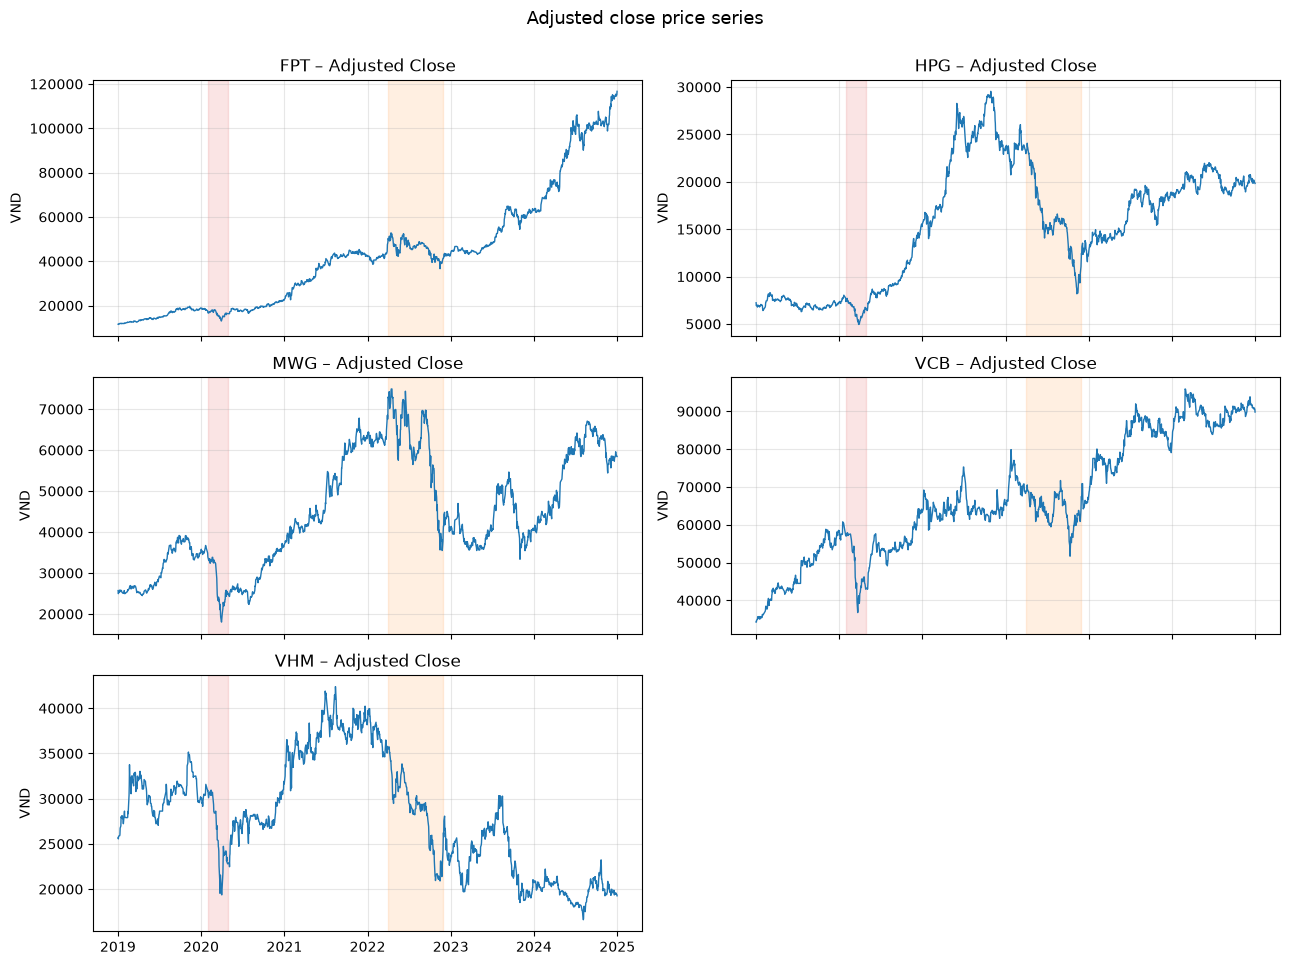

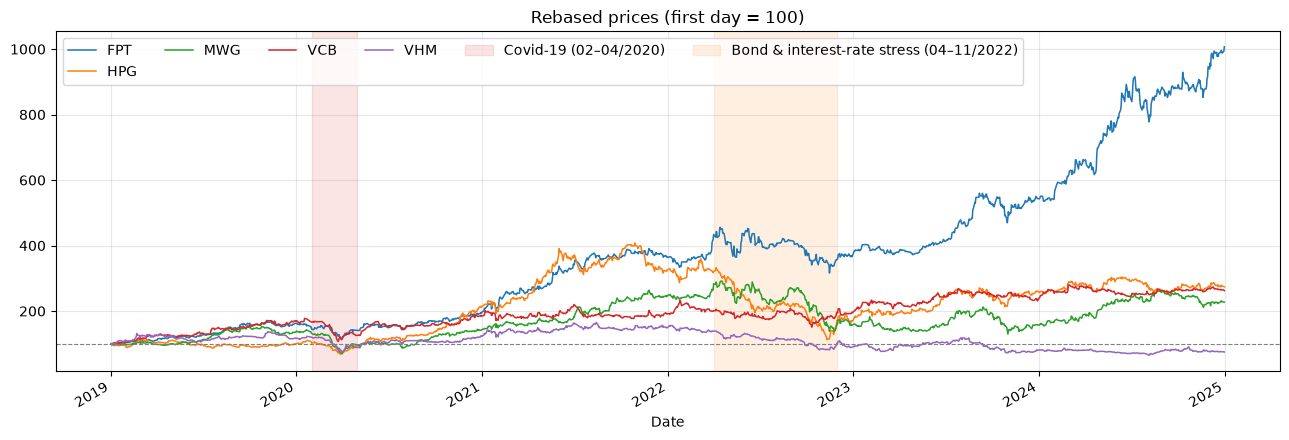

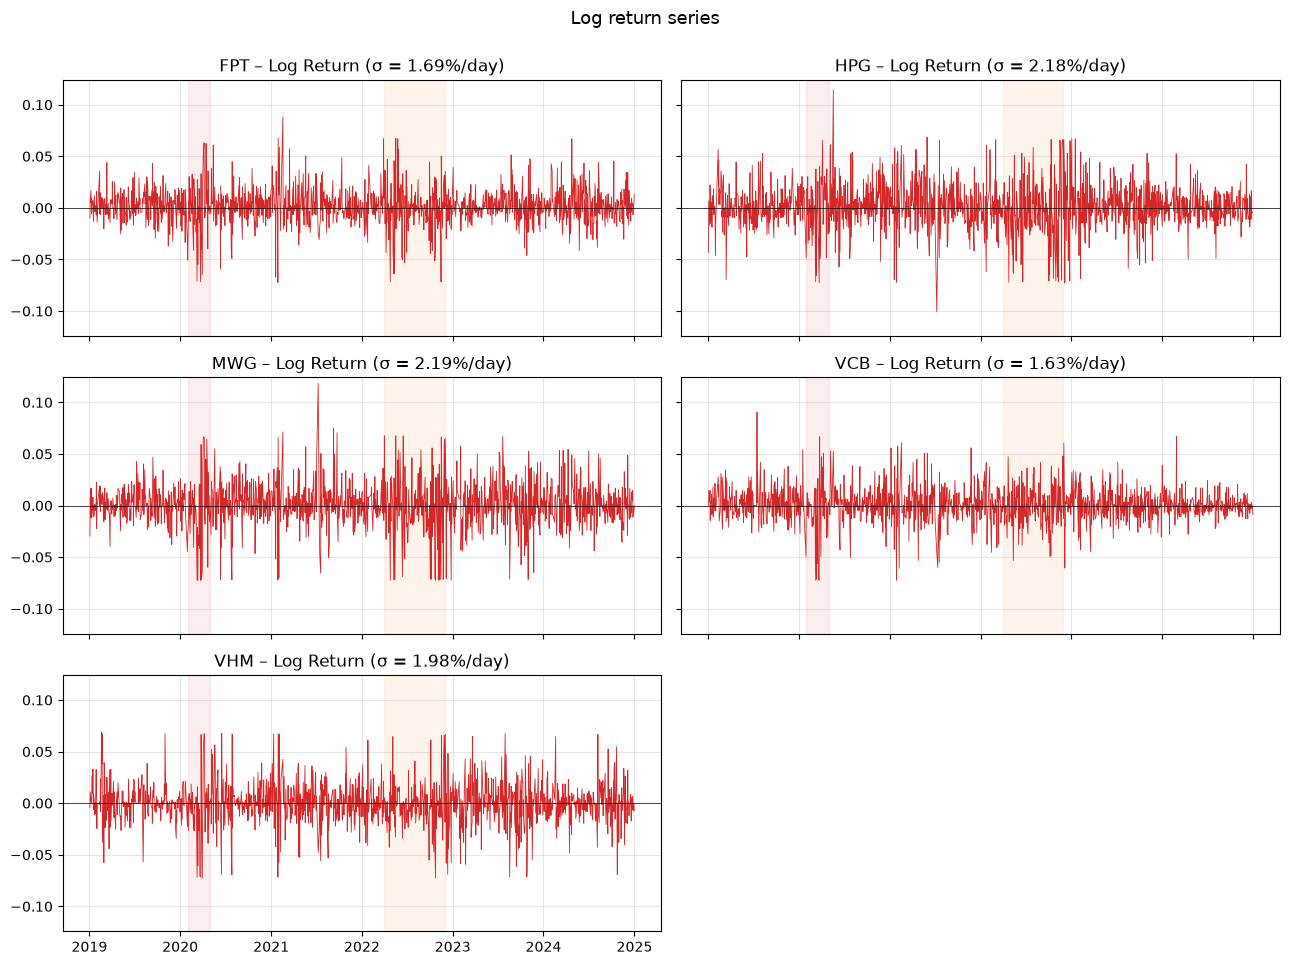

In [7]:
# ===================== 1.3 LOG RETURNS + PLOTS =====================
log_ret = np.log(prices / prices.shift(1)).iloc[1:]          # r_t = ln(P_t / P_{t-1})
log_ret.index.name = "Date"
T = len(log_ret)
print(f"Log return: {T} sessions × {N} tickers | {log_ret.index.min().date()} -> {log_ret.index.max().date()} "
      f"| NaN: {int(log_ret.isna().sum().sum())}")
display(log_ret.head())
log_ret.to_csv(OUT["TV1"] / "log_returns.csv", encoding="utf-8-sig")

# (a) Price series – one panel per ticker because price scales differ
fig, axes = grid_axes(N, sharex=True)
for ax, tk in zip(axes, tickers):
    ax.plot(prices.index, prices[tk], lw=1, color="tab:blue")
    shade_stress(ax, label=False)
    ax.set_title(f"{tk} – Adjusted Close"); ax.set_ylabel("VND"); ax.grid(alpha=0.3)
fig.suptitle("Adjusted close price series", fontsize=13, y=1.0)
plt.tight_layout(); plt.savefig(OUT["TV1"] / "1_price_series.png", dpi=150, bbox_inches="tight"); plt.show()

# (b) Prices rebased to 100 on the first day for comparison on one axis
ax = (prices / prices.iloc[0] * 100).plot(figsize=(13, 4.5), lw=1.1)
shade_stress(ax); ax.axhline(100, color="grey", ls="--", lw=0.8)
ax.set_title("Rebased prices (first day = 100)"); ax.grid(alpha=0.3); ax.legend(ncol=6)
plt.tight_layout(); plt.savefig(OUT["TV1"] / "1_price_normalized.png", dpi=150); plt.show()

# (c) Return series – common y-axis to compare volatility
ylim = log_ret.abs().max().max() * 1.05
fig, axes = grid_axes(N, sharex=True, sharey=True)
for ax, tk in zip(axes, tickers):
    ax.plot(log_ret.index, log_ret[tk], lw=0.6, color="tab:red")
    shade_stress(ax, alpha=0.08, label=False)
    ax.axhline(0, color="black", lw=0.5); ax.set_ylim(-ylim, ylim)
    ax.set_title(f"{tk} – Log Return (σ = {log_ret[tk].std():.2%}/day)"); ax.grid(alpha=0.3)
fig.suptitle("Log return series", fontsize=13, y=1.0)
plt.tight_layout(); plt.savefig(OUT["TV1"] / "1_return_series.png", dpi=150, bbox_inches="tight"); plt.show()

## 1.4a Descriptive statistics

,N,Mean,Std,Skewness,Kurtosis,Excess Kurtosis,Min,Median,Max,Annual mean,Annual std
FPT,1453.0,0.00159,0.01693,0.00296,6.53547,3.53547,-0.07240,0.00107,0.08853,0.40057,0.26869
HPG,1453.0,0.00069,0.02181,-0.04090,5.30991,2.30991,-0.10049,0.00000,0.11430,0.17473,0.34627
MWG,1453.0,0.00056,0.02188,-0.21942,5.74471,2.74471,-0.07253,0.00000,0.11835,0.14232,0.34727
VCB,1453.0,0.00066,0.01633,-0.03764,6.45354,3.45354,-0.07248,0.00000,0.09060,0.16708,0.25925
VHM,1453.0,-0.00020,0.01982,0.02418,5.77185,2.77185,-0.07257,0.00000,0.06899,-0.04976,0.31456


FPT: S = +0.003 (right-skewed), K = 6.535 (fatter tails than normal)
HPG: S = -0.041 (left-skewed), K = 5.310 (fatter tails than normal)
MWG: S = -0.219 (left-skewed), K = 5.745 (fatter tails than normal)
VCB: S = -0.038 (left-skewed), K = 6.454 (fatter tails than normal)
VHM: S = +0.024 (right-skewed), K = 5.772 (fatter tails than normal)


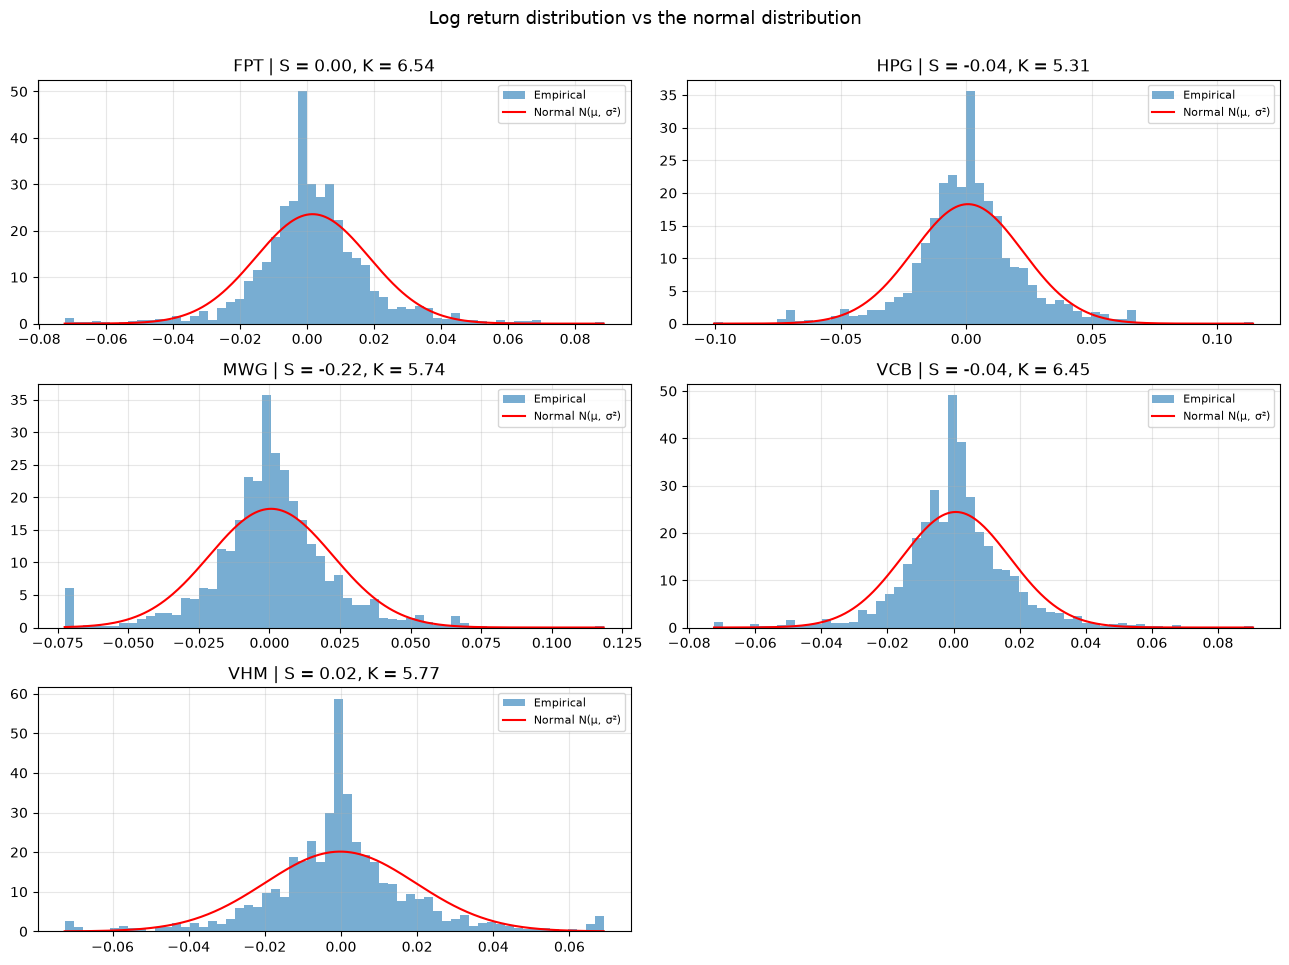

In [8]:
# ===================== 1.4a DESCRIPTIVE STATISTICS =====================
def describe_returns(r: pd.DataFrame) -> pd.DataFrame:
    rows = {}
    for tk in r.columns:
        x = r[tk].dropna().values
        S = stats.skew(x, bias=True)
        K = stats.kurtosis(x, fisher=False, bias=True)        # regular kurtosis (normal = 3)
        rows[tk] = {"N": len(x), "Mean": x.mean(), "Std": x.std(ddof=1), "Skewness": S, "Kurtosis": K,
                    "Excess Kurtosis": K - 3, "Min": x.min(), "Median": np.median(x), "Max": x.max(),
                    "Annual mean": x.mean() * TRADING_DAYS, "Annual std": x.std(ddof=1) * np.sqrt(TRADING_DAYS)}
    return pd.DataFrame(rows).T


desc = describe_returns(log_ret)
display(desc.astype(float).round(5))
for tk, row in desc.iterrows():
    print(f"{tk}: S = {row['Skewness']:+.3f} ({'left-skewed' if row['Skewness'] < 0 else 'right-skewed'}), "
          f"K = {row['Kurtosis']:.3f} ({'fatter tails than normal' if row['Kurtosis'] > 3 else 'thin tails'})")

# Histogram vs a normal distribution with the same mean & std
fig, axes = grid_axes(N)
for ax, tk in zip(axes, tickers):
    x = log_ret[tk]
    ax.hist(x, bins=60, density=True, alpha=0.6, label="Empirical")
    xs = np.linspace(x.min(), x.max(), 400)
    ax.plot(xs, stats.norm.pdf(xs, x.mean(), x.std()), "r-", lw=1.5, label="Normal N(μ, σ²)")
    ax.set_title(f"{tk} | S = {desc.loc[tk, 'Skewness']:.2f}, K = {desc.loc[tk, 'Kurtosis']:.2f}")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle("Log return distribution vs the normal distribution", fontsize=13, y=1.0)
plt.tight_layout(); plt.savefig(OUT["TV1"] / "1_histogram.png", dpi=150, bbox_inches="tight"); plt.show()

## 1.4b Normality tests: Jarque-Bera & QQ-plot

,n,Skewness,Kurtosis,JB,p-value,JB (scipy),Critical value χ²(2),Conclusion
FPT,1453.0,0.002960,6.535474,756.747122,4.725527e-165,756.747122,5.991465,Reject H0 – NOT normal
HPG,1453.0,-0.040903,5.309909,323.435988,5.844771e-71,323.435988,5.991465,Reject H0 – NOT normal
MWG,1453.0,-0.219420,5.744713,467.746791,2.691998e-102,467.746791,5.991465,Reject H0 – NOT normal
VCB,1453.0,-0.037635,6.453535,722.417710,1.345821e-157,722.417710,5.991465,Reject H0 – NOT normal
VHM,1453.0,0.024178,5.771850,465.292372,9.184283e-102,465.292372,5.991465,Reject H0 – NOT normal


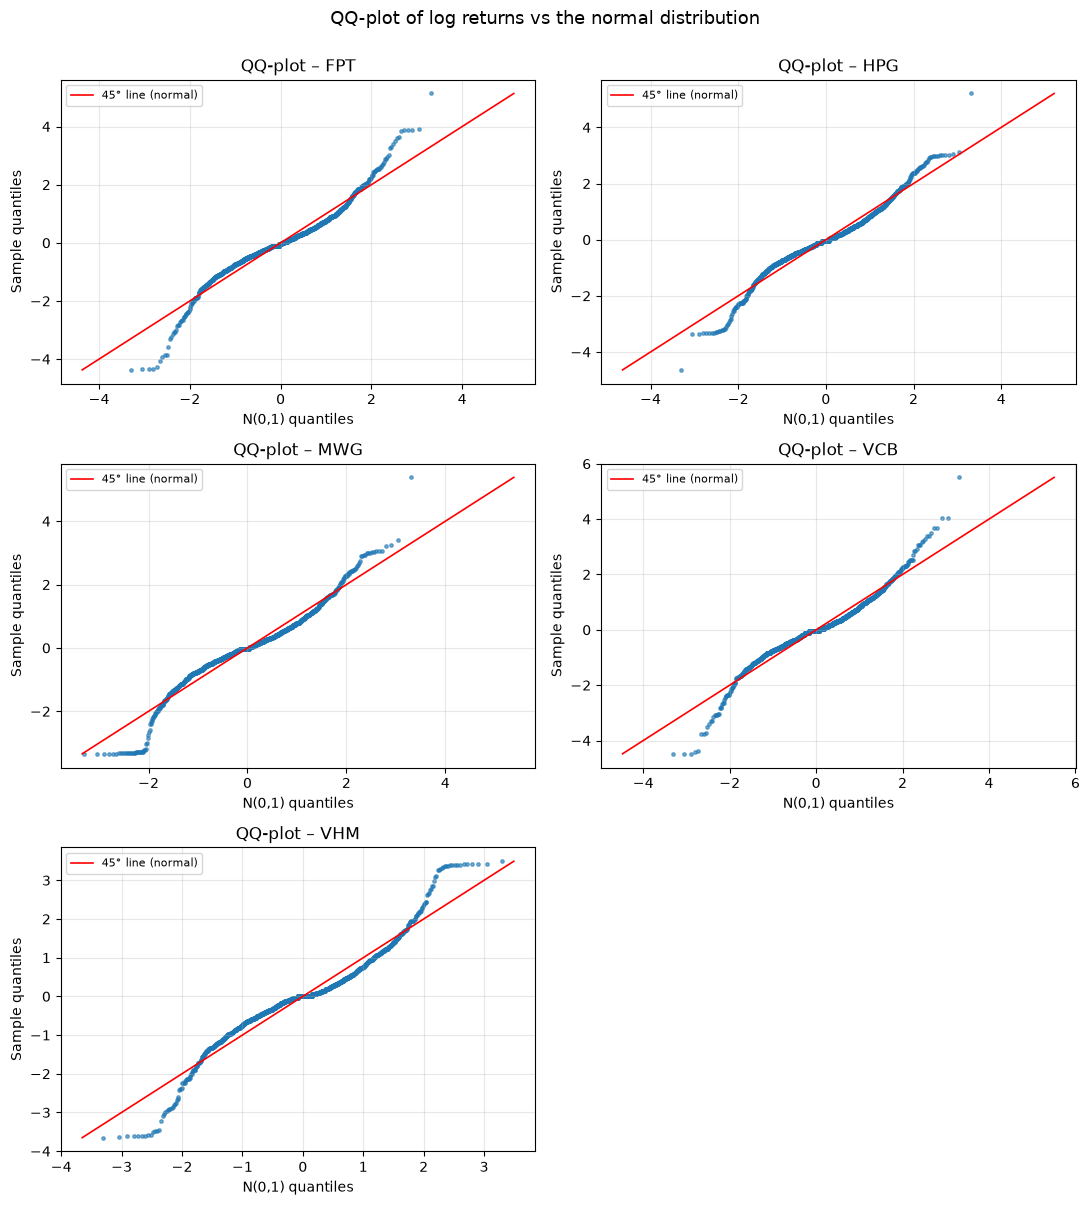

In [9]:
# ===================== 1.4b JARQUE-BERA + QQ-PLOT =====================
def jarque_bera(x):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    n = len(x)
    S = stats.skew(x, bias=True)
    K = stats.kurtosis(x, fisher=False, bias=True)
    jb = n / 6 * (S ** 2 + (K - 3) ** 2 / 4)
    return n, S, K, jb, stats.chi2.sf(jb, df=2)


crit_jb = stats.chi2.ppf(1 - ALPHA, df=2)
jb_table = pd.DataFrame({tk: dict(zip(["n", "Skewness", "Kurtosis", "JB", "p-value"], jarque_bera(log_ret[tk])))
                         for tk in tickers}).T
jb_table["JB (scipy)"] = [stats.jarque_bera(log_ret[tk]).statistic for tk in tickers]
jb_table["Critical value χ²(2)"] = crit_jb
jb_table["Conclusion"] = np.where(jb_table["p-value"].astype(float) < ALPHA, "Reject H0 – NOT normal", "Fail to reject – normal")
display(jb_table)

fig, axes = grid_axes(N, h=4, w=11)
for ax, tk in zip(axes, tickers):
    z = (log_ret[tk] - log_ret[tk].mean()) / log_ret[tk].std()
    (osm, osr), _ = stats.probplot(z, dist="norm")
    ax.scatter(osm, osr, s=6, alpha=0.6)
    lim = [min(osm.min(), osr.min()), max(osm.max(), osr.max())]
    ax.plot(lim, lim, "r-", lw=1.2, label="45° line (normal)")
    ax.set_title(f"QQ-plot – {tk}"); ax.set_xlabel("N(0,1) quantiles"); ax.set_ylabel("Sample quantiles")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle("QQ-plot of log returns vs the normal distribution", fontsize=13, y=1.0)
plt.tight_layout(); plt.savefig(OUT["TV1"] / "1_qqplot.png", dpi=150, bbox_inches="tight"); plt.show()

## 1.4c Stationarity tests: ADF & KPSS

In [10]:
# ===================== 1.4c ADF & KPSS =====================
def _adf_manual(x, maxlag=None):
    """ADF with constant, lag chosen by AIC. Returns (stat, p=NaN, lag, approximate MacKinnon 5% critical value)."""
    x = np.asarray(x, float)
    dx = np.diff(x)
    maxlag = maxlag or int(np.ceil(12 * (len(x) / 100) ** 0.25))
    best = None
    for p in range(maxlag + 1):
        y = dx[maxlag:]
        X = [np.ones_like(y), x[maxlag:-1]] + [dx[maxlag - j:-j] for j in range(1, p + 1)]
        X = np.column_stack(X)
        beta, *_ = np.linalg.lstsq(X, y, rcond=None)
        resid = y - X @ beta
        n = len(y)
        aic = n * np.log(resid @ resid / n) + 2 * X.shape[1]
        if best is None or aic < best[0]:
            s2 = resid @ resid / (n - X.shape[1])
            se = np.sqrt(s2 * np.linalg.inv(X.T @ X)[1, 1])
            best = (aic, beta[1] / se, p)
    tau = best[1]
    p_approx = 0.01 if tau < -3.43 else 0.05 if tau < -2.86 else 0.10 if tau < -2.57 else 0.5
    return tau, p_approx, best[2], -2.86


def _kpss_manual(x):
    """KPSS (level) with Bartlett long-run variance, lag =  int(12 (T/100)^{1/4})."""
    x = np.asarray(x, float)
    e = x - x.mean()
    n = len(e)
    L = int(12 * (n / 100) ** 0.25)
    s2 = e @ e / n
    for k in range(1, L + 1):
        s2 += 2 * (1 - k / (L + 1)) * (e[k:] @ e[:-k]) / n
    stat = (np.cumsum(e) ** 2).sum() / (n ** 2 * s2)
    p = float(np.interp(stat, [0.347, 0.463, 0.574, 0.739], [0.10, 0.05, 0.025, 0.01]))
    return stat, p, L, 0.463


def adf_test(x):
    x = pd.Series(x).dropna()
    if HAS_SM:
        stat, p, lag, _, cv, _ = adfuller(x, regression="c", autolag="AIC")
        return {"ADF stat": stat, "ADF p-value": p, "ADF lag": lag, "ADF CV 5%": cv["5%"]}
    stat, p, lag, cv = _adf_manual(x.values)
    return {"ADF stat": stat, "ADF p-value": p, "ADF lag": lag, "ADF CV 5%": cv}


def kpss_test(x):
    x = pd.Series(x).dropna()
    if HAS_SM:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", InterpolationWarning)
            stat, p, lag, cv = kpss(x, regression="c", nlags="auto")
    else:
        stat, p, lag, cv = _kpss_manual(x.values)
        cv = {"5%": cv}
    # the KPSS table only covers p in [0.01, 0.10] -> p at the boundary means "< 0.01" or "> 0.10"
    note = "< 0.01" if p <= 0.01 else ("> 0.10" if p >= 0.10 else f"{p:.3f}")
    return {"KPSS stat": stat, "KPSS p-value": p, "KPSS p (for report)": note, "KPSS lag": lag, "KPSS CV 5%": cv["5%"]}


def stationarity_verdict(p_adf, p_kpss):
    adf_rej, kpss_rej = p_adf < ALPHA, p_kpss < ALPHA
    if adf_rej and not kpss_rej:
        return "STATIONARY"
    if not adf_rej and kpss_rej:
        return "NON-STATIONARY"
    return "Conflicting (needs a closer look)"


rows = []
for name, df in {"Price (Adj Close)": prices, "Log return": log_ret}.items():
    for tk in tickers:
        res = {"Series": name, "Ticker": tk, **adf_test(df[tk]), **kpss_test(df[tk])}
        res["Conclusion"] = stationarity_verdict(res["ADF p-value"], res["KPSS p-value"])
        rows.append(res)
stationarity = pd.DataFrame(rows).set_index(["Series", "Ticker"])
display(stationarity.round(4))

ADF stat  ADF p-value  ADF lag  ADF CV 5%  KPSS stat  KPSS p-value KPSS p (for report)  KPSS lag  KPSS CV 5%      Conclusion
Series            Ticker                                                                                                                              
Price (Adj Close) FPT       2.1078       0.9988        7    -2.8635     4.8476          0.01              < 0.01        25       0.463  NON-STATIONARY
                  HPG      -1.5501       0.5086       13    -2.8635     2.5694          0.01              < 0.01        25       0.463  NON-STATIONARY
                  MWG      -1.5780       0.4946        2    -2.8635     2.5382          0.01              < 0.01        25       0.463  NON-STATIONARY
                  VCB      -1.6460       0.4591        3    -2.8635     5.1010          0.01              < 0.01        25       0.463  NON-STATIONARY
                  VHM      -1.4364       0.5647        0    -2.8635     2.5563          0.01              < 0.01        25       0.463  NON-STATIONARY
Log return        FPT     -28.2590       0.0000        1    -2.8635     0.0696          0.10              > 0.10         9       0.463      STATIONARY
                  HPG     -36.4743       0.0000        0    -2.8635     0.1787          0.10              > 0.10         2       0.463      STATIONARY
                  MWG     -35.3074       0.0000        0    -2.8635     0.0941          0.10              > 0.10         0       0.463      STATIONARY
                  VCB     -10.5162       0.0000       15    -2.8636     0.0926          0.10              > 0.10         3       0.463      STATIONARY
                  VHM     -35.3097       0.0000        0    -2.8635     0.1257          0.10              > 0.10         8       0.463      STATIONARY

## 1.4d Autocorrelation: ACF & Ljung-Box on $r_t$, $|r_t|$, $r_t^2$

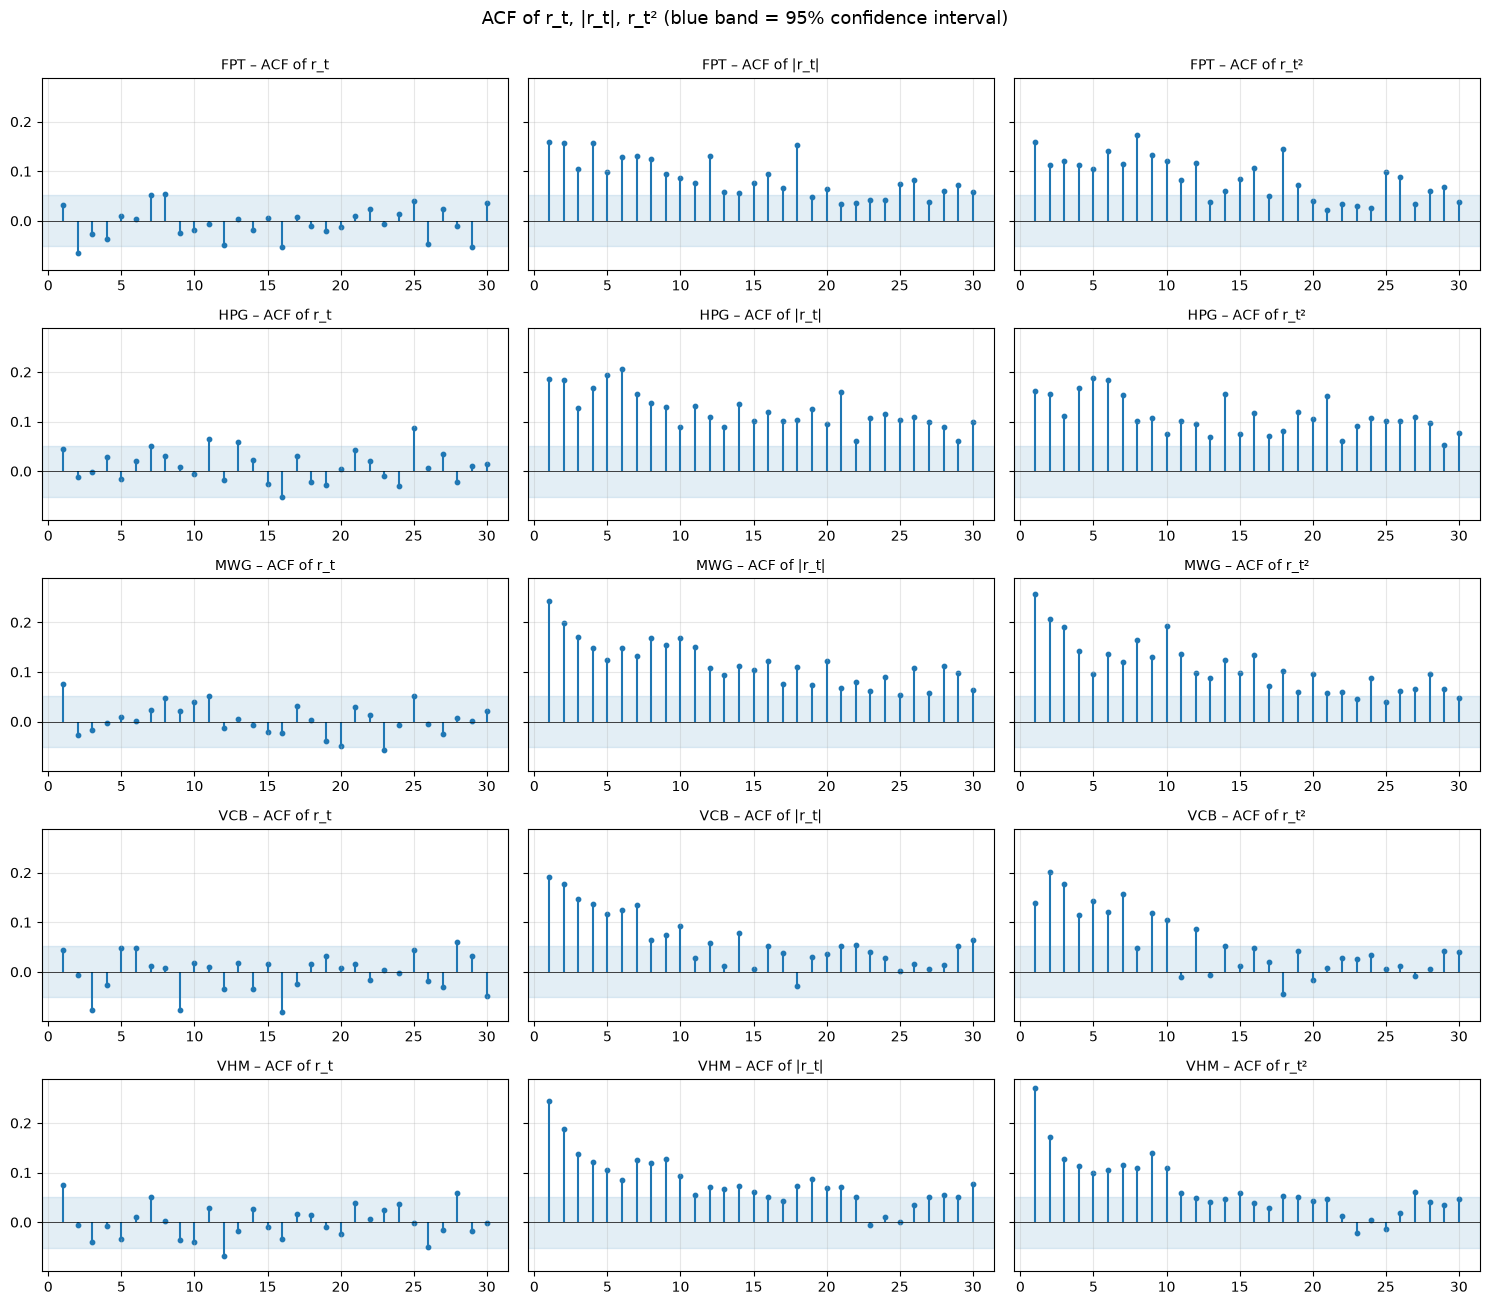

p (lag 5)  p (lag 10)  p (lag 20)
Ticker Series                                   
FPT    r_t        0.0584      0.0243      0.0751
       |r_t|      0.0000      0.0000      0.0000
       r_t²       0.0000      0.0000      0.0000
HPG    r_t        0.4683      0.4082      0.0580
       |r_t|      0.0000      0.0000      0.0000
       r_t²       0.0000      0.0000      0.0000
MWG    r_t        0.0760      0.0763      0.0708
       |r_t|      0.0000      0.0000      0.0000
       r_t²       0.0000      0.0000      0.0000
VCB    r_t        0.0062      0.0013      0.0008
       |r_t|      0.0000      0.0000      0.0000
       r_t²       0.0000      0.0000      0.0000
VHM    r_t        0.0292      0.0220      0.0258
       |r_t|      0.0000      0.0000      0.0000
       r_t²       0.0000      0.0000      0.0000

In [11]:
# ===================== 1.4d ACF + LJUNG-BOX =====================
def acf(x, nlags):
    """Sample autocorrelation coefficients ρ_1..ρ_nlags."""
    x = np.asarray(x, float); x = x - x.mean()
    denom = x @ x
    return np.array([(x[k:] @ x[:-k]) / denom for k in range(1, nlags + 1)])


def ljung_box(x, lags):
    """Ljung-Box Q(m) and p-value for each m in lags."""
    x = np.asarray(pd.Series(x).dropna(), float)
    n = len(x)
    rho = acf(x, max(lags))
    out = {}
    for m in lags:
        Q = n * (n + 2) * np.sum(rho[:m] ** 2 / (n - np.arange(1, m + 1)))
        out[m] = {"Q": Q, "p-value": stats.chi2.sf(Q, m)}
    return pd.DataFrame(out).T


ACF_LAGS = 30
transforms = {"r_t": lambda s: s, "|r_t|": lambda s: s.abs(), "r_t²": lambda s: s ** 2}
band = 1.96 / np.sqrt(T)
fig, axes = plt.subplots(N, 3, figsize=(15, 2.6 * N), squeeze=False, sharey=True)
for i, tk in enumerate(tickers):
    for j, (name, f) in enumerate(transforms.items()):
        ax = axes[i, j]
        rho = acf(f(log_ret[tk]), ACF_LAGS)
        ax.vlines(range(1, ACF_LAGS + 1), 0, rho, color="tab:blue")
        ax.scatter(range(1, ACF_LAGS + 1), rho, s=10, color="tab:blue")
        ax.axhspan(-band, band, color="tab:blue", alpha=0.12)
        ax.axhline(0, color="black", lw=0.5)
        ax.set_title(f"{tk} – ACF of {name}", fontsize=10); ax.grid(alpha=0.3)
fig.suptitle("ACF of r_t, |r_t|, r_t² (blue band = 95% confidence interval)", fontsize=13, y=1.0)
plt.tight_layout(); plt.savefig(OUT["TV1"] / "1_acf.png", dpi=150, bbox_inches="tight"); plt.show()

rows = []
for tk in tickers:
    for name, f in transforms.items():
        for m, r in ljung_box(f(log_ret[tk]), LB_LAGS).iterrows():
            rows.append({"Ticker": tk, "Series": name, "Lag": int(m), "Q-stat": r["Q"], "p-value": r["p-value"],
                         "Conclusion": "Autocorrelated" if r["p-value"] < ALPHA else "No"})
ljungbox = pd.DataFrame(rows)
lb_pivot = ljungbox.pivot_table(index=["Ticker", "Series"], columns="Lag", values="p-value", sort=False)
lb_pivot.columns = [f"p (lag {c})" for c in lb_pivot.columns]
display(lb_pivot.round(4))

## 1.4e ARCH-LM test

In [12]:
# ===================== 1.4e ARCH-LM =====================
def arch_lm(x, m):
    """ARCH-LM: regress e_t² on a constant and m lags of e²; LM = (n − m)·R² ~ χ²(m) under H0."""
    x = np.asarray(x, float)
    e2 = (x - x.mean()) ** 2
    y = e2[m:]
    X = np.column_stack([np.ones(len(y))] + [e2[m - k:-k] for k in range(1, m + 1)])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    r2 = 1 - (resid @ resid) / ((y - y.mean()) @ (y - y.mean()))
    lm = len(y) * r2
    return lm, stats.chi2.sf(lm, m)


rows = []
for tk in tickers:
    for m in LB_LAGS:
        lm, p = arch_lm(log_ret[tk].values, m)
        rows.append({"Ticker": tk, "Lag": m, "LM": lm, "p-value": p,
                     "Conclusion": "ARCH effect present" if p < ALPHA else "No"})
archlm = pd.DataFrame(rows)
piv = archlm.pivot_table(index="Ticker", columns="Lag", values="p-value", sort=False)
piv.columns = [f"p (lag {c})" for c in piv.columns]
display(piv.round(4))
n_arch = int(((archlm["Lag"] == 10) & (archlm["p-value"] < ALPHA)).sum()) if 10 in LB_LAGS else int((archlm["p-value"] < ALPHA).sum())
print(f"ARCH-LM rejects H0 (no ARCH) for {n_arch}/{N} tickers -> confirms volatility clustering, GARCH needed.")
archlm.to_csv(OUT["TV1"] / "1_arch_lm.csv", index=False, encoding="utf-8-sig")


,p (lag 5),p (lag 10),p (lag 20)
Ticker,,,
FPT,0.0,0.0,0.0
HPG,0.0,0.0,0.0
MWG,0.0,0.0,0.0
VCB,0.0,0.0,0.0
VHM,0.0,0.0,0.0


ARCH-LM rejects H0 (no ARCH) for 5/5 tickers -> confirms volatility clustering, GARCH needed.


## 1.4f Conditional mean: ARMA(p,q) selected by BIC

In [13]:
# ===================== 1.4f ARMA(p,q) THEO BIC =====================
def _arma_resid(th, y, p, q):
    mu, phi, theta = th[0], th[1:1 + p], th[1 + p:]
    return lfilter(np.r_[1.0, -phi], np.r_[1.0, theta], y - mu)          # ε_t from (y-μ), ε_0.. = 0


def arma_css(y, p, q):
    """ARMA(p,q) with constant, conditional sum of squares (CSS). Returns (parameters, residuals, σ², approximate loglik, BIC, AIC)."""
    y = np.asarray(y, float); n = len(y)

    def sse(th):
        phi, theta = th[1:1 + p], th[1 + p:]
        if p and np.any(np.abs(np.roots(np.r_[1.0, -phi])) >= 0.999):       # stationarity condition
            return 1e12
        if q and np.any(np.abs(np.roots(np.r_[1.0, theta])) >= 0.999):      # invertibility condition
            return 1e12
        e = _arma_resid(th, y, p, q)
        return e @ e

    x0 = np.r_[y.mean(), np.zeros(p + q)]
    th = x0 if p + q == 0 else minimize(sse, x0, method="Nelder-Mead",
                                       options={"xatol": 1e-6, "fatol": 1e-10, "maxiter": 5000}).x
    e = _arma_resid(th, y, p, q)
    s2 = e @ e / n
    ll = -0.5 * n * (np.log(2 * np.pi) + np.log(s2) + 1)
    k = p + q + 2                                                            # μ, φ, θ and σ²
    return th, e, s2, ll, -2 * ll + k * np.log(n), -2 * ll + 2 * k


ARMA_MAX = 2
rows, resid_best = [], {}
for tk in tickers:
    y = log_ret[tk].values * SCALE
    grid = []
    for p_ in range(ARMA_MAX + 1):
        for q_ in range(ARMA_MAX + 1):
            th, e, s2, ll, bic, aic = arma_css(y, p_, q_)
            grid.append({"p": p_, "q": q_, "BIC": bic, "AIC": aic, "e": e})
    g = pd.DataFrame(grid)
    best_i = g["BIC"].idxmin()
    p_b, q_b = int(g.loc[best_i, "p"]), int(g.loc[best_i, "q"])
    bic00 = float(g[(g["p"] == 0) & (g["q"] == 0)]["BIC"].iloc[0])
    d_bic = bic00 - float(g.loc[best_i, "BIC"])
    e_b = g.loc[best_i, "e"]
    m_lb = 10
    Q = float(ljung_box(e_b, [m_lb]).loc[m_lb, "Q"])
    df_lb = m_lb - p_b - q_b
    p_lb = stats.chi2.sf(Q, df_lb) if df_lb > 0 else np.nan
    if (p_b, q_b) == (0, 0) or d_bic < 2:
        verdict = "Keep constant mean (ARMA does not improve materially)"
    else:
        verdict = f"ARMA({p_b},{q_b}) clearly better (ΔBIC = {d_bic:.1f}) – consider ARMA-GARCH"
    if p_lb == p_lb and p_lb < ALPHA:                                       # p_lb is NaN if df ≤ 0
        verdict += f" | residual LB p = {p_lb:.3f} < {ALPHA}: mild autocorrelation remains"
    rows.append({"Ticker": tk, "Best ARMA (BIC)": f"({p_b},{q_b})", "BIC": float(g.loc[best_i, "BIC"]),
                 "BIC ARMA(0,0)": bic00, "ΔBIC vs (0,0)": d_bic, f"LB({m_lb}) residual p": p_lb, "Conclusion": verdict})
mean_tbl = pd.DataFrame(rows).set_index("Ticker")

if HAS_SM:                                                                   # cross-check with statsmodels ARIMA (MLE)
    try:
        from statsmodels.tsa.arima.model import ARIMA
        sm_pick = {}
        for tk in tickers:
            y = log_ret[tk].values * SCALE
            bics = {(p_, q_): ARIMA(y, order=(p_, 0, q_)).fit().bic
                    for p_ in range(ARMA_MAX + 1) for q_ in range(ARMA_MAX + 1)}
            b = min(bics, key=bics.get)
            sm_pick[tk] = f"({b[0]},{b[1]})"
        mean_tbl["ARMA theo statsmodels"] = pd.Series(sm_pick)
    except Exception as ex:
        print("[!] Skipping statsmodels cross-check:", ex)

display(mean_tbl.round(4))
n_const = int(mean_tbl["Conclusion"].str.startswith("Keep").sum())
print(f"{n_const}/{N} tickers: a constant mean is enough -> using mean = const in GARCH (section 2) is reasonable."
      + ("" if n_const == N else " The remaining tickers could be extended to ARMA-GARCH."))
mean_tbl.to_csv(OUT["TV1"] / "1_arma_selection.csv", encoding="utf-8-sig")


d:\Anaconda\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
d:\Anaconda\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
d:\Anaconda\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
d:\Anaconda\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


,Best ARMA (BIC),BIC,"BIC ARMA(0,0)","ΔBIC vs (0,0)",LB(10) residual p,Conclusion,ARMA theo statsmodels
Ticker,,,,,,,
FPT,"(0,0)",5666.2762,5666.2762,0.0000,0.0243,Keep constant mean (ARMA does not improve mate...,"(0,0)"
HPG,"(0,0)",6403.4209,6403.4209,0.0000,0.4082,Keep constant mean (ARMA does not improve mate...,"(0,0)"
MWG,"(0,1)",6410.1656,6411.8339,1.6683,0.6541,Keep constant mean (ARMA does not improve mate...,"(0,1)"
VCB,"(0,0)",5562.4178,5562.4178,0.0000,0.0013,Keep constant mean (ARMA does not improve mate...,"(0,0)"
VHM,"(0,1)",6123.2804,6124.3703,1.0900,0.2115,Keep constant mean (ARMA does not improve mate...,"(0,1)"


5/5 tickers: a constant mean is enough -> using mean = const in GARCH (section 2) is reasonable.


## 1.5 Summary of stylized facts: fat tails & volatility clustering

In [14]:
# ===================== 1.5 SUMMARY OF STYLIZED FACTS =====================
max_lag = max(LB_LAGS)
lb_at = lambda name: ljungbox[(ljungbox["Series"] == name) & (ljungbox["Lag"] == max_lag)].set_index("Ticker")["p-value"]
evidence = pd.DataFrame(index=tickers)
evidence["Kurtosis"] = desc["Kurtosis"].astype(float)
evidence["JB p-value"] = jb_table["p-value"].astype(float)
evidence["Fat tails?"] = np.where((evidence["Kurtosis"] > 3) & (evidence["JB p-value"] < ALPHA), "YES", "no")
evidence[f"LB p r_t (lag {max_lag})"] = lb_at("r_t")
evidence[f"LB p r_t² (lag {max_lag})"] = lb_at("r_t²")
evidence["Vol clustering?"] = np.where(lb_at("r_t²") < ALPHA, "YES", "no")
evidence["Autocorrelation of r_t?"] = np.where(lb_at("r_t") < ALPHA, "YES (mild)", "no")   # conclusion based on lag 20
sig_lags = ljungbox[(ljungbox["Series"] == "r_t") & (ljungbox["p-value"] < ALPHA)].groupby("Ticker")["Lag"].apply(
    lambda s: ", ".join(map(str, s)))
evidence["LB r_t significant at lag"] = sig_lags.reindex(tickers).fillna("no lag")
evidence["% days r_t = 0"] = (log_ret == 0).mean() * 100
evidence["Price"] = stationarity.xs("Price (Adj Close)", level="Series")["Conclusion"]
evidence["Return"] = stationarity.xs("Log return", level="Series")["Conclusion"]
display(evidence.round(4))

print(f"• Fat tails for {(evidence['Fat tails?'] == 'YES').sum()}/{N} tickers -> use the Student-t distribution (Part 2) and VaR-t (Part 4).")
print(f"• Volatility clustering for {(evidence['Vol clustering?'] == 'YES').sum()}/{N} tickers -> GARCH/GJR-GARCH needed (Part 2).")
print("• Price: " + ", ".join(f"{k}={v}" for k, v in evidence["Price"].items()))
print("• Return: " + ", ".join(f"{k}={v}" for k, v in evidence["Return"].items())
      + " -> all later models are estimated on log returns.")
ac_tk = evidence.index[evidence["Autocorrelation of r_t?"] != "no"].tolist()
if ac_tk:
    print(f"• Returns still show mild autocorrelation for {', '.join(ac_tk)} (share of days with r_t = 0: "
          + ", ".join(f"{t} = {evidence.loc[t, '% days r_t = 0']:.1f}%" for t in ac_tk)
          + ") -> likely due to thin trading; re-check Ljung-Box on the ε residuals in Part 2.")
weak = [t for t in tickers if t not in ac_tk and evidence.loc[t, "LB r_t significant at lag"] != "no lag"]
if weak:
    print("• Very weak autocorrelation (significant only at a few lags, not at lag 20): "
          + ", ".join(f"{t} (lag {evidence.loc[t, 'LB r_t significant at lag']})" for t in weak)
          + " -> the summary table's conclusion is based on lag 20.")

with pd.ExcelWriter(OUT["TV1"] / "TV1_statistical_tests.xlsx", engine="openpyxl") as xw:
    evidence.to_excel(xw, sheet_name="Tong_hop")
    desc.to_excel(xw, sheet_name="Thong_ke_mo_ta")
    jb_table.to_excel(xw, sheet_name="Jarque_Bera")
    stationarity.to_excel(xw, sheet_name="ADF_KPSS")
    ljungbox.to_excel(xw, sheet_name="Ljung_Box", index=False)
print("✔ Saved", OUT["TV1"] / "TV1_statistical_tests.xlsx")

,Kurtosis,JB p-value,Fat tails?,LB p r_t (lag 20),LB p r_t² (lag 20),Vol clustering?,Autocorrelation of r_t?,LB r_t significant at lag,% days r_t = 0,Price,Return
FPT,6.5355,0.0,YES,0.0751,0.0,YES,no,10,6.6070,NON-STATIONARY,STATIONARY
HPG,5.3099,0.0,YES,0.0580,0.0,YES,no,no lag,5.9876,NON-STATIONARY,STATIONARY
MWG,5.7447,0.0,YES,0.0708,0.0,YES,no,no lag,7.0200,NON-STATIONARY,STATIONARY
VCB,6.4535,0.0,YES,0.0008,0.0,YES,YES (mild),"5, 10, 20",9.2911,NON-STATIONARY,STATIONARY
VHM,5.7718,0.0,YES,0.0258,0.0,YES,YES (mild),"5, 10, 20",9.4288,NON-STATIONARY,STATIONARY


• Fat tails for 5/5 tickers -> use the Student-t distribution (Part 2) and VaR-t (Part 4).
• Volatility clustering for 5/5 tickers -> GARCH/GJR-GARCH needed (Part 2).
• Price: FPT=NON-STATIONARY, HPG=NON-STATIONARY, MWG=NON-STATIONARY, VCB=NON-STATIONARY, VHM=NON-STATIONARY
• Return: FPT=STATIONARY, HPG=STATIONARY, MWG=STATIONARY, VCB=STATIONARY, VHM=STATIONARY -> all later models are estimated on log returns.
• Returns still show mild autocorrelation for VCB, VHM (share of days with r_t = 0: VCB = 9.3%, VHM = 9.4%) -> likely due to thin trading; re-check Ljung-Box on the ε residuals in Part 2.
• Very weak autocorrelation (significant only at a few lags, not at lag 20): FPT (lag 10) -> the summary table's conclusion is based on lag 20.
✔ Saved D:\Năm 3\Ứng dụng công nghệ trong TCNH\final 2\ouput\TV1_Data_EDA\TV1_statistical_tests.xlsx


---
# PART 2: UNIVARIATE GARCH MARGINS
## 2.1 GARCH(1,1) & GJR-GARCH(1,1) with Normal and Student-t innovations

In [15]:
# ===================== 2.1 HAND-WRITTEN GARCH / GJR-GARCH FUNCTIONS =====================
def unpack(params, gjr, dist):
    """Split the parameter vector [mu, omega, alpha, (gamma), beta, (nu)]."""
    mu, omega, alpha = params[0], params[1], params[2]
    gamma = params[3] if gjr else 0.0
    beta = params[4] if gjr else params[3]
    nu = params[-1] if dist == "t" else np.inf
    return mu, omega, alpha, gamma, beta, nu


def garch_variance(params, r, gjr, dist):
    """σ²_t = ω + (α + γ·I_{t-1}) ε²_{t-1} + β σ²_{t-1}; initialise σ²_0 = sample variance (backcast)."""
    mu, omega, alpha, gamma, beta, _ = unpack(params, gjr, dist)
    eps = r - mu
    backcast = np.mean(eps ** 2)
    x = np.empty_like(eps)
    x[0] = omega + (alpha + 0.5 * gamma + beta) * backcast
    x[1:] = omega + (alpha + gamma * (eps[:-1] < 0)) * eps[:-1] ** 2
    sigma2 = lfilter([1.0], [1.0, -beta], x)               # σ²_t = x_t + β σ²_{t-1}
    return np.maximum(sigma2, 1e-12), eps


def loglik_t(params, r, gjr, dist):
    """Log-likelihood of each observation (vector of length T)."""
    sigma2, eps = garch_variance(params, r, gjr, dist)
    if dist == "normal":
        return -0.5 * (np.log(2 * np.pi) + np.log(sigma2) + eps ** 2 / sigma2)
    nu = params[-1]
    return (gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2))
            - 0.5 * np.log(sigma2) - (nu + 1) / 2 * np.log1p(eps ** 2 / (sigma2 * (nu - 2))))


def robust_se(ll_fun, x, h=1e-4):
    """Sandwich standard errors A⁻¹BA⁻¹ (A: numerical Hessian, B: outer product of the score) – Bollerslev & Wooldridge (1992)."""
    x = np.asarray(x, float)
    k = len(x)
    step = h * np.maximum(np.abs(x), 1e-2)
    scores = np.empty((len(ll_fun(x)), k))
    for i in range(k):
        e = np.zeros(k); e[i] = step[i]
        scores[:, i] = (ll_fun(x + e) - ll_fun(x - e)) / (2 * step[i])
    L = lambda p: ll_fun(p).sum()
    Hs = np.empty((k, k))
    for i in range(k):
        for j in range(i, k):
            ei = np.zeros(k); ei[i] = step[i]
            ej = np.zeros(k); ej[j] = step[j]
            Hs[i, j] = Hs[j, i] = (L(x + ei + ej) - L(x + ei - ej) - L(x - ei + ej) + L(x - ei - ej)) / (4 * step[i] * step[j])
    try:
        A_inv = np.linalg.inv(-Hs)
        return np.sqrt(np.clip(np.diag(A_inv @ (scores.T @ scores) @ A_inv), 0, None))
    except np.linalg.LinAlgError:
        return np.full(k, np.nan)


def fit_garch(r, gjr=False, dist="normal"):
    """MLE estimation; try several starting points and keep the solution with the highest log-likelihood."""
    v = r.var()
    names = ["mu", "omega", "alpha"] + (["gamma"] if gjr else []) + ["beta"] + (["nu"] if dist == "t" else [])
    bounds = [(-5 * abs(r.mean()) - 1, 5 * abs(r.mean()) + 1), (1e-6, 10 * v), (0.0, 1.0)] \
        + ([(-0.5, 1.0)] if gjr else []) + [(0.0, 1.0)] + ([(2.05, 100.0)] if dist == "t" else [])
    ia, ib = 2, (4 if gjr else 3)
    cons = [{"type": "ineq", "fun": lambda p: 0.9999 - (p[ia] + (0.5 * p[3] if gjr else 0) + p[ib])}]
    if gjr:
        cons.append({"type": "ineq", "fun": lambda p: p[2] + p[3]})          # α + γ ≥ 0
    nll = lambda p: -loglik_t(p, r, gjr, dist).sum()
    best = None
    for a0, b0 in [(0.05, 0.90), (0.10, 0.85), (0.15, 0.75)]:
        x0 = [r.mean(), v * (1 - a0 - b0), a0] + ([0.05] if gjr else []) + [b0] + ([6.0] if dist == "t" else [])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = minimize(nll, x0, method="SLSQP", bounds=bounds, constraints=cons,
                           options={"maxiter": 2000, "ftol": 1e-10})
        if best is None or res.fun < best.fun:
            best = res
    x = best.x
    se = robust_se(lambda p: loglik_t(p, r, gjr, dist), x)
    se = np.where(se > 0, se, np.nan)
    p_val = 2 * stats.norm.sf(np.abs(x / se))
    sigma2, eps = garch_variance(x, r, gjr, dist)
    mu, omega, alpha, gamma, beta, nu = unpack(x, gjr, dist)
    pers = alpha + 0.5 * gamma + beta
    igarch = pers > 0.999                                         # hits the boundary => IGARCH, long-run σ does not exist
    LL, k, n = -best.fun, len(x), len(r)
    sig2_next = omega + (alpha + gamma * (eps[-1] < 0)) * eps[-1] ** 2 + beta * sigma2[-1]
    return {"gjr": gjr, "dist": dist, "params": dict(zip(names, x)), "se": dict(zip(names, se)),
            "pvalue": dict(zip(names, p_val)), "LL": LL, "k": k, "AIC": -2 * LL + 2 * k, "BIC": -2 * LL + k * np.log(n),
            "persistence": pers, "IGARCH": igarch,
            "half_life": np.nan if igarch else np.log(0.5) / np.log(pers),
            "uncond_vol_ann": np.nan if igarch else np.sqrt(omega / (1 - pers) * TRADING_DAYS) / SCALE,
            "sigma": np.sqrt(sigma2) / SCALE, "std_resid": eps / np.sqrt(sigma2),
            "sigma_fcst": np.sqrt(sig2_next) / SCALE, "converged": bool(best.success)}

In [16]:
# ===================== 2.1b ESTIMATE 4 MODELS FOR EACH TICKER =====================
SPECS = {"GARCH-N": dict(gjr=False, dist="normal"), "GARCH-t": dict(gjr=False, dist="t"),
         "GJR-GARCH-N": dict(gjr=True, dist="normal"), "GJR-GARCH-t": dict(gjr=True, dist="t")}
fits, param_rows = {}, []
for tk in tickers:
    r = log_ret[tk].values * SCALE
    for name, spec in SPECS.items():
        f = fit_garch(r, **spec)
        fits[(tk, name)] = f
        for pn, v in f["params"].items():
            param_rows.append({"Ticker": tk, "Model": name, "Parameter": pn, "Estimate": v,
                               "Std.Err (robust)": f["se"][pn], "p-value": f["pvalue"][pn]})
    print(f"✔ {tk}: estimated {len(SPECS)} models")
all_params = pd.DataFrame(param_rows)
wide = all_params.pivot_table(index=["Ticker", "Model"], columns="Parameter", values="Estimate", sort=False)
display(wide[[c for c in ["mu", "omega", "alpha", "gamma", "beta", "nu"] if c in wide]].round(4))

✔ FPT: estimated 4 models
✔ HPG: estimated 4 models
✔ MWG: estimated 4 models
✔ VCB: estimated 4 models
✔ VHM: estimated 4 models


Parameter               mu   omega   alpha   gamma    beta      nu
Ticker Model                                                      
FPT    GARCH-N      0.1607  0.0931  0.0759     NaN  0.8911     NaN
       GARCH-t      0.1217  0.1324  0.1187     NaN  0.8568  3.5547
       GJR-GARCH-N  0.1390  0.1037  0.0455  0.0573  0.8894     NaN
       GJR-GARCH-t  0.1034  0.1620  0.0690  0.1171  0.8428  3.5872
HPG    GARCH-N      0.0788  0.0953  0.0706     NaN  0.9093     NaN
       GARCH-t      0.0435  0.1331  0.1140     NaN  0.8714  4.2068
       GJR-GARCH-N  0.0508  0.0955  0.0412  0.0501  0.9139     NaN
       GJR-GARCH-t  0.0203  0.1435  0.0649  0.0960  0.8723  4.2527
MWG    GARCH-N      0.0967  0.1378  0.0846     NaN  0.8869     NaN
       GARCH-t      0.0818  0.1888  0.1217     NaN  0.8579  3.7285
       GJR-GARCH-N  0.0834  0.1501  0.0667  0.0281  0.8869     NaN
       GJR-GARCH-t  0.0582  0.2568  0.0646  0.1168  0.8444  3.6479
VCB    GARCH-N      0.0763  0.4976  0.1689     NaN  0.6434     NaN
       GARCH-t      0.0176  0.3558  0.2455     NaN  0.6794  3.6148
       GJR-GARCH-N  0.0651  0.4877  0.1348  0.0526  0.6542     NaN
       GJR-GARCH-t  0.0103  0.3818  0.2110  0.0882  0.6656  3.6179
VHM    GARCH-N     -0.0307  0.3050  0.1717     NaN  0.7601     NaN
       GARCH-t     -0.0633  0.2261  0.1783     NaN  0.8216  3.0397
       GJR-GARCH-N -0.0387  0.3121  0.1565  0.0298  0.7584     NaN
       GJR-GARCH-t -0.0638  0.2267  0.1760  0.0055  0.8212  3.0412

## 2.2 Model selection (AIC, BIC, log-likelihood)

In [17]:
# ===================== 2.2 MODEL COMPARISON & SELECTION =====================
comparison = pd.DataFrame([{
    "Ticker": tk, "Model": name, "LogLik": f["LL"], "k": f["k"], "AIC": f["AIC"], "BIC": f["BIC"],
    "Persistence": f["persistence"], "IGARCH?": "YES" if f["IGARCH"] else "",
    "Half-life (sessions)": f["half_life"], "Long-run annual σ": f["uncond_vol_ann"],
    "gamma": f["params"].get("gamma", np.nan), "p(gamma)": f["pvalue"].get("gamma", np.nan),
    "nu": f["params"].get("nu", np.nan), "Converged": f["converged"]} for (tk, name), f in fits.items()])
comparison["AIC rank"] = comparison.groupby("Ticker")["AIC"].rank().astype(int)
comparison["BIC rank"] = comparison.groupby("Ticker")["BIC"].rank().astype(int)
display(comparison.set_index(["Ticker", "Model"]).round(4))

lr_table = pd.DataFrame([{
    "Ticker": tk, "Distribution": d,
    "LR (GJR vs GARCH)": max(2 * (fits[(tk, f"GJR-GARCH-{d}")]["LL"] - fits[(tk, f"GARCH-{d}")]["LL"]), 0)}
    for tk in tickers for d in ["N", "t"]])
lr_table["p-value"] = stats.chi2.sf(lr_table["LR (GJR vs GARCH)"], 1)
lr_table["Conclusion"] = np.where(lr_table["p-value"] < ALPHA, "Leverage effect (GJR better)", "No difference")
display(lr_table.round(4))

best_name = comparison.sort_values(SELECT_BY).groupby("Ticker", sort=False).head(1).set_index("Ticker")["Model"].loc[tickers]
selected = {tk: fits[(tk, best_name[tk])] for tk in tickers}
print(f"\nModel selected by {SELECT_BY}:")
for tk in tickers:
    f = selected[tk]
    extra = ("IGARCH – long-run σ undefined" if f["IGARCH"]
             else f"half-life = {f['half_life']:.1f} sessions | long-run annual σ = {f['uncond_vol_ann']:.2%}")
    print(f"  {tk}: {best_name[tk]:<12} | persistence = {f['persistence']:.4f} | {extra}")

LogLik  k        AIC        BIC  Persistence IGARCH?  Half-life (sessions)  Long-run annual σ   gamma  p(gamma)      nu  Converged  \
Ticker Model                                                                                                                                                
FPT    GARCH-N     -2715.0977  4  5438.1954  5459.3210       0.9670                       20.6487             0.2666     NaN       NaN     NaN       True   
       GARCH-t     -2632.0723  5  5274.1446  5300.5515       0.9755                       27.9077             0.3688     NaN       NaN  3.5547       True   
       GJR-GARCH-N -2710.4575  5  5430.9149  5457.3218       0.9636                       18.6806             0.2678  0.0573    0.0502     NaN       True   
       GJR-GARCH-t -2627.7652  6  5267.5304  5299.2187       0.9704                       23.0296             0.3711  0.1171    0.0235  3.5872       True   
HPG    GARCH-N     -3077.6718  4  6163.3437  6184.4692       0.9799                       34.1762             0.3458     NaN       NaN     NaN       True   
       GARCH-t     -3017.4889  5  6044.9778  6071.3847       0.9855                       47.3221             0.4802     NaN       NaN  4.2068       True   
       GJR-GARCH-N -3072.0857  5  6154.1714  6180.5783       0.9802                       34.5984             0.3483  0.0501    0.0231     NaN       True   
       GJR-GARCH-t -3012.2589  6  6036.5177  6068.2060       0.9853                       46.6458             0.4951  0.0960    0.0056  4.2527       True   
MWG    GARCH-N     -3070.6333  4  6149.2667  6170.3922       0.9715                       23.9481             0.3489     NaN       NaN     NaN       True   
       GARCH-t     -2997.5981  5  6005.1962  6031.6031       0.9796                       33.6046             0.4828     NaN       NaN  3.7285       True   
       GJR-GARCH-N -3069.4869  5  6148.9737  6175.3807       0.9676                       21.0719             0.3418  0.0281    0.3469     NaN       True   
       GJR-GARCH-t -2992.5552  6  5997.1105  6028.7988       0.9674                       20.9201             0.4456  0.1168    0.0204  3.6479       True   
VCB    GARCH-N     -2687.8050  4  5383.6101  5404.7356       0.8123                        3.3340             0.2585     NaN       NaN     NaN       True   
       GARCH-t     -2591.7895  5  5193.5789  5219.9858       0.9248                        8.8724             0.3454     NaN       NaN  3.6148       True   
       GJR-GARCH-N -2687.0415  5  5384.0830  5410.4899       0.8153                        3.3937             0.2579  0.0526    0.3350     NaN       True   
       GJR-GARCH-t -2591.0668  6  5194.1337  5225.8220       0.9207                        8.3874             0.3483  0.0882    0.3068  3.6179       True   
VHM    GARCH-N     -2939.4102  4  5886.8205  5907.9460       0.9318                        9.8196             0.3358     NaN       NaN     NaN       True   
       GARCH-t     -2846.3499  5  5702.6999  5729.1068       0.9999     YES                   NaN                NaN     NaN       NaN  3.0397       True   
       GJR-GARCH-N -2939.0494  5  5888.0988  5914.5058       0.9298                        9.5296             0.3348  0.0298    0.5333     NaN       True   
       GJR-GARCH-t -2846.3444  6  5704.6887  5736.3770       0.9999     YES                   NaN                NaN  0.0055    0.9228  3.0412       True   

                    AIC rank  BIC rank  
Ticker Model                            
FPT    GARCH-N             4         4  
       GARCH-t             2         2  
       GJR-GARCH-N         3         3  
       GJR-GARCH-t         1         1  
HPG    GARCH-N             4         4  
       GARCH-t             2         2  
       GJR-GARCH-N         3         3  
       GJR-GARCH-t         1         1  
MWG    GARCH-N             4         3  
       GARCH-t             2         2  
       GJR-GARCH-N         3         4  
       GJR-GARCH-t         1       

,Ticker,Distribution,LR (GJR vs GARCH),p-value,Conclusion
0,FPT,N,9.2805,0.0023,Leverage effect (GJR better)
1,FPT,t,8.6142,0.0033,Leverage effect (GJR better)
2,HPG,N,11.1723,0.0008,Leverage effect (GJR better)
3,HPG,t,10.4600,0.0012,Leverage effect (GJR better)
4,MWG,N,2.2930,0.1300,No difference
5,MWG,t,10.0857,0.0015,Leverage effect (GJR better)
6,VCB,N,1.5271,0.2166,No difference
7,VCB,t,1.4452,0.2293,No difference
8,VHM,N,0.7216,0.3956,No difference
9,VHM,t,0.0112,0.9159,No difference



Model selected by BIC:
  FPT: GJR-GARCH-t  | persistence = 0.9704 | half-life = 23.0 sessions | long-run annual σ = 37.11%
  HPG: GJR-GARCH-t  | persistence = 0.9853 | half-life = 46.6 sessions | long-run annual σ = 49.51%
  MWG: GJR-GARCH-t  | persistence = 0.9674 | half-life = 20.9 sessions | long-run annual σ = 44.56%
  VCB: GARCH-t      | persistence = 0.9248 | half-life = 8.9 sessions | long-run annual σ = 34.54%
  VHM: GARCH-t      | persistence = 0.9999 | IGARCH – long-run σ undefined


## 2.3 Standardised residuals and conditional volatility

Standardised residuals (expected mean ≈ 0, std ≈ 1):


,mean,std,skew,kurt
FPT,0.0293,0.9462,0.1559,2.9109
HPG,0.0202,0.9740,-0.0593,2.4619
MWG,0.0115,0.9499,0.1867,3.0555
VCB,0.0370,0.9618,0.6861,5.9557
VHM,0.0193,0.8926,0.1158,2.7025


Note: std(ε) < 0.95 for FPT, MWG, VHM -> σ_t is slightly above realised volatility (common when persistence is close to 1 / IGARCH or t with small ν) -> VaR for these tickers tends to be conservative.
σ forecast for session T+1 (%/day): {'FPT': 1.218, 'HPG': 1.414, 'MWG': 1.522, 'VCB': 1.159, 'VHM': 1.34}


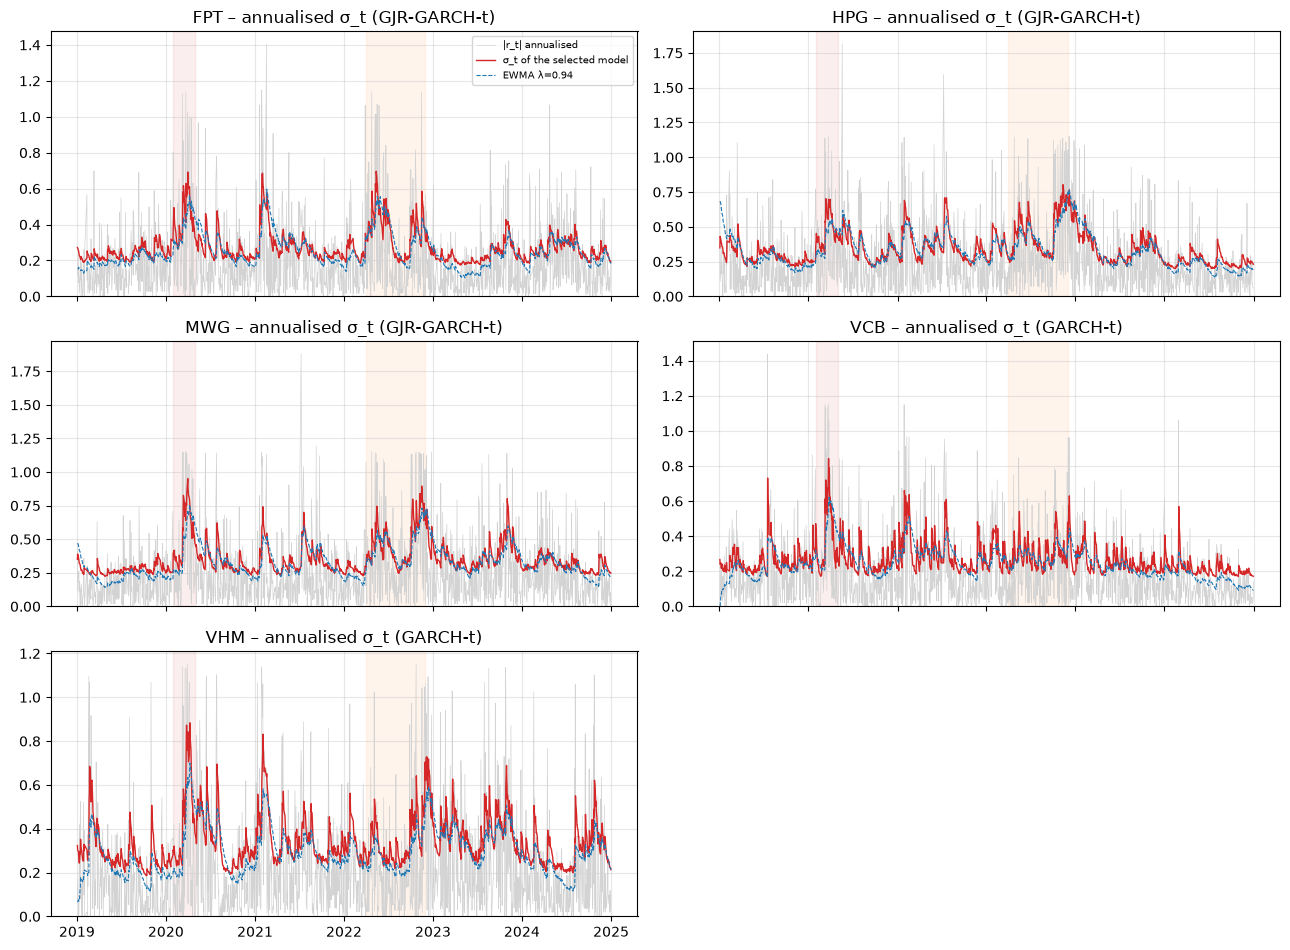

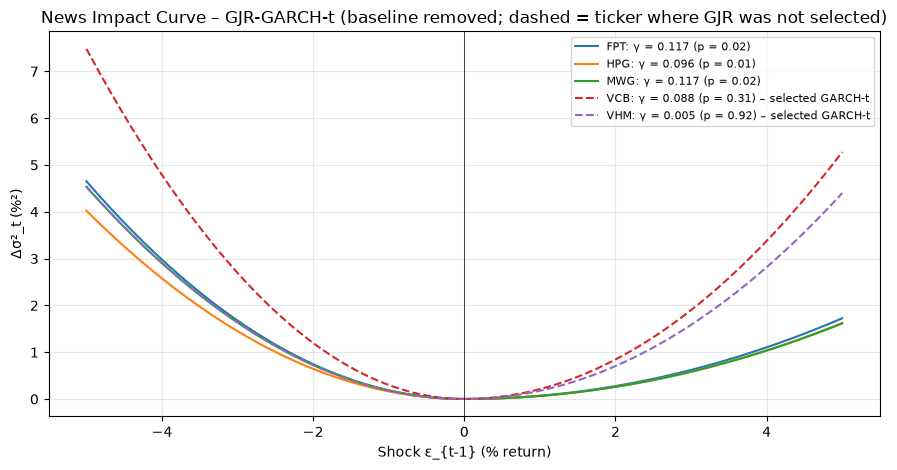

In [18]:
# ===================== 2.3 SAVE ε, σ + PLOTS =====================
std_resid = pd.DataFrame({tk: selected[tk]["std_resid"] for tk in tickers}, index=log_ret.index)
cond_vol = pd.DataFrame({tk: selected[tk]["sigma"] for tk in tickers}, index=log_ret.index)
mu_vec = pd.Series({tk: selected[tk]["params"]["mu"] / SCALE for tk in tickers})      # μ in decimals
sigma_fcst = pd.Series({tk: selected[tk]["sigma_fcst"] for tk in tickers}, name="sigma_T+1")
print("Standardised residuals (expected mean ≈ 0, std ≈ 1):")
resid_stats = std_resid.agg(["mean", "std", "skew", "kurt"]).T
display(resid_stats.round(4))
low_std = resid_stats.index[resid_stats["std"] < 0.95].tolist()
if low_std:
    print("Note: std(ε) < 0.95 for " + ", ".join(low_std) + " -> σ_t is slightly above realised volatility "
          "(common when persistence is close to 1 / IGARCH or t with small ν) -> VaR for these tickers tends to be conservative.")
print("σ forecast for session T+1 (%/day):", (sigma_fcst * 100).round(3).to_dict())

ewma = log_ret.pow(2).ewm(alpha=1 - 0.94, adjust=False).mean().shift(1).pipe(np.sqrt)
fig, axes = grid_axes(N, sharex=True)
for ax, tk in zip(axes, tickers):
    ax.plot(log_ret.index, log_ret[tk].abs() * np.sqrt(TRADING_DAYS), color="lightgrey", lw=0.5, label="|r_t| annualised")
    ax.plot(cond_vol.index, cond_vol[tk] * np.sqrt(TRADING_DAYS), color="tab:red", lw=1, label="σ_t of the selected model")
    ax.plot(ewma.index, ewma[tk] * np.sqrt(TRADING_DAYS), color="tab:blue", lw=0.8, ls="--", label="EWMA λ=0.94")
    shade_stress(ax, alpha=0.08, label=False)
    ax.set_title(f"{tk} – annualised σ_t ({best_name[tk]})"); ax.set_ylim(0, None); ax.grid(alpha=0.3)
axes[0].legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.savefig(OUT["TV2"] / "2_conditional_volatility.png", dpi=150, bbox_inches="tight"); plt.show()

# News Impact Curve: σ²_t as a function of the shock ε_{t-1},  holding σ²_{t-1} = sample variance.
# Use GJR-GARCH-t for ALL 5 tickers to compare asymmetry; tickers whose selected model is NOT GJR (γ insignificant)
# are drawn dashed – for these the curve is nearly symmetric, consistent with the conclusion "no leverage effect".
fig, ax = plt.subplots(figsize=(9, 4.8))
shocks = np.linspace(-5, 5, 201)
for tk in tickers:
    f = fits[(tk, "GJR-GARCH-t")]
    p = f["params"]
    nic = p["omega"] + (p["alpha"] + p["gamma"] * (shocks < 0)) * shocks ** 2 + p["beta"] * (log_ret[tk] * SCALE).var()
    chosen_gjr = best_name[tk].startswith("GJR")
    ax.plot(shocks, nic - nic.min(), ls="-" if chosen_gjr else "--",
            label=f"{tk}: γ = {p['gamma']:.3f} (p = {f['pvalue']['gamma']:.2f})"
                  + ("" if chosen_gjr else f" – selected {best_name[tk]}"))
ax.axvline(0, color="k", lw=0.5); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_title("News Impact Curve – GJR-GARCH-t (baseline removed; dashed = ticker where GJR was not selected)")
ax.set_xlabel("Shock ε_{t-1} (% return)"); ax.set_ylabel("Δσ²_t (%²)")
plt.tight_layout(); plt.savefig(OUT["TV2"] / "2_news_impact_curve.png", dpi=150); plt.show()

## 2.4 Residual diagnostics

In [19]:
# ===================== 2.4 LJUNG-BOX ON ε AND ε² =====================
diag_rows = []
for tk in tickers:
    for label, s in [("r_t² (before GARCH)", log_ret[tk] ** 2), ("ε", std_resid[tk]), ("ε²", std_resid[tk] ** 2)]:
        for m, row in ljung_box(s, LB_LAGS).iterrows():
            diag_rows.append({"Ticker": tk, "Series": label, "Lag": int(m), "Q": row["Q"], "p-value": row["p-value"]})
diagnostics = pd.DataFrame(diag_rows)
diag_pivot = diagnostics.pivot_table(index=["Ticker", "Series"], columns="Lag", values="p-value", sort=False)
diag_pivot.columns = [f"p (lag {c})" for c in diag_pivot.columns]
display(diag_pivot.round(4))
at = lambda lab: diagnostics[(diagnostics["Series"] == lab) & (diagnostics["Lag"] == max_lag)].set_index("Ticker")["p-value"]
print(f"ε  (lag {max_lag}): " + ", ".join(f"{tk}={'autocorrelation remains' if p < ALPHA else 'pass'} (p={p:.3f})" for tk, p in at("ε").items()))
print(f"ε² (lag {max_lag}): " + ", ".join(f"{tk}={'ARCH REMAINS' if p < ALPHA else 'ARCH removed'} (p={p:.3f})" for tk, p in at("ε²").items()))

# ---- Save Part 2 results ----
# Note on units: the model is estimated on returns in % (r × 100) -> mu is in %/day, omega in %²
UNIT = {"mu": "mu (%/day)", "omega": "omega (%²)"}
selected_df = pd.DataFrame({tk: {
    "Model": best_name[tk], **{UNIT.get(k, k): v for k, v in selected[tk]["params"].items()},
    "LogLik": selected[tk]["LL"], "k": selected[tk]["k"], "AIC": selected[tk]["AIC"], "BIC": selected[tk]["BIC"],
    "Persistence": selected[tk]["persistence"], "IGARCH?": "YES" if selected[tk]["IGARCH"] else "no",
    "Half-life (sessions)": selected[tk]["half_life"],
    "Long-run annual σ (%)": selected[tk]["uncond_vol_ann"] * 100,
    "σ T+1 (%/day)": sigma_fcst[tk] * 100,
    "std(ε)": std_resid[tk].std()} for tk in tickers}).T
display(selected_df)
std_resid.to_csv(OUT["TV2"] / "std_resid.csv", encoding="utf-8-sig")
cond_vol.to_csv(OUT["TV2"] / "cond_vol.csv", encoding="utf-8-sig")
with pd.ExcelWriter(OUT["TV2"] / "TV2_garch_results.xlsx", engine="openpyxl") as xw:
    selected_df.to_excel(xw, sheet_name="Mo_hinh_chon")
    comparison.to_excel(xw, sheet_name="So_sanh_AIC_BIC", index=False)
    lr_table.to_excel(xw, sheet_name="LR_GJR_vs_GARCH", index=False)
    all_params.to_excel(xw, sheet_name="Tham_so_day_du", index=False)
    diagnostics.to_excel(xw, sheet_name="Ljung_Box_phan_du", index=False)
print("✔ Saved Part 2 results to", OUT["TV2"])

p (lag 5)  p (lag 10)  p (lag 20)
Ticker Series                                                
FPT    r_t² (before GARCH)     0.0000      0.0000      0.0000
       ε                       0.3015      0.4439      0.6652
       ε²                      0.4050      0.5573      0.0857
HPG    r_t² (before GARCH)     0.0000      0.0000      0.0000
       ε                       0.5191      0.5886      0.1995
       ε²                      0.5620      0.6320      0.8136
MWG    r_t² (before GARCH)     0.0000      0.0000      0.0000
       ε                       0.0205      0.0688      0.0420
       ε²                      0.6096      0.8186      0.9543
VCB    r_t² (before GARCH)     0.0000      0.0000      0.0000
       ε                       0.4952      0.3644      0.2898
       ε²                      0.7935      0.9743      0.9911
VHM    r_t² (before GARCH)     0.0000      0.0000      0.0000
       ε                       0.1020      0.4559      0.4836
       ε²                      0.3970      0.6451      0.9261

ε  (lag 20): FPT=pass (p=0.665), HPG=pass (p=0.199), MWG=autocorrelation remains (p=0.042), VCB=pass (p=0.290), VHM=pass (p=0.484)
ε² (lag 20): FPT=ARCH removed (p=0.086), HPG=ARCH removed (p=0.814), MWG=ARCH removed (p=0.954), VCB=ARCH removed (p=0.991), VHM=ARCH removed (p=0.926)


,Model,mu (%/day),omega (%²),alpha,gamma,beta,nu,LogLik,k,AIC,BIC,Persistence,IGARCH?,Half-life (sessions),Long-run annual σ (%),σ T+1 (%/day),std(ε)
FPT,GJR-GARCH-t,0.103448,0.162011,0.068959,0.117095,0.842844,3.587159,-2627.765205,6,5267.530411,5299.218725,0.97035,no,23.02962,37.107638,1.217849,0.946232
HPG,GJR-GARCH-t,0.020286,0.143464,0.064914,0.096017,0.872328,4.252654,-3012.258867,6,6036.517734,6068.206048,0.98525,no,46.64576,49.508108,1.414221,0.973956
MWG,GJR-GARCH-t,0.058235,0.256807,0.064568,0.116798,0.844442,3.647943,-2992.555246,6,5997.110491,6028.798805,0.96741,no,20.920144,44.56159,1.521734,0.949936
VCB,GARCH-t,0.017609,0.355758,0.245491,NaN,0.679359,3.614824,-2591.789455,5,5193.578911,5219.985839,0.92485,no,8.872383,34.539159,1.159316,0.961817
VHM,GARCH-t,-0.063342,0.226112,0.178336,NaN,0.821564,3.039678,-2846.349936,5,5702.699872,5729.1068,0.9999,YES,NaN,NaN,1.339847,0.892587


✔ Saved Part 2 results to D:\Năm 3\Ứng dụng công nghệ trong TCNH\final 2\ouput\TV2_GARCH


## 2.5 Role of univariate GARCH in the two-step DCC

## 2.6 Out-of-sample comparison of variance models: MSE & QLIKE

In [20]:
# ===================== 2.6 OUT-OF-SAMPLE COMPARISON: MSE & QLIKE =====================
WINDOW = min(WINDOW_MAX, len(log_ret) - N_TEST)        # estimation window (shrinks automatically for short samples)
EWMA_LAMBDA = 0.94
print(f"Rolling: WINDOW = {WINDOW}, REFIT = {REFIT}, N_TEST = {N_TEST} "
      f"({log_ret.index[-N_TEST].date()} -> {log_ret.index[-1].date()})")


def sigma2_path(x, r, gjr, bc):
    """σ²_t (%²) with FIXED parameters x = [mu, omega, alpha, (gamma), beta, (nu)]; σ²_0 from backcast bc; σ²_t only uses r up to t-1."""
    mu, om, al = x[0], x[1], x[2]
    ga = x[3] if gjr else 0.0
    be = x[4] if gjr else x[3]
    e = r - mu
    z = np.empty_like(e)
    z[0] = om + (al + 0.5 * ga + be) * bc
    z[1:] = om + (al + ga * (e[:-1] < 0)) * e[:-1] ** 2
    return np.maximum(lfilter([1.0], [1.0, -be], z), 1e-12)


def fit_garch_fast(r, gjr, dist, x0=None):
    """MLE of GARCH/GJR with the same formulas as 2.1 but without standard errors; x0 = previous solution (warm start)."""
    v = r.var()
    bounds = [(-5 * abs(r.mean()) - 1, 5 * abs(r.mean()) + 1), (1e-6, 10 * v), (0.0, 1.0)] \
        + ([(-0.5, 1.0)] if gjr else []) + [(0.0, 1.0)] + ([(2.05, 100.0)] if dist == "t" else [])
    ib = 4 if gjr else 3
    cons = [{"type": "ineq", "fun": lambda p: 0.9999 - (p[2] + (0.5 * p[3] if gjr else 0) + p[ib])}]
    if gjr:
        cons.append({"type": "ineq", "fun": lambda p: p[2] + p[3]})
    nll = lambda p: -loglik_t(p, r, gjr, dist).sum()
    default = [[r.mean(), v * (1 - a0 - b0), a0] + ([0.05] if gjr else []) + [b0] + ([6.0] if dist == "t" else [])
               for a0, b0 in [(0.05, 0.90), (0.10, 0.80)]]
    best = None
    for starts in ([[x0]] if x0 is not None else []) + [default]:
        for s in starts:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                o = minimize(nll, s, method="SLSQP", bounds=bounds, constraints=cons,
                             options={"maxiter": 500, "ftol": 1e-9})
            if np.isfinite(o.fun) and (best is None or o.fun < best.fun):
                best = o
        if best is not None and best.success:
            break
    return best.x


import time as _time
_t0 = _time.time()
test_idx = log_ret.index[-N_TEST:]
fc_var = {}                                             # (ticker, model) -> variance forecast (%²) over N_TEST days
for tk in tickers:
    r = log_ret[tk].values * SCALE
    T_ = len(r); i0 = T_ - N_TEST
    for name, spec in SPECS.items():
        out, x_prev = np.empty(N_TEST), None
        for i in range(i0, T_, REFIT):
            x_prev = fit_garch_fast(r[i - WINDOW:i], spec["gjr"], spec["dist"], x_prev)
            upto = min(i + REFIT, T_)
            bc = np.mean((r[i - WINDOW:i] - x_prev[0]) ** 2)
            s2 = sigma2_path(x_prev, r[i - WINDOW:upto], spec["gjr"], bc)
            out[i - i0:upto - i0] = s2[WINDOW:]                # forecast for days i .. upto-1
        fc_var[(tk, name)] = pd.Series(out, index=test_idx)
    ew = (log_ret[tk] * SCALE).pow(2).ewm(alpha=1 - EWMA_LAMBDA, adjust=False).mean().shift(1)
    fc_var[(tk, "EWMA 0.94")] = ew.iloc[-N_TEST:]
    print(f"✔ {tk}: xong ({_time.time() - _t0:.0f}s)")

names_all = list(SPECS) + ["EWMA 0.94"]
rows = []
for tk in tickers:
    y_te = pd.Series(log_ret[tk].values[-N_TEST:] * SCALE, index=test_idx)
    proxy = (y_te - y_te.mean()) ** 2                    # squared return: noisy proxy for the true variance
    for name in names_all:
        f = fc_var[(tk, name)]
        rows.append({"Ticker": tk, "Model": name, "MSE": ((proxy - f) ** 2).mean(),
                     "QLIKE": (proxy / f - np.log(proxy.clip(lower=1e-8) / f) - 1).mean()})
oos_vol = pd.DataFrame(rows)
oos_vol["MSE rank"] = oos_vol.groupby("Ticker")["MSE"].rank().astype(int)
oos_vol["QLIKE rank"] = oos_vol.groupby("Ticker")["QLIKE"].rank().astype(int)
display(oos_vol.pivot(index="Ticker", columns="Model", values="QLIKE")[names_all].loc[tickers].round(4).rename_axis(columns="QLIKE"))
display(oos_vol.pivot(index="Ticker", columns="Model", values="MSE")[names_all].loc[tickers].round(3).rename_axis(columns="MSE (%⁴)"))

cmp_oos = pd.DataFrame({
    "BIC choice (2.2)": best_name.loc[tickers],
    "Best QLIKE": oos_vol.loc[oos_vol.groupby("Ticker")["QLIKE"].idxmin()].set_index("Ticker")["Model"].loc[tickers],
    "Best MSE": oos_vol.loc[oos_vol.groupby("Ticker")["MSE"].idxmin()].set_index("Ticker")["Model"].loc[tickers]})
cmp_oos["Matches BIC?"] = np.where(cmp_oos["BIC choice (2.2)"] == cmp_oos["Best QLIKE"], "YES", "differs")
display(cmp_oos)
n_same = int((cmp_oos["Matches BIC?"] == "YES").sum())
n_ewma = int((cmp_oos["Best QLIKE"] == "EWMA 0.94").sum())
print(f"BIC-selected model equals the best out-of-sample QLIKE model for {n_same}/{N} tickers; EWMA wins for {n_ewma}/{N} tickers.")
oos_vol.to_csv(OUT["TV2"] / "2_oos_variance_forecast.csv", index=False, encoding="utf-8-sig")


Rolling: WINDOW = 953, REFIT = 20, N_TEST = 500 (2022-12-23 -> 2024-12-31)
✔ FPT: xong (2s)
✔ HPG: xong (3s)
✔ MWG: xong (5s)
✔ VCB: xong (6s)
✔ VHM: xong (8s)


QLIKE,GARCH-N,GARCH-t,GJR-GARCH-N,GJR-GARCH-t,EWMA 0.94
Ticker,,,,,
FPT,1.5988,1.6474,1.5960,1.6430,1.6101
HPG,1.5453,1.5563,1.5411,1.5517,1.5333
MWG,1.6359,1.6658,1.6328,1.6672,1.6299
VCB,1.7043,1.7231,1.7075,1.7282,1.6218
VHM,1.9419,1.9683,1.9466,1.9750,1.9547


MSE (%⁴),GARCH-N,GARCH-t,GJR-GARCH-N,GJR-GARCH-t,EWMA 0.94
Ticker,,,,,
FPT,15.772,16.836,15.588,16.340,15.756
HPG,41.294,43.055,40.613,42.185,40.906
MWG,56.906,60.266,56.507,60.395,57.357
VCB,10.648,11.366,10.582,11.284,10.051
VHM,61.502,67.600,62.047,68.453,60.069


,BIC choice (2.2),Best QLIKE,Best MSE,Matches BIC?
Ticker,,,,
FPT,GJR-GARCH-t,GJR-GARCH-N,GJR-GARCH-N,differs
HPG,GJR-GARCH-t,EWMA 0.94,GJR-GARCH-N,differs
MWG,GJR-GARCH-t,EWMA 0.94,GJR-GARCH-N,differs
VCB,GARCH-t,EWMA 0.94,EWMA 0.94,differs
VHM,GARCH-t,GARCH-N,EWMA 0.94,differs


BIC-selected model equals the best out-of-sample QLIKE model for 0/5 tickers; EWMA wins for 3/5 tickers.


---
# PART 3: DYNAMIC CORRELATION (DCC-GARCH)
## 3.1 DCC(1,1) estimation

In [21]:
# ===================== 3.1 DCC(1,1) =====================
Z = std_resid.values                                   # T × N
Qbar = Z.T @ Z / T


def dcc_filter(a, b, Z, Qbar):
    """Returns Q (T×N×N), R (T×N×N) and Q_{T+1}."""
    Tn, Nn = Z.shape
    Q = np.empty((Tn, Nn, Nn)); R = np.empty((Tn, Nn, Nn))
    q = Qbar.copy()
    for t in range(Tn):
        if t > 0:
            q = (1 - a - b) * Qbar + a * np.outer(Z[t - 1], Z[t - 1]) + b * q
        Q[t] = q
        d = 1 / np.sqrt(np.diag(q))
        R[t] = q * np.outer(d, d)                      # diag(Q)^-1/2 Q diag(Q)^-1/2
    q_next = (1 - a - b) * Qbar + a * np.outer(Z[-1], Z[-1]) + b * q
    return Q, R, q_next


def corr_loglik_t(R, Z):
    """Daily contribution of the correlation part to the log-likelihood."""
    _, logdet = np.linalg.slogdet(R)
    quad = np.einsum("ti,tij,tj->t", Z, np.linalg.inv(R), Z)
    return -0.5 * (logdet + quad - np.einsum("ti,ti->t", Z, Z))


def dcc_nll(p):
    a, b = p
    if a < 0 or b < 0 or a + b >= 1:
        return 1e10
    return -corr_loglik_t(dcc_filter(a, b, Z, Qbar)[1], Z).sum()


best = None
for x0 in [(0.02, 0.95), (0.05, 0.90), (0.10, 0.80)]:
    res = minimize(dcc_nll, x0, method="SLSQP", bounds=[(0, 1), (0, 1)],
                   constraints=[{"type": "ineq", "fun": lambda p: 0.9999 - p[0] - p[1]}],
                   options={"maxiter": 500, "ftol": 1e-10})
    if best is None or res.fun < best.fun:
        best = res
a_hat, b_hat = best.x
se_ab = robust_se(lambda p: corr_loglik_t(dcc_filter(p[0], p[1], Z, Qbar)[1], Z), best.x)
Q_t, R_t, Q_next = dcc_filter(a_hat, b_hat, Z, Qbar)
half_life_corr = np.log(0.5) / np.log(a_hat + b_hat)

dcc_params = pd.DataFrame({"Estimate": [a_hat, b_hat, a_hat + b_hat, half_life_corr],
                           "Std.Err": [se_ab[0], se_ab[1], np.nan, np.nan]},
                          index=["a", "b", "a + b", "Correlation half-life (sessions)"])
dcc_params["p-value"] = 2 * stats.norm.sf(np.abs(dcc_params["Estimate"] / dcc_params["Std.Err"]))
display(dcc_params.round(5))
ok_stat = (a_hat >= 0) and (b_hat >= 0) and (a_hat + b_hat < 1)
print(f"Stationarity condition a ≥ 0, b ≥ 0, a + b < 1: {'SATISFIED' if ok_stat else 'NOT SATISFIED'} "
      f"(a = {a_hat:.4f}, b = {b_hat:.4f}, a + b = {a_hat + b_hat:.4f}) | converged: {best.success}")

,Estimate,Std.Err,p-value
a,0.02788,0.00564,0.0
b,0.93019,0.01984,0.0
a + b,0.95806,NaN,NaN
Correlation half-life (sessions),16.17882,NaN,NaN


Stationarity condition a ≥ 0, b ≥ 0, a + b < 1: SATISFIED (a = 0.0279, b = 0.9302, a + b = 0.9581) | converged: True


In [22]:
# ===================== 3.1c–d R_t, H_t AND T+1 FORECAST =====================
S = cond_vol.values                                     # σ_t (decimal)
H_t = R_t * S[:, :, None] * S[:, None, :]               # H_t = D_t R_t D_t
d_next = 1 / np.sqrt(np.diag(Q_next))
R_fcst = Q_next * np.outer(d_next, d_next)
H_fcst = R_fcst * np.outer(sigma_fcst.values, sigma_fcst.values)
eig_min = np.linalg.eigvalsh(H_t).min()
print(f"Diagonal of R_t = 1: {np.allclose(np.einsum('tii->ti', R_t), 1)} | H_t symmetric: {np.allclose(H_t, H_t.transpose(0, 2, 1))} "
      f"| H_t positive definite (λ_min = {eig_min:.2e}): {eig_min > 0}")
print(f"Check sqrt(diag H_t) = σ_t from Part 2: {np.allclose(np.sqrt(np.einsum('tii->ti', H_t)), S)}")
idx_tk = {tk: i for i, tk in enumerate(tickers)}
pairs_all = list(combinations(tickers, 2))
dyn_corr = pd.DataFrame({f"{x}-{y}": R_t[:, idx_tk[x], idx_tk[y]] for x, y in pairs_all}, index=log_ret.index)
print("Forecast correlation matrix R_{T+1}:")
display(pd.DataFrame(R_fcst, index=tickers, columns=tickers).round(3))

Diagonal of R_t = 1: True | H_t symmetric: True | H_t positive definite (λ_min = 7.03e-05): True
Check sqrt(diag H_t) = σ_t from Part 2: True
Forecast correlation matrix R_{T+1}:


,FPT,HPG,MWG,VCB,VHM
FPT,1.000,0.436,0.475,0.240,0.232
HPG,0.436,1.000,0.416,0.326,0.370
MWG,0.475,0.416,1.000,0.306,0.286
VCB,0.240,0.326,0.306,1.000,0.336
VHM,0.232,0.370,0.286,0.336,1.000


## 3.2 Model comparison: DCC vs CCC vs static covariance

In [23]:
# ===================== 3.2 BENCHMARK =====================
e = (log_ret - mu_vec).values


def mvn_loglik_from_R(R):
    """Multivariate normal LL when H_t = D_t R_t D_t (R: N×N or T×N×N)."""
    R = np.broadcast_to(R, (T, N, N))
    _, logdet_R = np.linalg.slogdet(R)
    quad = np.einsum("ti,tij,tj->t", Z, np.linalg.inv(R), Z)
    return np.sum(-0.5 * (N * np.log(2 * np.pi) + 2 * np.log(S).sum(axis=1) + logdet_R + quad))


k_margin = int(sum(selected[tk]["k"] for tk in tickers))
R_ccc = np.corrcoef(Z, rowvar=False)
Sigma = np.cov(log_ret.values, rowvar=False, bias=True)
bench = pd.DataFrame({
    "LogLik": [stats.multivariate_normal(log_ret.mean().values, Sigma).logpdf(log_ret.values).sum(),
               mvn_loglik_from_R(R_ccc), mvn_loglik_from_R(R_t)],
    "k": [N + N * (N + 1) // 2, k_margin + N * (N - 1) // 2, k_margin + N * (N - 1) // 2 + 2]},
    index=["Static Covariance", "CCC-GARCH", "DCC-GARCH"])
bench["AIC"] = -2 * bench["LogLik"] + 2 * bench["k"]
bench["BIC"] = -2 * bench["LogLik"] + np.log(T) * bench["k"]
bench["AIC rank"] = bench["AIC"].rank().astype(int)
bench["BIC rank"] = bench["BIC"].rank().astype(int)
display(bench.round(2))
LR_dcc = 2 * (bench.loc["DCC-GARCH", "LogLik"] - bench.loc["CCC-GARCH", "LogLik"])
p_lr = 0.5 * stats.chi2.sf(LR_dcc, 1) + 0.25 * stats.chi2.sf(LR_dcc, 2)
print(f"LR (DCC vs CCC) = {LR_dcc:.2f}, p-value = {p_lr:.3g} -> "
      + ("Reject H0: correlation CHANGES over time" if p_lr < ALPHA else "Fail to reject constant correlation"))

,LogLik,k,AIC,BIC,AIC rank,BIC rank
Static Covariance,19323.94,20,-38607.89,-38502.26,3,3
CCC-GARCH,19639.88,38,-39203.76,-39003.07,2,2
DCC-GARCH,19695.04,40,-39310.09,-39098.83,1,1


LR (DCC vs CCC) = 110.32, p-value = 3.18e-25 -> Reject H0: correlation CHANGES over time


## 3.3 Dynamic correlation plots

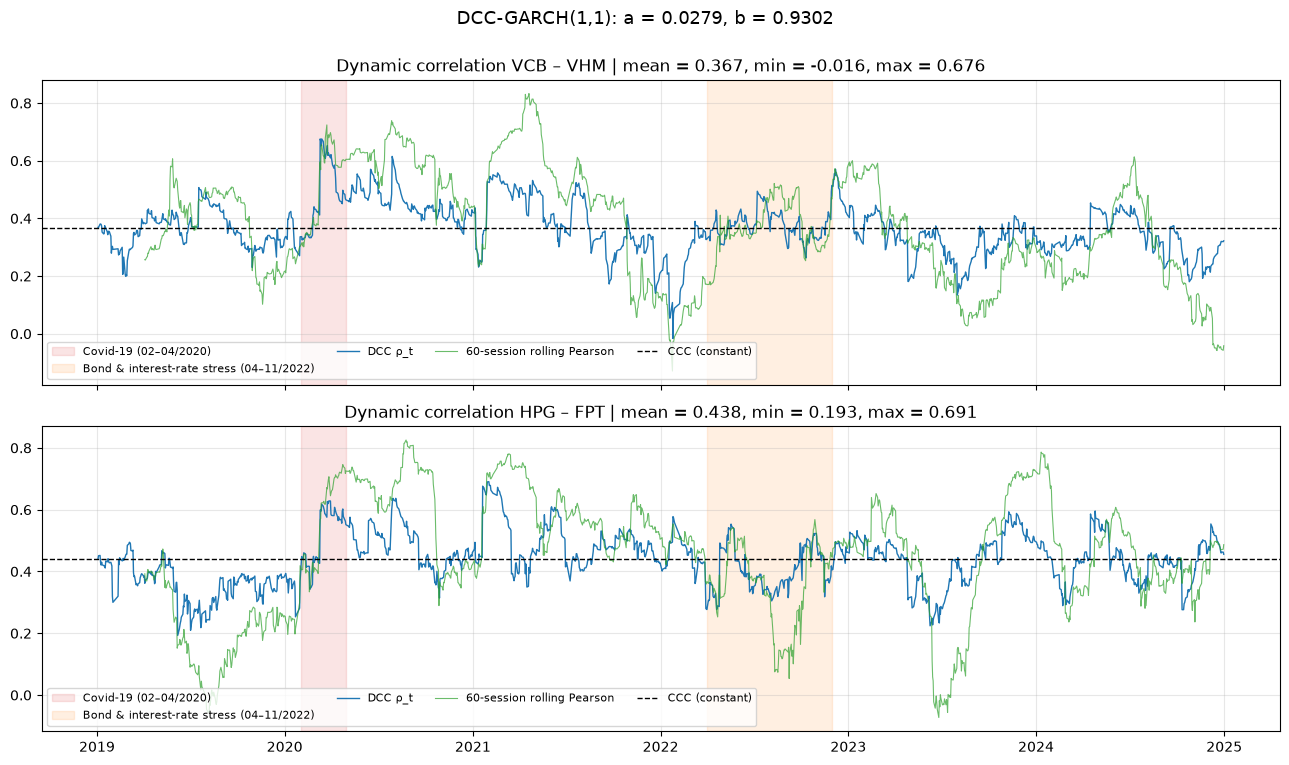

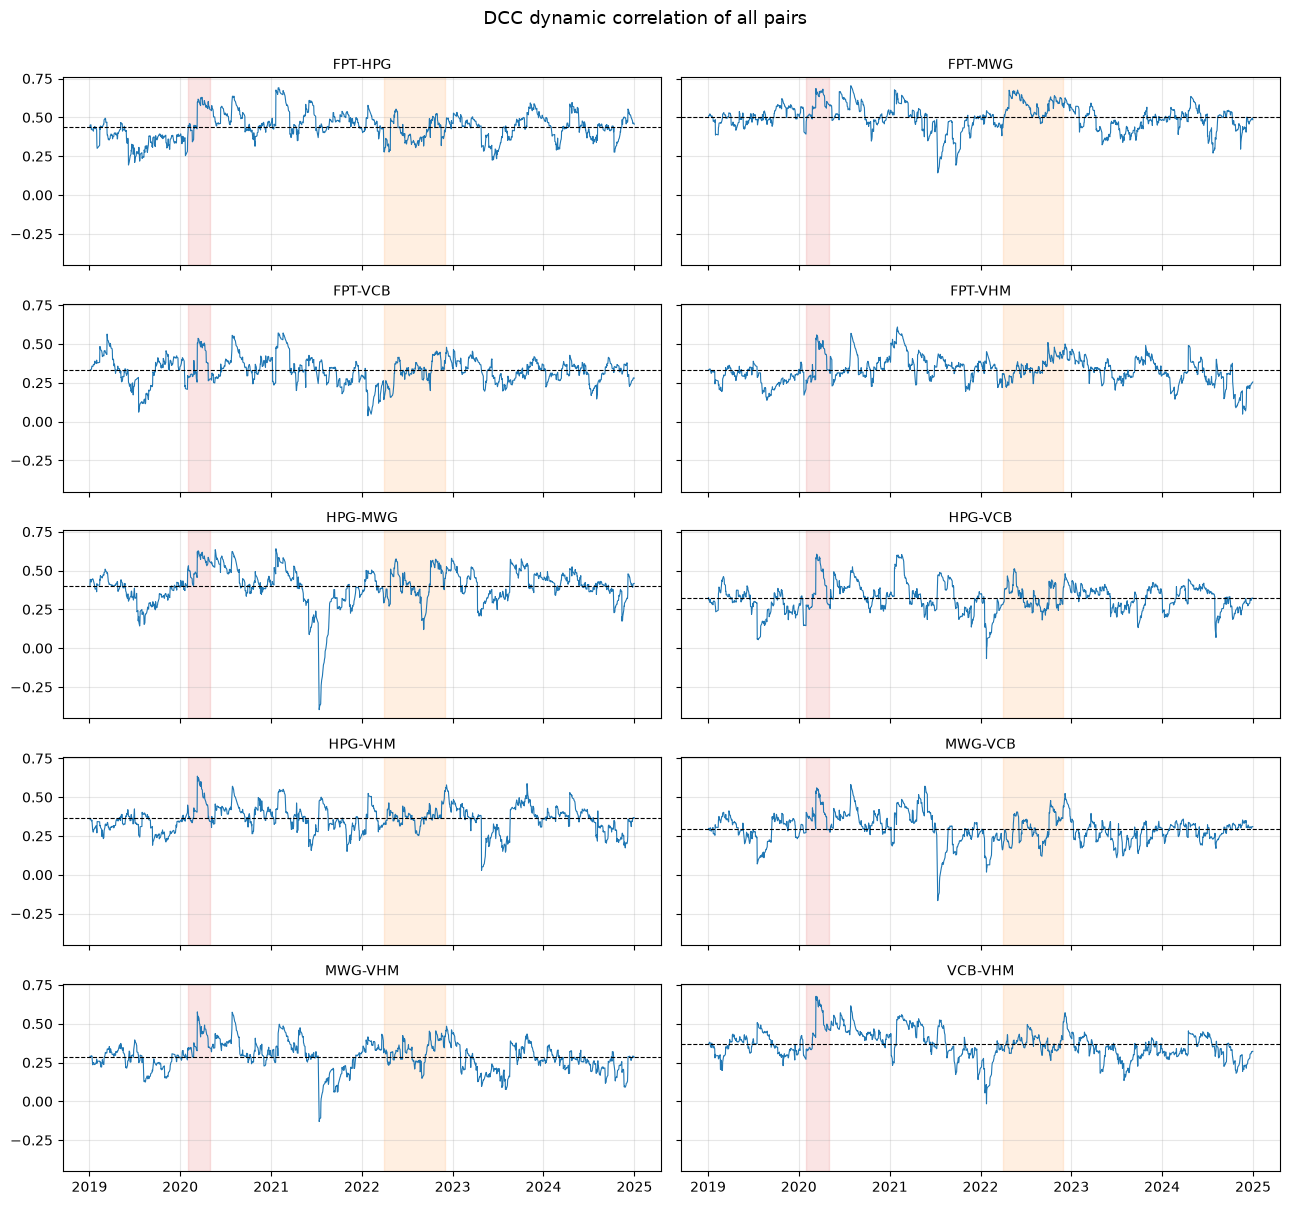

In [24]:
# ===================== 3.3 DYNAMIC CORRELATION PLOTS =====================
pairs_main = [p for p in PAIRS if p[0] in idx_tk and p[1] in idx_tk]
fig, axes = plt.subplots(len(pairs_main), 1, figsize=(13, 3.8 * len(pairs_main)), sharex=True, squeeze=False)
for ax, (x, y) in zip(axes.flat, pairs_main):
    s = pd.Series(R_t[:, idx_tk[x], idx_tk[y]], index=log_ret.index)
    shade_stress(ax)
    ax.plot(s.index, s, lw=1, color="tab:blue", label="DCC ρ_t")
    ax.plot(s.index, log_ret[x].rolling(60).corr(log_ret[y]), lw=0.8, color="tab:green", alpha=0.7, label="60-session rolling Pearson")
    ax.axhline(R_ccc[idx_tk[x], idx_tk[y]], color="black", ls="--", lw=1, label="CCC (constant)")
    ax.set_title(f"Dynamic correlation {x} – {y} | mean = {s.mean():.3f}, min = {s.min():.3f}, max = {s.max():.3f}")
    ax.grid(alpha=0.3); ax.legend(fontsize=8, ncol=4, loc="lower left")
fig.suptitle(f"DCC-GARCH(1,1): a = {a_hat:.4f}, b = {b_hat:.4f}", fontsize=13, y=1.0)
plt.tight_layout(); plt.savefig(OUT["TV3"] / "3_dcc_main_pairs.png", dpi=150, bbox_inches="tight"); plt.show()

fig, axes = grid_axes(len(pairs_all), h=2.4, sharex=True, sharey=True)
for ax, col in zip(axes, dyn_corr.columns):
    x, y = col.split("-")
    shade_stress(ax, label=False)
    ax.plot(dyn_corr.index, dyn_corr[col], lw=0.8)
    ax.axhline(R_ccc[idx_tk[x], idx_tk[y]], color="black", ls="--", lw=0.8)
    ax.set_title(col, fontsize=10); ax.grid(alpha=0.3)
fig.suptitle("DCC dynamic correlation of all pairs", fontsize=13, y=1.0)
plt.tight_layout(); plt.savefig(OUT["TV3"] / "3_dcc_all_pairs.png", dpi=150, bbox_inches="tight"); plt.show()

,Non-stress,Covid-19 (02–04/2020),Bond & interest-rate stress (04–11/2022)
FPT-HPG,0.439,0.521,0.403
FPT-MWG,0.487,0.591,0.579
FPT-VCB,0.330,0.388,0.328
FPT-VHM,0.326,0.392,0.351
HPG-MWG,0.391,0.535,0.415
HPG-VCB,0.320,0.403,0.331
HPG-VHM,0.353,0.455,0.373
MWG-VCB,0.294,0.416,0.298
MWG-VHM,0.278,0.405,0.321
VCB-VHM,0.360,0.484,0.376


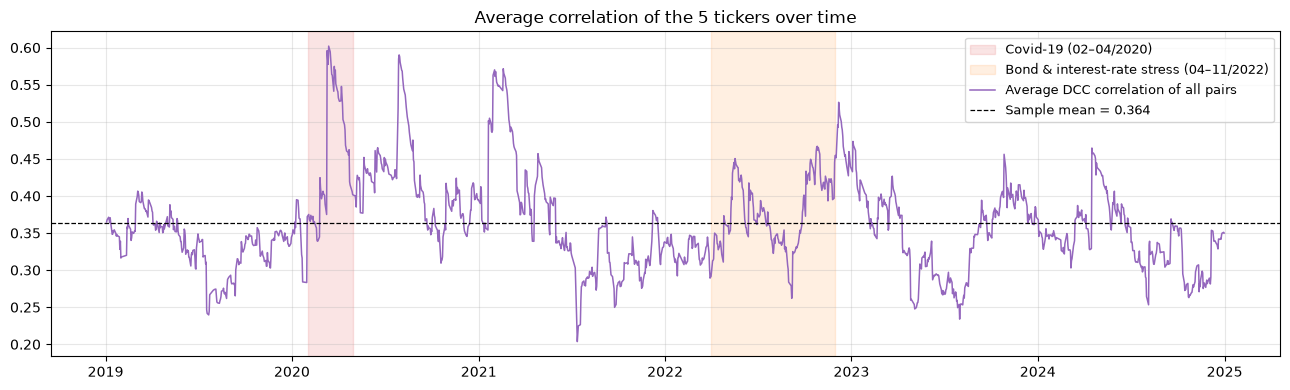

✔ Saved Part 3 results to D:\Năm 3\Ứng dụng công nghệ trong TCNH\final 2\ouput\TV3_DCC


In [25]:
# ===================== 3.3b CORRELATION BY PERIOD =====================
def period_masks(index):
    """True/False masks for each period: the STRESS periods + 'Non-stress' (outside every stress period)."""
    m = {name: (index >= s) & (index <= e) for name, (s, e) in STRESS.items()}
    m = {"Non-stress": ~np.any(np.column_stack(list(m.values())), axis=1), **m}
    return m


masks = period_masks(log_ret.index)
avg_corr = dyn_corr.mean(axis=1)
corr_by_period = pd.DataFrame({name: dyn_corr[m].mean() for name, m in masks.items()})
corr_by_period.loc["PAIR AVERAGE"] = corr_by_period.mean()
display(corr_by_period.round(3))

fig, ax = plt.subplots(figsize=(13, 4))
shade_stress(ax)
ax.plot(avg_corr.index, avg_corr, color="tab:purple", lw=1.1, label="Average DCC correlation of all pairs")
ax.axhline(avg_corr.mean(), color="black", ls="--", lw=0.9, label=f"Sample mean = {avg_corr.mean():.3f}")
ax.set_title("Average correlation of the 5 tickers over time"); ax.grid(alpha=0.3); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(OUT["TV3"] / "3_dcc_average_corr.png", dpi=150); plt.show()

# ---- Save Part 3 results ----
# dates/tickers stored as fixed-width Unicode strings (U10) so they can be reloaded with np.load(..., allow_pickle=False)
np.savez_compressed(OUT["TV3"] / "dcc_matrices.npz",
                    dates=np.array(log_ret.index.strftime("%Y-%m-%d").tolist(), dtype="U10"),
                    tickers=np.array(tickers, dtype="U10"), R=R_t, H=H_t, R_fcst=R_fcst, H_fcst=H_fcst, a=a_hat, b=b_hat, Qbar=Qbar)
with pd.ExcelWriter(OUT["TV3"] / "TV3_dcc_results.xlsx", engine="openpyxl") as xw:
    dcc_params.to_excel(xw, sheet_name="Tham_so_DCC")
    bench.to_excel(xw, sheet_name="Benchmark")
    corr_by_period.to_excel(xw, sheet_name="Tuong_quan_theo_giai_doan")
    pd.DataFrame(R_fcst, index=tickers, columns=tickers).to_excel(xw, sheet_name="R_T+1")
    pd.DataFrame(H_fcst, index=tickers, columns=tickers).to_excel(xw, sheet_name="H_T+1")
    pd.DataFrame(Qbar, index=tickers, columns=tickers).to_excel(xw, sheet_name="Q_bar")
    dyn_corr.to_excel(xw, sheet_name="Tuong_quan_dong")
print("✔ Saved Part 3 results to", OUT["TV3"])

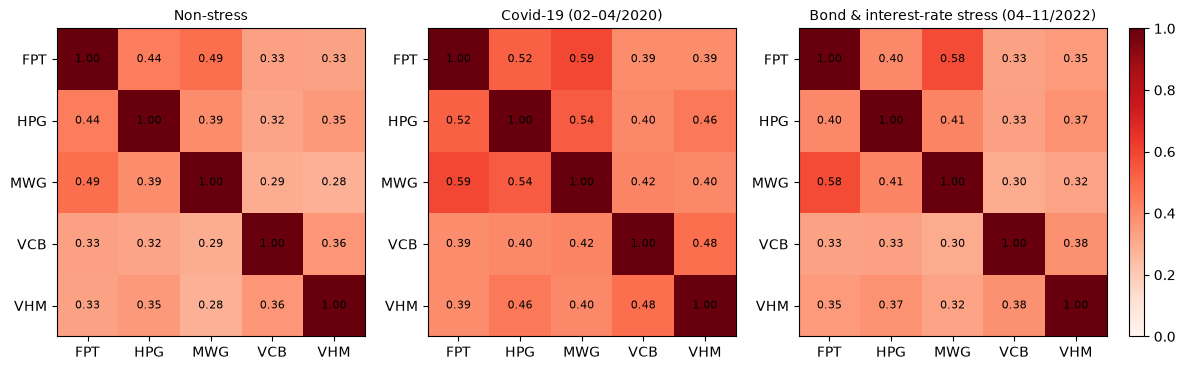

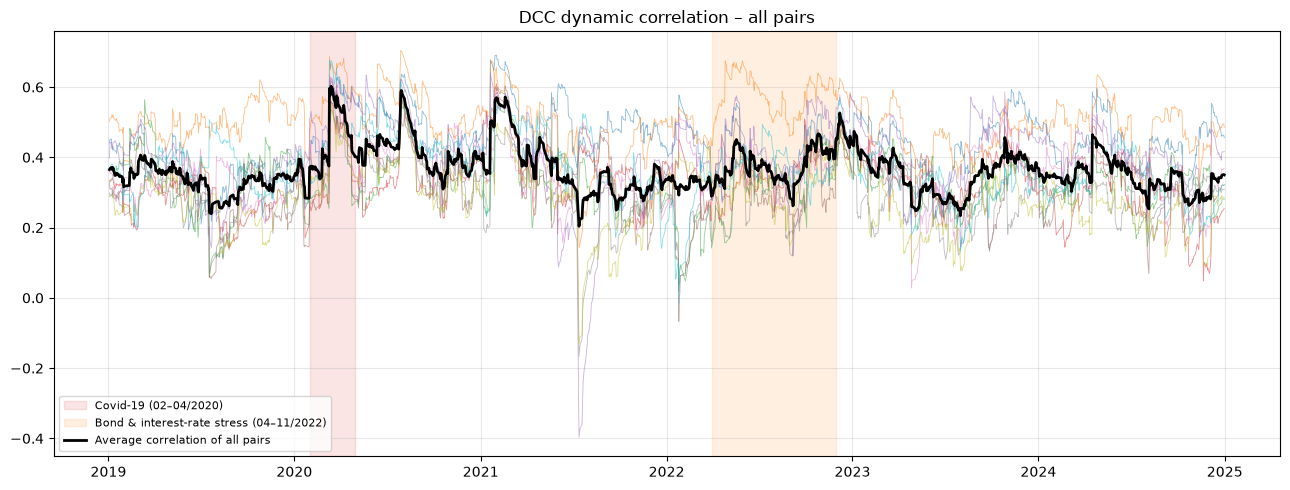

In [26]:
# ===================== 3.3c HEATMAPS BY PERIOD & OVERLAY OF ALL PAIRS =====================
fig, axes = plt.subplots(1, len(masks), figsize=(4.4 * len(masks) + 1.0, 4.0))
for ax, (name, mk) in zip(np.atleast_1d(axes), masks.items()):
    Rm = R_t[np.asarray(mk)].mean(axis=0)                  # average DCC correlation matrix within the period
    im = ax.imshow(Rm, cmap="Reds", vmin=0, vmax=1)
    ax.set_xticks(range(N)); ax.set_xticklabels(tickers); ax.set_yticks(range(N)); ax.set_yticklabels(tickers)
    for i in range(N):
        for j in range(N):
            ax.text(j, i, f"{Rm[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(name, fontsize=10)
fig.colorbar(im, ax=list(np.atleast_1d(axes)), fraction=0.025, pad=0.02)
plt.savefig(OUT["TV3"] / "3_dcc_heatmap_by_period.png", dpi=150, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(13, 5))
shade_stress(ax)
for col in dyn_corr.columns:
    ax.plot(dyn_corr.index, dyn_corr[col], lw=0.6, alpha=0.5)
ax.plot(avg_corr.index, avg_corr, color="black", lw=2, label="Average correlation of all pairs")
ax.set_title("DCC dynamic correlation – all pairs"); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.savefig(OUT["TV3"] / "3_dcc_all_pairs_overlay.png", dpi=150); plt.show()

## 3.4 Interpretation of parameters a and b

In [27]:
# ===================== 3.4 AUTOMATIC INTERPRETATION =====================
print(f"a = {a_hat:.4f}: each session, the cross-product of shocks ε_(t-1)ε_(t-1)' contributes {a_hat:.1%} to Q_t -> "
      + ("correlation reacts only MILDLY to a single shock; it rises strongly only when common shocks repeat over many sessions."
         if a_hat < 0.05 else "correlation reacts FAIRLY STRONGLY to new shocks."))
print(f"b = {b_hat:.4f}: {b_hat:.1%} of Q_(t-1) is retained -> correlation has a long 'memory' and changes slowly and smoothly.")
print(f"a + b = {a_hat + b_hat:.4f}: half-life ≈ {half_life_corr:.1f} sessions (~{half_life_corr / 21:.1f} months) -> "
      "after a common shock, correlation stays high for several weeks before slowly reverting to Q̄.")
r_norm, r_cr = corr_by_period.loc["PAIR AVERAGE"].iloc[0], corr_by_period.loc["PAIR AVERAGE"].iloc[1:]
print("Average correlation: non-stress = " + f"{r_norm:.3f}; " + "; ".join(f"{k} = {v:.3f}" for k, v in r_cr.items()))

a = 0.0279: each session, the cross-product of shocks ε_(t-1)ε_(t-1)' contributes 2.8% to Q_t -> correlation reacts only MILDLY to a single shock; it rises strongly only when common shocks repeat over many sessions.
b = 0.9302: 93.0% of Q_(t-1) is retained -> correlation has a long 'memory' and changes slowly and smoothly.
a + b = 0.9581: half-life ≈ 16.2 sessions (~0.8 months) -> after a common shock, correlation stays high for several weeks before slowly reverting to Q̄.
Average correlation: non-stress = 0.358; Covid-19 (02–04/2020) = 0.459; Bond & interest-rate stress (04–11/2022) = 0.378


## 3.5 Additional multivariate models: VAR, Granger causality, cointegration (Engle–Granger, Johansen, VECM)

VAR(3) selected by AIC on 5 return series
Granger test p-values (H0: the ROW ticker does not Granger-cause the COLUMN ticker):


d:\Anaconda\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


,FPT,HPG,MWG,VCB,VHM
FPT →,NaN,0.9977,0.1173,0.6426,0.5011
HPG →,0.0554,NaN,0.0338,0.0959,0.0392
MWG →,0.2549,0.0008,NaN,0.0261,0.0672
VCB →,0.7181,0.5915,0.9917,NaN,0.8384
VHM →,0.2848,0.0054,0.0256,0.7768,NaN


6/20 Granger relations significant at the 5%.


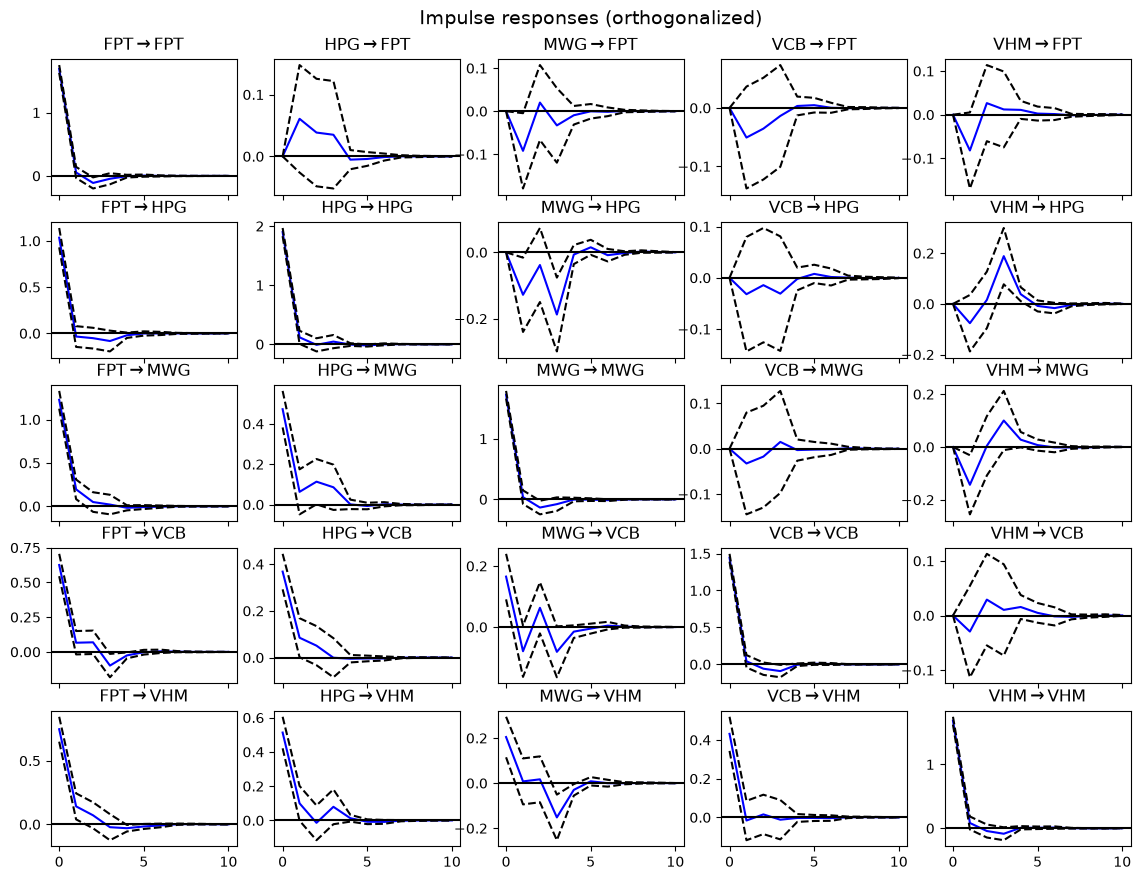

Forecast-error variance decomposition at 10 sessions (%): row = forecast ticker, column = shock source


,shock FPT,shock HPG,shock MWG,shock VCB,shock VHM
FPT,99.0,0.2,0.3,0.1,0.3
HPG,22.5,75.4,1.1,0.0,0.9
MWG,32.0,5.1,62.1,0.0,0.6
VCB,15.2,5.4,1.6,77.7,0.1
VHM,14.7,7.0,1.7,4.7,71.8


Engle–Granger (H0: no cointegration):


,Pair,EG stat,p-value,Conclusion,Required pair
0,FPT-HPG,-0.4827,0.9655,Not cointegrated,✔
1,FPT-MWG,-1.0185,0.8993,Not cointegrated,
2,FPT-VCB,-2.9888,0.1129,Not cointegrated,
3,FPT-VHM,-1.6957,0.6789,Not cointegrated,
4,HPG-MWG,-1.7430,0.6570,Not cointegrated,
5,HPG-VCB,-1.6211,0.7119,Not cointegrated,
6,HPG-VHM,-1.3806,0.8041,Not cointegrated,
7,MWG-VCB,-1.7264,0.6647,Not cointegrated,
8,MWG-VHM,-1.7115,0.6717,Not cointegrated,
9,VCB-VHM,-3.0041,0.1092,Not cointegrated,✔


Johansen (trace test, H0: rank ≤ r):


,trace stat,CV 5%,Reject H0?
rank ≤ 0,84.531,69.819,True
rank ≤ 1,46.224,47.854,False
rank ≤ 2,25.350,29.796,False
rank ≤ 3,6.954,15.494,False
rank ≤ 4,0.044,3.842,False


Cointegration rank (5%): 1
β (long-run relationship):


d:\Anaconda\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


,r1
FPT,1.000
HPG,-0.426
MWG,-1.185
VCB,0.007
VHM,1.542


α (speed of adjustment to equilibrium):


,r1
FPT,0.0014
HPG,0.0134
MWG,0.0131
VCB,-0.0009
VHM,-0.0076


In [28]:
# ===================== 3.5 VAR + COINTEGRATION (statsmodels) =====================
if not HAS_SM:
    print("[!] Section 3.5 needs statsmodels (could not be installed in cell 0.0) -> skipped. "
          "Run `pip install statsmodels`, restart the kernel and Run All to get this section's results.")
    var_ok = coint_ok = False
else:
    from statsmodels.tsa.api import VAR
    from statsmodels.tsa.stattools import coint
    from statsmodels.tsa.vector_ar.vecm import coint_johansen, VECM
    var_ok = coint_ok = False
    r_pct = log_ret * 100                                          # returns in % as in the template

    # ---------- (a) VAR on returns ----------
    try:
        var_res = VAR(r_pct).fit(maxlags=5, ic="aic")
        if var_res.k_ar == 0:                                      # AIC chose 0 lags -> use VAR(1) so the analysis can still be done
            var_res = VAR(r_pct).fit(1)
        print(f"VAR({var_res.k_ar}) selected by AIC on {N} return series")
        gc = pd.DataFrame(np.nan, index=[f"{c} →" for c in tickers], columns=tickers)     # row = cause, column = affected
        for c in tickers:
            for x in tickers:
                if x != c:
                    gc.loc[f"{x} →", c] = var_res.test_causality(caused=c, causing=[x], kind="f").pvalue
        print("Granger test p-values (H0: the ROW ticker does not Granger-cause the COLUMN ticker):")
        display(gc.round(4))
        n_sig = int((gc.values[~np.isnan(gc.values)] < ALPHA).sum())
        print(f"{n_sig}/{N * (N - 1)} Granger relations significant at the {ALPHA:.0%}.")
        gc.to_csv(OUT["TV3"] / "3_granger_pvalues.csv", encoding="utf-8-sig")
        try:
            fig = var_res.irf(10).plot(orth=True, figsize=(12, 9))
            fig.savefig(OUT["TV3"] / "3_var_irf.png", dpi=130, bbox_inches="tight"); plt.show()
        except Exception as ex:
            print("[!] Could not plot IRF:", ex)
        try:
            fevd = var_res.fevd(10)
            fevd_tbl = pd.DataFrame(fevd.decomp[:, -1, :] * 100, index=tickers,
                                    columns=[f"shock {c}" for c in tickers])
            print("Forecast-error variance decomposition at 10 sessions (%): row = forecast ticker, column = shock source")
            display(fevd_tbl.round(1))
            fevd_tbl.to_csv(OUT["TV3"] / "3_var_fevd_h10.csv", encoding="utf-8-sig")
        except Exception as ex:
            print("[!] Could not compute FEVD:", ex)
        var_ok = True
    except Exception as ex:
        print("[!] VAR error:", ex)

    # ---------- (b) Cointegration on log prices ----------
    try:
        lp = np.log(prices)
        rows = []
        for a_, b_ in combinations(tickers, 2):
            t_eg, p_eg, _ = coint(lp[a_], lp[b_], trend="c")
            rows.append({"Pair": f"{a_}-{b_}", "EG stat": t_eg, "p-value": p_eg,
                         "Conclusion": "Cointegrated" if p_eg < ALPHA else "Not cointegrated",
                         "Required pair": "✔" if (a_, b_) in PAIRS or (b_, a_) in PAIRS else ""})
        eg_tbl = pd.DataFrame(rows)
        print("Engle–Granger (H0: no cointegration):")
        display(eg_tbl.round(4))
        eg_tbl.to_csv(OUT["TV3"] / "3_engle_granger.csv", index=False, encoding="utf-8-sig")

        jo = coint_johansen(lp, det_order=0, k_ar_diff=1)
        jo_tbl = pd.DataFrame({"trace stat": jo.lr1, "CV 5%": jo.cvt[:, 1]},
                              index=[f"rank ≤ {i}" for i in range(N)])
        jo_tbl["Reject H0?"] = jo_tbl["trace stat"] > jo_tbl["CV 5%"]
        print("Johansen (trace test, H0: rank ≤ r):")
        display(jo_tbl.round(3))
        rank = 0
        for i in range(N):                                         # stop at the first non-rejection
            if jo.lr1[i] > jo.cvt[i, 1]:
                rank += 1
            else:
                break
        print(f"Cointegration rank (5%): {rank}")
        jo_tbl.to_csv(OUT["TV3"] / "3_johansen_trace.csv", encoding="utf-8-sig")
        if 0 < rank < N:
            vecm = VECM(lp, k_ar_diff=1, coint_rank=rank, deterministic="ci").fit()
            cols = [f"r{j + 1}" for j in range(rank)]
            print("β (long-run relationship):"); display(pd.DataFrame(vecm.beta, index=tickers, columns=cols).round(3))
            print("α (speed of adjustment to equilibrium):"); display(pd.DataFrame(vecm.alpha, index=tickers, columns=cols).round(4))
        elif rank == N:
            print("Rank = N: the price series look almost stationary -> re-check the data; VECM not estimated.")
        else:
            print("No cointegration -> VECM not estimated; linkages between tickers run mainly through volatility/correlation (DCC).")
        coint_ok = True
    except Exception as ex:
        print("[!] Cointegration error:", ex)


---
# PART 4: PORTFOLIO RISK & BACKTESTING (VaR, ES, BASEL TESTS)
## 4.1 Conditional portfolio volatility

Weights: {'FPT': 0.2, 'HPG': 0.2, 'MWG': 0.2, 'VCB': 0.2, 'VHM': 0.2}
Average annualised σ_p: 22.45% | average diversification benefit: 29.6%


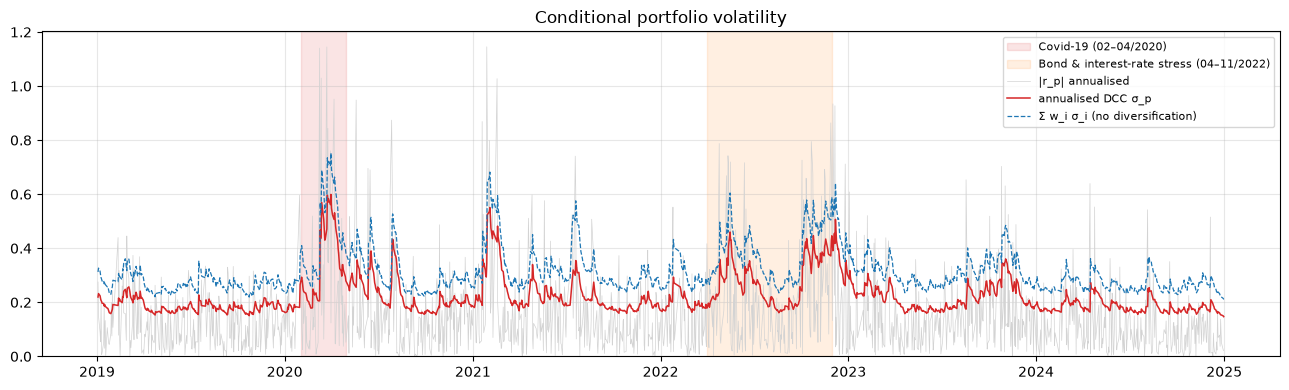

In [29]:
# ===================== 4.1 PORTFOLIO VOLATILITY =====================
WEIGHTS = pd.Series(1 / N, index=tickers)             # Equal weight; for market-cap weights assign another Series that sums to 1
assert np.isclose(WEIGHTS.sum(), 1), "Weights must sum to 1"
w = WEIGHTS.values
r_p = pd.Series(log_ret.values @ w, index=log_ret.index, name="r_p")
sigma_p = pd.Series(np.sqrt(np.einsum("i,tij,j->t", w, H_t, w)), index=log_ret.index, name="sigma_p")
undiv = pd.Series(S @ w, index=log_ret.index)          # portfolio σ if all correlations = 1
div_benefit = 1 - sigma_p / undiv
print("Weights:", WEIGHTS.round(3).to_dict())
print(f"Average annualised σ_p: {sigma_p.mean() * np.sqrt(TRADING_DAYS):.2%} | average diversification benefit: {div_benefit.mean():.1%}")

fig, ax = plt.subplots(figsize=(13, 4))
shade_stress(ax)
ax.plot(r_p.index, r_p.abs() * np.sqrt(TRADING_DAYS), color="lightgrey", lw=0.5, label="|r_p| annualised")
ax.plot(sigma_p.index, sigma_p * np.sqrt(TRADING_DAYS), color="tab:red", lw=1.1, label="annualised DCC σ_p")
ax.plot(undiv.index, undiv * np.sqrt(TRADING_DAYS), color="tab:blue", lw=0.9, ls="--", label="Σ w_i σ_i (no diversification)")
ax.set_title("Conditional portfolio volatility"); ax.grid(alpha=0.3); ax.legend(fontsize=8); ax.set_ylim(0, None)
plt.tight_layout(); plt.savefig(OUT["TV4"] / "4_portfolio_volatility.png", dpi=150); plt.show()

## 4.2 1-day VaR & ES: Normal, Student-t, Historical Simulation

In [30]:
# ===================== 4.2a ESTIMATE ν FOR STUDENT-t =====================
z_p = (r_p / sigma_p).values


def std_t_nll(nu, x):
    """Negative log-likelihood of the standardised Student-t (variance 1)."""
    c = np.sqrt((nu - 2) / nu)
    return -np.sum(stats.t.logpdf(x / c, nu) - np.log(c))


nu_p = minimize(lambda v: std_t_nll(v[0], z_p), [6.0], bounds=[(2.05, 100)], method="L-BFGS-B").x[0]
print(f"Portfolio residuals z_p: std = {z_p.std():.3f}, kurtosis = {stats.kurtosis(z_p, fisher=False):.2f} -> estimated ν = {nu_p:.2f}")

Portfolio residuals z_p: std = 0.925, kurtosis = 5.48 -> estimated ν = 4.21


Backtest window: 2020-01-16 -> 2024-12-31 (1203 sessions)


,Average (%)
VaR_Normal_95,2.412
ES_Normal_95,3.024
VaR_t_95,2.232
ES_t_95,3.314
VaR_HS_95,2.413
ES_HS_95,3.660
VaR_Normal_99,3.411
ES_Normal_99,3.908
VaR_t_99,3.873
ES_t_99,5.325


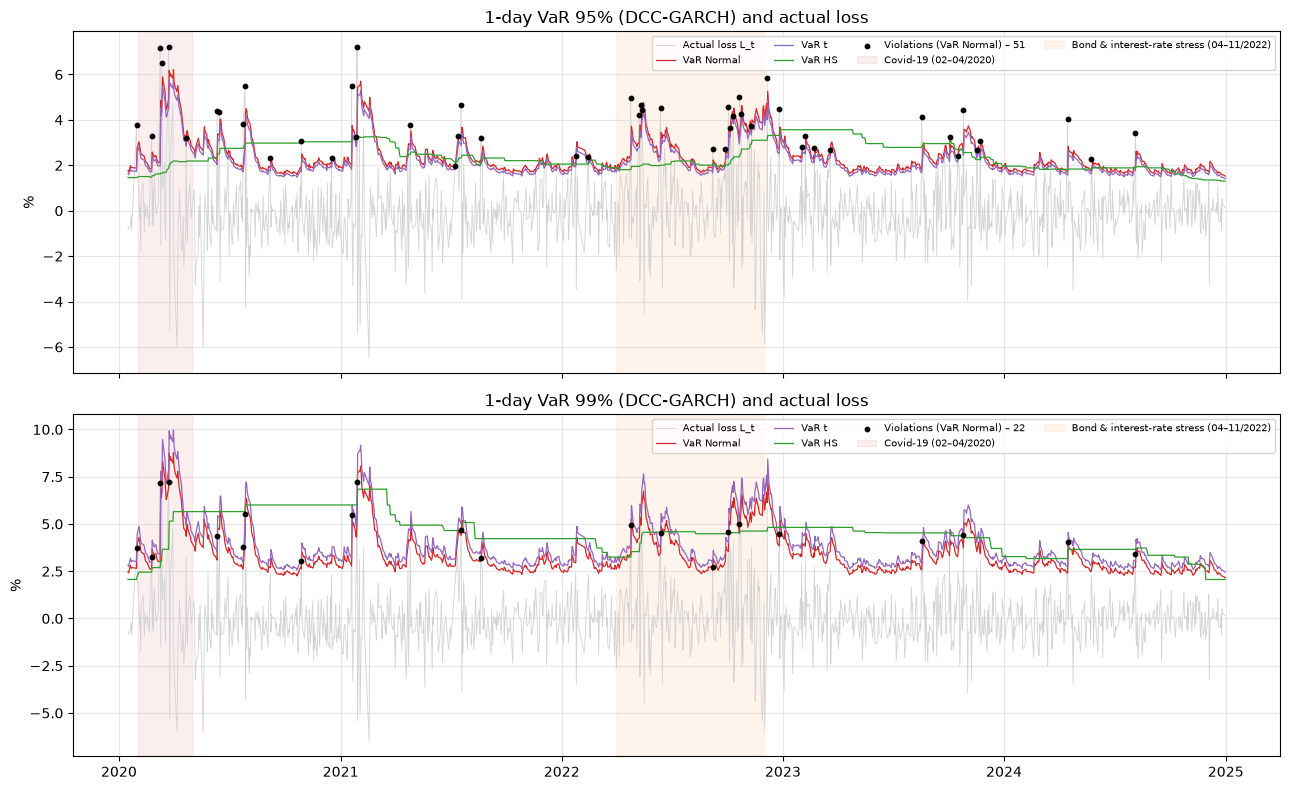

In [31]:
# ===================== 4.2b COMPUTE VaR / ES =====================
def var_es_normal(sig, a):
    z = stats.norm.ppf(1 - a)
    return z * sig, sig * stats.norm.pdf(z) / a


def var_es_t(sig, a, nu):
    c = np.sqrt((nu - 2) / nu)
    q = stats.t.ppf(1 - a, nu)
    return c * q * sig, c * sig * stats.t.pdf(q, nu) / a * (nu + q ** 2) / (nu - 1)


def var_es_hs(r, a, window):
    """HS: use the window of returns BEFORE day t (no look-ahead)."""
    var, es = np.full(len(r), np.nan), np.full(len(r), np.nan)
    x = r.values
    for t in range(window, len(x)):
        hist = x[t - window:t]
        q = np.quantile(hist, a)
        var[t], es[t] = -q, -hist[hist <= q].mean()
    return var, es


var_es = pd.DataFrame({"r_p": r_p, "loss": -r_p, "sigma_p": sigma_p})
for cl in VAR_LEVELS:
    a = 1 - cl
    tag = f"{int(cl * 100)}"
    var_es[f"VaR_Normal_{tag}"], var_es[f"ES_Normal_{tag}"] = var_es_normal(sigma_p.values, a)
    var_es[f"VaR_t_{tag}"], var_es[f"ES_t_{tag}"] = var_es_t(sigma_p.values, a, nu_p)
    var_es[f"VaR_HS_{tag}"], var_es[f"ES_HS_{tag}"] = var_es_hs(r_p, a, HS_WINDOW)
bt = var_es.iloc[HS_WINDOW:].copy()                    # common backtest window for the 3 methods
print(f"Backtest window: {bt.index.min().date()} -> {bt.index.max().date()} ({len(bt)} sessions)")
display((bt.filter(regex="^(VaR|ES)").mean() * 100).round(3).to_frame("Average (%)"))

METHODS = ["Normal", "t", "HS"]
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, cl in zip(axes, VAR_LEVELS):
    tag = f"{int(cl * 100)}"
    loss = -bt["r_p"]
    ax.plot(bt.index, loss * 100, color="lightgrey", lw=0.6, label="Actual loss L_t")
    for m, c in zip(METHODS, ["tab:red", "tab:purple", "tab:green"]):
        ax.plot(bt.index, bt[f"VaR_{m}_{tag}"] * 100, lw=0.9, color=c, label=f"VaR {m}")
    br = loss > bt[f"VaR_{VIOL_MODEL}_{tag}"]                        # model used to mark violations: VIOL_MODEL (cell 0.2)
    ax.scatter(bt.index[br], loss[br] * 100, color="black", s=10, zorder=3, label=f"Violations (VaR {VIOL_MODEL}) – {int(br.sum())}")
    shade_stress(ax, alpha=0.08)
    ax.set_title(f"1-day VaR {tag}% (DCC-GARCH) and actual loss"); ax.set_ylabel("%"); ax.grid(alpha=0.3)
    ax.legend(fontsize=7, ncol=4, loc="upper right")
plt.tight_layout(); plt.savefig(OUT["TV4"] / "4_var_backtest.png", dpi=150, bbox_inches="tight"); plt.show()


## 4.3 Backtesting: Kupiec, Christoffersen, Basel traffic light

In [32]:
# ===================== 4.3 TEST FUNCTIONS =====================
def _xlogy(x, y):
    return 0.0 if x == 0 else x * np.log(y)


def kupiec_pof(hits, a):
    n, x = len(hits), int(hits.sum())
    p_hat = x / n
    ll0 = _xlogy(n - x, 1 - a) + _xlogy(x, a)
    ll1 = _xlogy(n - x, 1 - p_hat) + _xlogy(x, p_hat)
    lr = -2 * (ll0 - ll1)
    return lr, stats.chi2.sf(lr, 1)


def christoffersen_ind(hits):
    h = np.asarray(hits, int)
    prev, cur = h[:-1], h[1:]
    n00 = int(((prev == 0) & (cur == 0)).sum()); n01 = int(((prev == 0) & (cur == 1)).sum())
    n10 = int(((prev == 1) & (cur == 0)).sum()); n11 = int(((prev == 1) & (cur == 1)).sum())
    pi01 = n01 / max(n00 + n01, 1); pi11 = n11 / max(n10 + n11, 1)
    pi = (n01 + n11) / max(n00 + n01 + n10 + n11, 1)
    ll0 = _xlogy(n00 + n10, 1 - pi) + _xlogy(n01 + n11, pi)
    ll1 = _xlogy(n00, 1 - pi01) + _xlogy(n01, pi01) + _xlogy(n10, 1 - pi11) + _xlogy(n11, pi11)
    lr = -2 * (ll0 - ll1)
    return lr, stats.chi2.sf(lr, 1), n11


def binomial_zone(x, n, a):
    cdf = stats.binom.cdf(x, n, a)                              # P(X ≤ x): matches the Basel 0–4 / 5–9 / ≥10 table for n = 250, α = 1%
    return "Green" if cdf < 0.95 else ("Yellow" if cdf < 0.9999 else "Red")


BASEL_PLUS = {5: 0.40, 6: 0.50, 7: 0.65, 8: 0.75, 9: 0.85}

rows = []
for cl in VAR_LEVELS:
    a = 1 - cl
    tag = f"{int(cl * 100)}"
    for m in METHODS:
        loss = -bt["r_p"]
        hits = (loss > bt[f"VaR_{m}_{tag}"]).astype(int).values
        n, x = len(hits), int(hits.sum())
        lr_uc, p_uc = kupiec_pof(hits, a)
        lr_ind, p_ind, n11 = christoffersen_ind(hits)
        lr_cc = lr_uc + lr_ind
        hit_days = hits.astype(bool)
        rows.append({"Confidence level": f"{tag}%", "Method": m, "Days": n, "Violations": x,
                     "Expected": round(n * a, 1), "Violation rate (%)": 100 * x / n,
                     "Kupiec LR": lr_uc, "Kupiec p": p_uc, "Christoffersen LR": lr_ind, "Christoffersen p": p_ind,
                     "Consecutive violations (n11)": n11, "LR_cc": lr_cc, "LR_cc p": stats.chi2.sf(lr_cc, 2),
                     "Zone (binomial)": binomial_zone(x, n, a),
                     "Avg loss on violation days (%)": 100 * loss[hit_days].mean() if x else np.nan,
                     "Avg forecast ES on violation days (%)": 100 * bt[f"ES_{m}_{tag}"][hit_days].mean() if x else np.nan})
bt_table = pd.DataFrame(rows)


def verdict(row, a):
    over = row["Violation rate (%)"] > 100 * a
    s = ("UNDERESTIMATES risk" if over else "OVERESTIMATES risk") if row["Kupiec p"] < ALPHA else "Violation rate consistent"
    s += "; violations CLUSTERED" if row["Christoffersen p"] < ALPHA else "; violations independent"
    return s


bt_table["Conclusion"] = [verdict(r, 1 - float(r["Confidence level"][:-1]) / 100) for _, r in bt_table.iterrows()]
display(bt_table.round(4))

# Standard Basel Traffic Light: VaR 99%, last 250 sessions
last = bt.iloc[-250:]
basel_rows = []
for m in METHODS:
    x = int((-last["r_p"] > last[f"VaR_{m}_99"]).sum())
    zone = "Green" if x <= 4 else ("Yellow" if x <= 9 else "Red")
    plus = 0.0 if x <= 4 else BASEL_PLUS.get(x, 1.0)
    basel_rows.append({"Method": m, "Window": f"{last.index.min().date()} -> {last.index.max().date()}",
                       "VaR99 violations (250 sessions)": x, "Basel zone": zone, "Plus factor": plus, "Capital multiplier k": 3 + plus})
basel_table = pd.DataFrame(basel_rows)
display(basel_table)

,Confidence level,Method,Days,Violations,Expected,Violation rate (%),Kupiec LR,Kupiec p,Christoffersen LR,Christoffersen p,Consecutive violations (n11),LR_cc,LR_cc p,Zone (binomial),Avg loss on violation days (%),Avg forecast ES on violation days (%),Conclusion
0,95%,Normal,1203,51,60.2,4.2394,1.5415,0.2144,3.0463,0.0809,5,4.5878,0.1009,Green,3.9147,3.3820,Violation rate consistent; violations independent
1,95%,t,1203,61,60.2,5.0707,0.0126,0.9107,6.2598,0.0124,8,6.2723,0.0434,Green,3.6089,3.5822,Violation rate consistent; violations CLUSTERED
2,95%,HS,1203,63,60.2,5.2369,0.1401,0.7082,23.2428,0.0000,14,23.3829,0.0000,Green,3.7248,3.5545,Violation rate consistent; violations CLUSTERED
3,99%,Normal,1203,22,12.0,1.8288,6.7038,0.0096,0.6583,0.4172,1,7.3621,0.0252,Yellow,4.5890,3.9373,UNDERESTIMATES risk; violations independent
4,99%,t,1203,17,12.0,1.4131,1.8383,0.1752,1.4019,0.2364,1,3.2402,0.1979,Green,4.5983,4.9811,Violation rate consistent; violations independent
5,99%,HS,1203,18,12.0,1.4963,2.5968,0.1071,9.8910,0.0017,3,12.4878,0.0019,Yellow,4.8950,4.4994,Violation rate consistent; violations CLUSTERED


,Method,Window,VaR99 violations (250 sessions),Basel zone,Plus factor,Capital multiplier k
0,Normal,2023-12-27 -> 2024-12-31,2,Green,0.0,3.0
1,t,2023-12-27 -> 2024-12-31,2,Green,0.0,3.0
2,HS,2023-12-27 -> 2024-12-31,1,Green,0.0,3.0


In [33]:
# ===================== 4.3b VIOLATIONS BY YEAR / PERIOD =====================
hits_df = pd.DataFrame({f"{m}_{int(cl * 100)}": (-bt["r_p"] > bt[f"VaR_{m}_{int(cl * 100)}"]).astype(int)
                        for cl in VAR_LEVELS for m in METHODS}, index=bt.index)
by_year = hits_df.groupby(hits_df.index.year).sum()
by_year["Sessions"] = hits_df.groupby(hits_df.index.year).size()
print("Violations by year:"); display(by_year)
bt_masks = period_masks(bt.index)
rate_period = pd.DataFrame({name: hits_df[m].mean() * 100 for name, m in bt_masks.items() if m.any()}).T
rate_period["Sessions"] = [int(m.sum()) for name, m in bt_masks.items() if m.any()]
print("Violation rate by period (%, expected 5% / 1%):"); display(rate_period.round(2))

with pd.ExcelWriter(OUT["TV4"] / "TV4_var_backtest.xlsx", engine="openpyxl") as xw:
    bt_table.to_excel(xw, sheet_name="Backtest", index=False)
    basel_table.to_excel(xw, sheet_name="Basel_250", index=False)
    (bt.filter(regex="^(VaR|ES)").mean() * 100).to_frame("Average (%)").to_excel(xw, sheet_name="VaR_ES_TB")
    by_year.to_excel(xw, sheet_name="Vi_pham_theo_nam")
    rate_period.to_excel(xw, sheet_name="Vi_pham_theo_giai_doan")
    var_es.to_excel(xw, sheet_name="VaR_ES_hang_ngay")
print("✔ Saved Part 4 results to", OUT["TV4"])

Violations by year:


,Normal_95,t_95,HS_95,Normal_99,t_99,HS_99,Sessions
Date,,,,,,,
2020,13,14,22,8,7,7,234
2021,8,12,10,4,2,2,229
2022,17,19,22,6,4,7,246
2023,10,11,5,2,2,1,247
2024,3,5,4,2,2,1,247


Violation rate by period (%, expected 5% / 1%):


,Normal_95,t_95,HS_95,Normal_99,t_99,HS_99,Sessions
Non-stress,3.38,4.41,3.18,1.44,1.23,0.72,975
Covid-19 (02–04/2020),8.20,8.20,22.95,4.92,3.28,8.20,61
Bond & interest-rate stress (04–11/2022),7.78,7.78,10.78,2.99,1.80,3.59,167


✔ Saved Part 4 results to D:\Năm 3\Ứng dụng công nghệ trong TCNH\final 2\ouput\TV4_VaR_Backtest


## 4.4 Does DCC-GARCH measure portfolio risk correctly?

In [34]:
# ===================== 4.4 AUTOMATIC INTERPRETATION =====================
for _, r in bt_table.iterrows():
    print(f"VaR {r['Confidence level']} – {r['Method']:<6}: {r['Violations']} violations / expected {r['Expected']} "
          f"({r['Violation rate (%)']:.2f}%) | Kupiec p = {r['Kupiec p']:.3f}, Christoffersen p = {r['Christoffersen p']:.3f} "
          f"| zone {r['Zone (binomial)']} -> {r['Conclusion']}")
worst = rate_period.drop(columns="Sessions").drop(index="Non-stress", errors="ignore")
if len(worst):
    nrm = rate_period.loc["Non-stress"].drop("Sessions")
    for name, row in worst.iterrows():
        v99, v95 = f"{VIOL_MODEL}_99", f"{VIOL_MODEL}_95"
        print(f"\n{name}: violation rate of VaR-{VIOL_MODEL} 99% = {row[v99]:.2f}% (non-stress {nrm[v99]:.2f}%), "
              f"VaR-{VIOL_MODEL} 95% = {row[v95]:.2f}% (non-stress {nrm[v95]:.2f}%)"
              + (" -> the model reacts late when a shock hits suddenly; violations concentrate in the stress period."
                 if row[v99] > nrm[v99] else "."))

print("\nES check (average actual loss on violation days vs average forecast ES on those days):")
for _, r in bt_table.iterrows():
    if r["Violations"]:
        ratio = r["Avg loss on violation days (%)"] / r["Avg forecast ES on violation days (%)"]       # > 1: actual loss exceeds forecast ES
        verdict_es = ("ES covers the tail losses" if ratio <= 1 else
                      "approximately (deviation < 5%)" if ratio <= 1.05 else "ES UNDERESTIMATES tail losses")
        print(f"  ES {r['Confidence level']} – {r['Method']:<6}: actual loss {r['Avg loss on violation days (%)']:.2f}% vs ES "
              f"{r['Avg forecast ES on violation days (%)']:.2f}% (ratio {ratio:.2f}) -> {verdict_es}")
print("\nNote: GARCH/DCC parameters are estimated on the FULL SAMPLE (in-sample), so this backtest is more optimistic than reality;  "
      "out-of-sample results (re-estimated on a rolling window) are in section 4.5.")

VaR 95% – Normal: 51 violations / expected 60.2 (4.24%) | Kupiec p = 0.214, Christoffersen p = 0.081 | zone Green -> Violation rate consistent; violations independent
VaR 95% – t     : 61 violations / expected 60.2 (5.07%) | Kupiec p = 0.911, Christoffersen p = 0.012 | zone Green -> Violation rate consistent; violations CLUSTERED
VaR 95% – HS    : 63 violations / expected 60.2 (5.24%) | Kupiec p = 0.708, Christoffersen p = 0.000 | zone Green -> Violation rate consistent; violations CLUSTERED
VaR 99% – Normal: 22 violations / expected 12.0 (1.83%) | Kupiec p = 0.010, Christoffersen p = 0.417 | zone Yellow -> UNDERESTIMATES risk; violations independent
VaR 99% – t     : 17 violations / expected 12.0 (1.41%) | Kupiec p = 0.175, Christoffersen p = 0.236 | zone Green -> Violation rate consistent; violations independent
VaR 99% – HS    : 18 violations / expected 12.0 (1.50%) | Kupiec p = 0.107, Christoffersen p = 0.002 | zone Yellow -> Violation rate consistent; violations CLUSTERED

Covid-1

## 4.5 Out-of-sample portfolio risk forecasts

In [35]:
# ===================== 4.5.1 CONFIGURATION & ESTIMATION FUNCTIONS (same formulas as Parts 2/3) =====================
import time
from scipy import optimize

WINDOW = min(WINDOW_MAX, len(log_ret) - N_TEST)       # estimation window (shrinks automatically for short samples); N_TEST, REFIT are declared in cell 0.2
LAMBDA_EWMA = 0.94

SPEC = {tk: dict(SPECS[best_name[tk]]) for tk in tickers}     # marginal model selected in Part 2 (gjr, dist)
print(f"Rolling: WINDOW = {WINDOW}, REFIT = {REFIT}, N_TEST = {N_TEST} "
      f"({log_ret.index[-N_TEST].date()} -> {log_ret.index[-1].date()})")
print("Marginal models (from Part 2):", best_name.to_dict())


def g_filter(x, r, gjr, bc):
    """σ²_t of GARCH/GJR with parameters x = [mu, omega, alpha, (gamma), beta, (nu)], σ²_0 from backcast bc."""
    mu, om, al = x[0], x[1], x[2]
    ga = x[3] if gjr else 0.0
    be = x[4] if gjr else x[3]
    e = r - mu
    z = np.empty_like(e)
    z[0] = om + (al + 0.5 * ga) * bc + be * bc
    z[1:] = om + (al + ga * (e[:-1] < 0)) * e[:-1] ** 2
    return lfilter([1.0], [1.0, -be], z), e


def g_negll(x, r, gjr, dist):
    s2, e = g_filter(x, r, gjr, np.mean((r - x[0]) ** 2))
    s2 = np.maximum(s2, 1e-12)
    if dist == "normal":
        return 0.5 * np.sum(np.log(2 * np.pi) + np.log(s2) + e ** 2 / s2)
    nu = x[-1]
    return -np.sum(gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2))
                   - 0.5 * np.log(s2) - (nu + 1) / 2 * np.log1p(e ** 2 / (s2 * (nu - 2))))


def fit_margin(r, gjr, dist, x0=None):
    """MLE of GARCH/GJR (same as fit_garch in 2.1, standard errors dropped for speed). Returns the parameter vector."""
    v = r.var()
    bnds = [(-np.inf, np.inf), (1e-8, 10 * v), (0, 1)] + ([(-1, 1)] if gjr else []) + [(0, 1)] + ([(2.05, 200)] if dist == "t" else [])
    ib = 4 if gjr else 3
    cons = [{"type": "ineq", "fun": lambda p: 0.99999 - (p[2] + (0.5 * p[3] if gjr else 0) + p[ib])}]
    if gjr:
        cons.append({"type": "ineq", "fun": lambda p: p[2] + p[3]})
    starts = [x0] if x0 is not None else []
    starts += [[r.mean(), v * 0.05, 0.05] + ([0.05] if gjr else []) + [0.90] + ([8.0] if dist == "t" else [])]
    best = None
    for s in starts:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            o = optimize.minimize(g_negll, s, args=(r, gjr, dist), method="SLSQP", bounds=bnds, constraints=cons,
                                  options={"maxiter": 500, "ftol": 1e-9})
        if np.isfinite(o.fun) and (best is None or o.fun < best.fun):
            best = o
    return best.x


def dcc_Q_path(a, b, e, Qbar):
    """Q_t, R_t (t = 0..T-1) with Q_0 = Q̄; R_t uses ε up to t-1."""
    T_, N_ = e.shape
    Q = np.empty((T_, N_, N_)); Q[0] = Qbar
    for t in range(1, T_):
        Q[t] = (1 - a - b) * Qbar + a * np.outer(e[t - 1], e[t - 1]) + b * Q[t - 1]
    d = 1 / np.sqrt(np.einsum("tii->ti", Q))
    return Q * d[:, :, None] * d[:, None, :]


def fit_dcc(e, x0=(0.02, 0.95)):
    Qbar_w = e.T @ e / len(e)

    def nll(th):
        a, b = th
        if a < 0 or b < 0 or a + b >= 0.9999:
            return 1e10
        R = dcc_Q_path(a, b, e, Qbar_w)
        _, logdet = np.linalg.slogdet(R)
        quad = np.einsum("ti,ti->t", e, np.linalg.solve(R, e[:, :, None])[:, :, 0])
        return 0.5 * np.sum(logdet + quad - np.einsum("ti,ti->t", e, e))

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        o = optimize.minimize(nll, x0, method="SLSQP", bounds=[(0, 0.5), (0, 0.9999)],
                              constraints=[{"type": "ineq", "fun": lambda th: 0.9999 - th[0] - th[1]}])
    return o.x, Qbar_w

Rolling: WINDOW = 953, REFIT = 20, N_TEST = 500 (2022-12-23 -> 2024-12-31)
Marginal models (from Part 2): {'FPT': 'GJR-GARCH-t', 'HPG': 'GJR-GARCH-t', 'MWG': 'GJR-GARCH-t', 'VCB': 'GARCH-t', 'VHM': 'GARCH-t'}


In [36]:
# ===================== 4.5.2 ROLLING LOOP: RE-ESTIMATE GARCH + DCC EVERY REFIT DAYS =====================
def rolling_portfolio_forecast(r):
    """r: T × N returns (decimal). Returns H_dcc, H_ccc (N_TEST × N × N), nu_t (N_TEST), and a parameter table for each refit."""
    T_, N_ = r.shape
    first = T_ - N_TEST
    H_dcc = np.empty((N_TEST, N_, N_)); H_ccc = np.empty((N_TEST, N_, N_)); nu_t = np.empty(N_TEST)
    log_rows, prev = [], {}
    for start in range(first, T_, REFIT):
        end = min(start + REFIT, T_)
        seg = r[start - WINDOW:end] * SCALE                 # estimation window + the days to forecast
        win = seg[:WINDOW]
        sig = np.empty_like(seg); eps = np.empty_like(seg)
        for i, tk in enumerate(tickers):                    # Step 1: marginal GARCH for each ticker
            x = fit_margin(win[:, i], **SPEC[tk], x0=prev.get(tk))
            prev[tk] = x
            s2, e = g_filter(x, seg[:, i], SPEC[tk]["gjr"], np.mean((win[:, i] - x[0]) ** 2))
            sig[:, i] = np.sqrt(s2); eps[:, i] = e / sig[:, i]
        (a, b), Qbar_w = fit_dcc(eps[:WINDOW], x0=prev.get("dcc", (0.02, 0.95)))   # Step 2: DCC
        prev["dcc"] = (a, b)
        R = dcc_Q_path(a, b, eps, Qbar_w)                   # filter Q_t through the window + forecast days
        Rbar = np.corrcoef(eps[:WINDOW].T)
        Hd = sig[:, :, None] * R * sig[:, None, :] / SCALE ** 2          # back to decimal units
        Hc = sig[:, :, None] * Rbar[None] * sig[:, None, :] / SCALE ** 2
        # ν for DCC-t: MLE on z_p = r_p / σ_p within the ESTIMATION WINDOW (test days not used)
        sp_win = np.sqrt(np.einsum("i,tij,j->t", w, Hd[:WINDOW], w))
        zp = (r[start - WINDOW:start] @ w) / sp_win
        nu = optimize.minimize_scalar(std_t_nll, bounds=(2.1, 200), args=(zp,), method="bounded").x
        k = slice(start - first, end - first)
        H_dcc[k], H_ccc[k], nu_t[k] = Hd[WINDOW:], Hc[WINDOW:], nu
        log_rows.append({"Refit from": log_ret.index[start].date(), "a": a, "b": b, "a+b": a + b, "nu_p": nu})
    return H_dcc, H_ccc, nu_t, pd.DataFrame(log_rows)


t0 = time.time()
H_dcc_oos, H_ccc_oos, nu_oos, refit_log = rolling_portfolio_forecast(log_ret.values)
print(f"✔ Done: {len(refit_log)} re-estimations in {time.time() - t0:.0f}s")
display(refit_log.round(4))


# ===================== 4.5.3 EWMA COVARIANCE (RiskMetrics) =====================
def ewma_cov(r, lam=LAMBDA_EWMA):
    """S_t = λ S_{t-1} + (1-λ) r_{t-1} r_{t-1}'; initialised with the sample covariance of the first window."""
    T_, N_ = r.shape
    S_ = np.empty((T_, N_, N_))
    S_[0] = np.cov(r[:WINDOW].T)
    for t in range(1, T_):
        S_[t] = lam * S_[t - 1] + (1 - lam) * np.outer(r[t - 1], r[t - 1])
    return S_[-N_TEST:]


H_ewma_oos = ewma_cov(log_ret.values)

✔ Done: 25 re-estimations in 15s


,Refit from,a,b,a+b,nu_p
0,2022-12-23,0.0351,0.9058,0.9409,3.8711
1,2023-01-30,0.0356,0.9036,0.9392,3.8029
2,2023-02-27,0.0336,0.9080,0.9416,3.6921
3,2023-03-27,0.0359,0.9014,0.9372,3.7804
4,2023-04-24,0.0368,0.9022,0.9390,3.7944
5,2023-05-26,0.0378,0.9026,0.9403,3.7720
6,2023-06-26,0.0415,0.8908,0.9324,3.7172
7,2023-07-24,0.0373,0.8983,0.9355,3.8011
8,2023-08-21,0.0364,0.9035,0.9400,3.7799
9,2023-09-20,0.0446,0.8706,0.9153,3.7618


In [37]:
# ===================== 4.5.4 OUT-OF-SAMPLE VaR / ES FOR 5 METHODS =====================
test_idx = log_ret.index[-N_TEST:]
sp_oos = {name: pd.Series(np.sqrt(np.einsum("i,tij,j->t", w, Hm, w)), index=test_idx)
          for name, Hm in [("DCC", H_dcc_oos), ("CCC", H_ccc_oos), ("EWMA", H_ewma_oos)]}

oos = pd.DataFrame({"r_p": var_es.loc[test_idx, "r_p"], "loss": -var_es.loc[test_idx, "r_p"],
                    "sigma_DCC": sp_oos["DCC"], "sigma_CCC": sp_oos["CCC"], "sigma_EWMA": sp_oos["EWMA"], "nu_DCC": nu_oos})
OOS_METHODS = ["DCC-N", "DCC-t", "CCC-N", "EWMA-N", "HS"]
for cl in VAR_LEVELS:
    a_lvl = 1 - cl
    tag = f"{int(cl * 100)}"
    oos[f"VaR_DCC-N_{tag}"], oos[f"ES_DCC-N_{tag}"] = var_es_normal(sp_oos["DCC"], a_lvl)
    oos[f"VaR_DCC-t_{tag}"], oos[f"ES_DCC-t_{tag}"] = var_es_t(sp_oos["DCC"], a_lvl, nu_oos)
    oos[f"VaR_CCC-N_{tag}"], oos[f"ES_CCC-N_{tag}"] = var_es_normal(sp_oos["CCC"], a_lvl)
    oos[f"VaR_EWMA-N_{tag}"], oos[f"ES_EWMA-N_{tag}"] = var_es_normal(sp_oos["EWMA"], a_lvl)
    oos[f"VaR_HS_{tag}"], oos[f"ES_HS_{tag}"] = var_es.loc[test_idx, f"VaR_HS_{tag}"], var_es.loc[test_idx, f"ES_HS_{tag}"]
assert oos.notna().all().all(), "NaN remain in the out-of-sample forecasts"
oos.index.name = "Date"
oos.to_csv(OUT["TV4"] / "oos_var_es.csv", encoding="utf-8-sig")

In [38]:
# ===================== 4.5.5 OUT-OF-SAMPLE BACKTEST + QUANTILE LOSS =====================
def quantile_loss(r_p_, var_, a_):
    hit = (r_p_ < -var_).astype(float)
    return ((a_ - hit) * (r_p_ + var_)).mean()


oos_rows = []
for cl in VAR_LEVELS:
    tag, a_lvl = f"{int(cl * 100)}", 1 - cl
    for meth in OOS_METHODS:
        I = (oos["loss"] > oos[f"VaR_{meth}_{tag}"]).astype(int).values
        n_, x_ = len(I), int(I.sum())
        lr_uc, p_uc = kupiec_pof(I, a_lvl)
        lr_ind, p_ind, _ = christoffersen_ind(I)
        oos_rows.append({
            "Method": meth, "Confidence level": f"{tag}%", "Days": n_, "Expected violations": n_ * a_lvl,
            "Actual violations": x_, "Violation rate (%)": 100 * x_ / n_,
            "Kupiec p": p_uc, "Christoffersen p": p_ind, "CC p": stats.chi2.sf(lr_uc + lr_ind, 2),
            "Basel (whole test period)": binomial_zone(x_, n_, a_lvl),
            "Violations in last 250 days": int(I[-BASEL_WINDOW:].sum()),
            "Quantile loss (x1e4)": quantile_loss(oos["r_p"], oos[f"VaR_{meth}_{tag}"], a_lvl) * 1e4,
            "VaR TB (%)": oos[f"VaR_{meth}_{tag}"].mean() * 100, "ES TB (%)": oos[f"ES_{meth}_{tag}"].mean() * 100,
            "Assessment": ("UNDERESTIMATES risk" if (p_uc < ALPHA and x_ > n_ * a_lvl) else
                         "OVERESTIMATES risk" if (p_uc < ALPHA and x_ < n_ * a_lvl) else "Violation frequency consistent")
                        + ("; violations CLUSTERED" if p_ind < ALPHA else "")})
oos_bt = pd.DataFrame(oos_rows)
m99 = oos_bt["Confidence level"] == "99%"
oos_bt.loc[m99, "Basel (last 250 days, VaR99)"] = ["Green" if v <= 4 else ("Yellow" if v <= 9 else "Red")
                                                   for v in oos_bt.loc[m99, "Violations in last 250 days"]]
oos_bt["Basel (last 250 days, VaR99)"] = oos_bt["Basel (last 250 days, VaR99)"].fillna("")
oos_bt["QL rank"] = oos_bt.groupby("Confidence level")["Quantile loss (x1e4)"].rank().astype(int)
display(oos_bt.round(4))
oos_bt.to_csv(OUT["TV4"] / "oos_backtest.csv", index=False, encoding="utf-8-sig")

for cl in VAR_LEVELS:
    sub = oos_bt[oos_bt["Confidence level"] == f"{int(cl * 100)}%"].set_index("Method")
    print(f"VaR {int(cl * 100)}%: best by quantile loss = {sub['Quantile loss (x1e4)'].idxmin()} | "
          f"passes both Kupiec & Christoffersen: {', '.join(sub.index[(sub['Kupiec p'] >= ALPHA) & (sub['Christoffersen p'] >= ALPHA)]) or 'none'}")


# ===================== 4.5.6 IN-SAMPLE vs OUT-OF-SAMPLE COMPARISON (DCC) =====================
ins = bt_table.set_index(["Method", "Confidence level"])
cmp_rows = []
for cl in VAR_LEVELS:
    tag = f"{int(cl * 100)}%"
    for m_in, m_out in [("Normal", "DCC-N"), ("t", "DCC-t"), ("HS", "HS")]:
        o = oos_bt[(oos_bt["Method"] == m_out) & (oos_bt["Confidence level"] == tag)].iloc[0]
        cmp_rows.append({"Confidence level": tag, "Method": m_out,
                         "In-sample violation rate (%)": ins.loc[(m_in, tag), "Violation rate (%)"],
                         "Out-of-sample violation rate (%)": o["Violation rate (%)"],
                         "Expected (%)": 100 * (1 - float(tag[:-1]) / 100)})
in_vs_out = pd.DataFrame(cmp_rows)
display(in_vs_out.round(2))
gap_in = (in_vs_out["In-sample violation rate (%)"] - in_vs_out["Expected (%)"]).abs().mean()
gap_out = (in_vs_out["Out-of-sample violation rate (%)"] - in_vs_out["Expected (%)"]).abs().mean()
print(f"Average deviation from expected: in-sample = {gap_in:.2f} pp, out-of-sample = {gap_out:.2f} pp")
print("=> Out-of-sample is worse: the in-sample backtest was optimistic, so use the out-of-sample results as the main conclusion."
      if gap_out > gap_in + 0.25 else
      "=> Out-of-sample is not materially worse: the model is stable and the in-sample results are not overly optimistic.")

,Method,Confidence level,Days,Expected violations,Actual violations,Violation rate (%),Kupiec p,Christoffersen p,CC p,Basel (whole test period),Violations in last 250 days,Quantile loss (x1e4),VaR TB (%),ES TB (%),Assessment,"Basel (last 250 days, VaR99)",QL rank
0,DCC-N,95%,500,25.0,12,2.4,0.0031,0.4419,0.0094,Green,3,14.1101,2.2346,2.8023,OVERESTIMATES risk,nan,3
1,DCC-t,95%,500,25.0,14,2.8,0.0142,0.3686,0.0329,Green,3,13.7548,2.0555,3.0710,OVERESTIMATES risk,nan,2
2,CCC-N,95%,500,25.0,12,2.4,0.0031,0.4419,0.0094,Green,3,14.2005,2.2738,2.8514,OVERESTIMATES risk,nan,4
3,EWMA-N,95%,500,25.0,23,4.6,0.6776,0.1359,0.3017,Green,11,12.8491,1.8792,2.3566,Violation frequency consistent,nan,1
4,HS,95%,500,25.0,10,2.0,0.0005,0.5225,0.0019,Green,4,14.3678,2.3962,3.3532,OVERESTIMATES risk,nan,5
5,DCC-N,99%,500,5.0,5,1.0,1.0000,0.7504,0.9507,Green,2,4.2187,3.1605,3.6209,Violation frequency consistent,Green,4
6,DCC-t,99%,500,5.0,5,1.0,1.0000,0.7504,0.9507,Green,2,4.2264,3.5902,4.9739,Violation frequency consistent,Green,5
7,CCC-N,99%,500,5.0,5,1.0,1.0000,0.7504,0.9507,Green,2,4.2009,3.2158,3.6843,Violation frequency consistent,Green,3
8,EWMA-N,99%,500,5.0,5,1.0,1.0000,0.7504,0.9507,Green,2,4.1423,2.6578,3.0449,Violation frequency consistent,Green,1
9,HS,99%,500,5.0,2,0.4,0.1250,0.8990,0.3059,Green,1,4.1963,3.9051,4.5262,Violation frequency consistent,Green,2


VaR 95%: best by quantile loss = EWMA-N | passes both Kupiec & Christoffersen: EWMA-N
VaR 99%: best by quantile loss = EWMA-N | passes both Kupiec & Christoffersen: DCC-N, DCC-t, CCC-N, EWMA-N, HS


,Confidence level,Method,In-sample violation rate (%),Out-of-sample violation rate (%),Expected (%)
0,95%,DCC-N,4.24,2.4,5.0
1,95%,DCC-t,5.07,2.8,5.0
2,95%,HS,5.24,2.0,5.0
3,99%,DCC-N,1.83,1.0,1.0
4,99%,DCC-t,1.41,1.0,1.0
5,99%,HS,1.50,0.4,1.0


Average deviation from expected: in-sample = 0.47 pp, out-of-sample = 1.40 pp
=> Out-of-sample is worse: the in-sample backtest was optimistic, so use the out-of-sample results as the main conclusion.


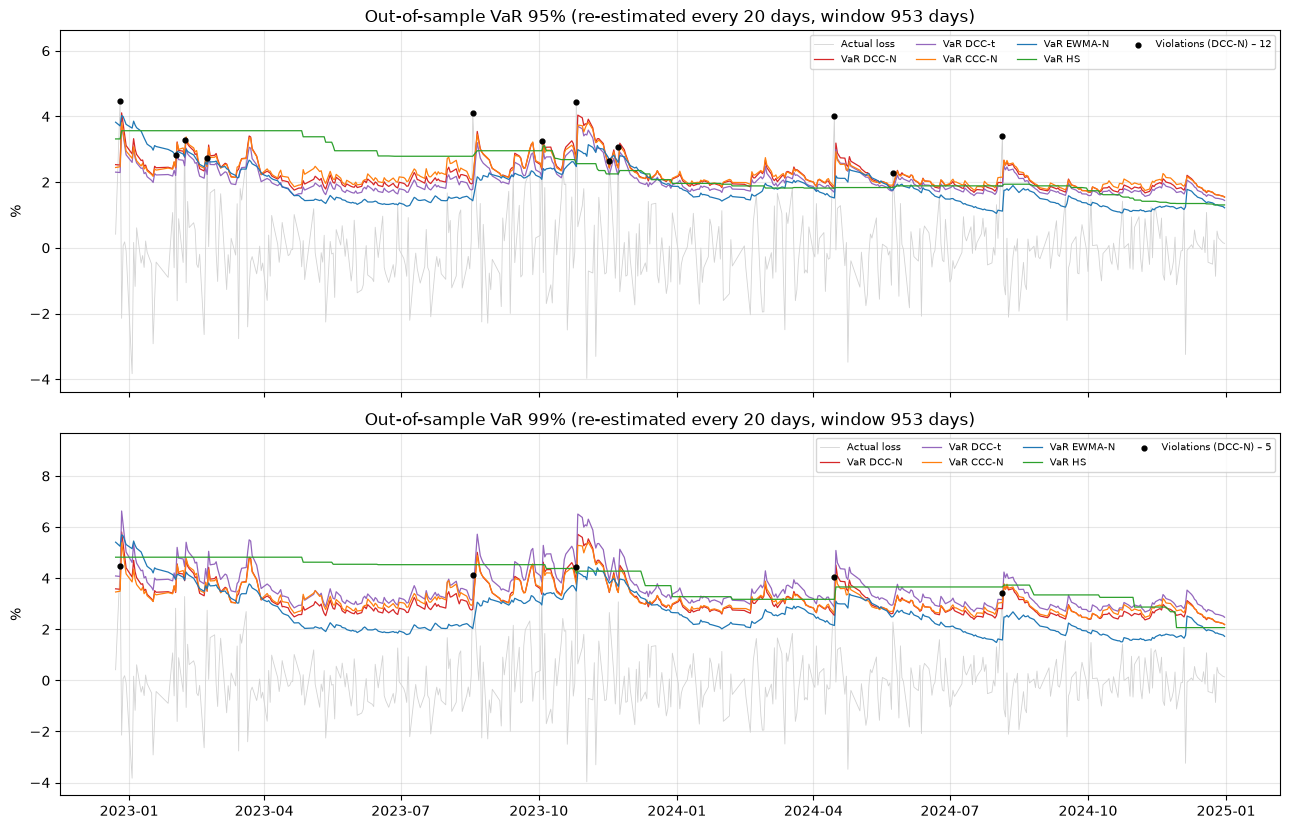

Note: both stress periods (Covid-19, Bond & interest-rate stress) lie BEFORE the out-of-sample window (2022-12-23 → 2024-12-31) so they are not shaded; the out-of-sample results reflect a relatively calm market. To test the 2022 crisis too, increase N_TEST (e.g. 700) – at the cost of a shorter estimation window.
✔ Saved Part 4 out-of-sample results to D:\Năm 3\Ứng dụng công nghệ trong TCNH\final 2\ouput\TV4_VaR_Backtest


In [39]:
# ===================== 4.5.7 PLOTS & SAVING OUT-OF-SAMPLE RESULTS =====================
fig, axes = plt.subplots(len(VAR_LEVELS), 1, figsize=(13, 4.2 * len(VAR_LEVELS)), sharex=True)
for ax, cl in zip(np.atleast_1d(axes), VAR_LEVELS):
    tag = f"{int(cl * 100)}"
    ax.plot(test_idx, oos["loss"] * 100, color="lightgrey", lw=0.6, label="Actual loss")
    for meth, c in zip(OOS_METHODS, ["tab:red", "tab:purple", "tab:orange", "tab:blue", "tab:green"]):
        ax.plot(test_idx, oos[f"VaR_{meth}_{tag}"] * 100, lw=0.9, color=c, label=f"VaR {meth}")
    br = oos["loss"] > oos[f"VaR_{VIOL_OOS}_{tag}"]
    ax.scatter(test_idx[br], oos["loss"][br] * 100, color="black", s=12, zorder=3, label=f"Violations ({VIOL_OOS}) – {int(br.sum())}")
    shade_stress(ax, alpha=0.08, xlim=(test_idx[0], test_idx[-1]))      # shade only periods inside the test window
    ax.set_title(f"Out-of-sample VaR {tag}% (re-estimated every {REFIT} days, window {WINDOW} days)")
    ax.set_ylabel("%"); ax.grid(alpha=0.3)
    ax.set_ylim(top=ax.get_ylim()[1] * 1.35)                           # leave room for the legend
    ax.legend(fontsize=7, ncol=4, loc="upper right")
plt.tight_layout(); plt.savefig(OUT["TV4"] / "4_oos_var_vs_loss.png", dpi=150, bbox_inches="tight"); plt.show()
if not any(pd.Timestamp(e_) >= test_idx[0] for _, (s_, e_) in STRESS.items()):
    print(f"Note: both stress periods (Covid-19, Bond & interest-rate stress) lie BEFORE the out-of-sample window "
          f"({test_idx[0].date()} → {test_idx[-1].date()}) so they are not shaded; the out-of-sample results reflect a relatively calm market. "
          f"To test the 2022 crisis too, increase N_TEST (e.g. 700) – at the cost of a shorter estimation window.")

with pd.ExcelWriter(OUT["TV4"] / "TV4_out_of_sample.xlsx", engine="openpyxl") as xw:
    oos_bt.to_excel(xw, sheet_name="Backtest_ngoai_mau", index=False)
    in_vs_out.to_excel(xw, sheet_name="Trong_vs_ngoai_mau", index=False)
    refit_log.to_excel(xw, sheet_name="Tham_so_moi_lan_refit", index=False)
    oos.to_excel(xw, sheet_name="VaR_ES_ngoai_mau")
print("✔ Saved Part 4 out-of-sample results to", OUT["TV4"])

In [40]:
# ===================== 4.5c AUTOMATIC OUT-OF-SAMPLE INTERPRETATION =====================
for cl in VAR_LEVELS:
    lv = f"{int(cl * 100)}%"
    sub = oos_bt[oos_bt["Confidence level"] == lv].set_index("Method")
    print(f"VaR {lv}:")
    for meth, r_ in sub.iterrows():
        print(f"  {meth:<7}: {r_['Actual violations']} violations / expected {r_['Expected violations']:.1f} ({r_['Violation rate (%)']:.1f}%) | "
              f"Kupiec p = {r_['Kupiec p']:.3f} | QL = {r_['Quantile loss (x1e4)']:.2f} (rank {r_['QL rank']}) -> {r_['Assessment']}")
    d = sub.loc["CCC-N", "Quantile loss (x1e4)"] - sub.loc["DCC-N", "Quantile loss (x1e4)"]
    print(f"  Forecasting value of dynamic correlation (QL CCC-N − QL DCC-N) = {d:+.3f}"
          + (" -> DCC beats CCC." if d > 0 else " -> DCC does NOT beat CCC out-of-sample."))
    print(f"  DCC-t vs DCC-N difference: average VaR {sub.loc['DCC-t', 'VaR TB (%)'] - sub.loc['DCC-N', 'VaR TB (%)']:+.2f} pp,  "
          f"QL {sub.loc['DCC-t', 'Quantile loss (x1e4)'] - sub.loc['DCC-N', 'Quantile loss (x1e4)']:+.3f}")

VaR 95%:
  DCC-N  : 12 violations / expected 25.0 (2.4%) | Kupiec p = 0.003 | QL = 14.11 (rank 3) -> OVERESTIMATES risk
  DCC-t  : 14 violations / expected 25.0 (2.8%) | Kupiec p = 0.014 | QL = 13.75 (rank 2) -> OVERESTIMATES risk
  CCC-N  : 12 violations / expected 25.0 (2.4%) | Kupiec p = 0.003 | QL = 14.20 (rank 4) -> OVERESTIMATES risk
  EWMA-N : 23 violations / expected 25.0 (4.6%) | Kupiec p = 0.678 | QL = 12.85 (rank 1) -> Violation frequency consistent
  HS     : 10 violations / expected 25.0 (2.0%) | Kupiec p = 0.000 | QL = 14.37 (rank 5) -> OVERESTIMATES risk
  Forecasting value of dynamic correlation (QL CCC-N − QL DCC-N) = +0.090 -> DCC beats CCC.
  DCC-t vs DCC-N difference: average VaR -0.18 pp,  QL -0.355
VaR 99%:
  DCC-N  : 5 violations / expected 5.0 (1.0%) | Kupiec p = 1.000 | QL = 4.22 (rank 4) -> Violation frequency consistent
  DCC-t  : 5 violations / expected 5.0 (1.0%) | Kupiec p = 1.000 | QL = 4.23 (rank 5) -> Violation frequency consistent
  CCC-N  : 5 violatio

## 4b Tail dependence with copulas & simulated portfolio VaR/ES

,log-lik,k,AIC,BIC,ν
Gaussian,759.81,10.0,-1499.63,-1446.82,NaN
Student-t,811.57,11.0,-1601.14,-1543.05,10.77


t-copula BETTER THAN Gauss by BIC (ν = 10.8: ν ≥ 10 => weak tail dependence, t-copula close to Gaussian).
Lower tail-dependence coefficient λ_L of the t-copula (Gaussian copula: λ_L = 0):


,FPT,HPG,MWG,VCB,VHM
FPT,1.000,0.053,0.083,0.037,0.033
HPG,0.053,1.000,0.050,0.032,0.034
MWG,0.083,0.050,1.000,0.032,0.028
VCB,0.037,0.032,0.032,1.000,0.043
VHM,0.033,0.034,0.028,0.043,1.000


Portfolio 1-day VaR/ES (% of portfolio value), session T+1:


,VaR 95%,ES 95%,VaR 99%,ES 99%,ES share FPT (%),ES share HPG (%),ES share MWG (%),ES share VCB (%),ES share VHM (%)
Gaussian copula,1.366,1.859,2.164,2.640,19.056,24.623,23.853,14.384,18.084
t copula,1.342,1.901,2.235,2.821,19.028,24.269,24.579,14.536,17.587
"Normal (DCC, section 4)",1.487,1.872,2.114,2.426,NaN,NaN,NaN,NaN,NaN
"Student-t (DCC, section 4)",1.374,2.053,2.404,3.316,NaN,NaN,NaN,NaN,NaN


ES 99%: t-copula / Gauss-copula = 1.069 -> ignoring tail dependence makes ES lower by about 6.9% (average λ_L across pairs = 0.043).


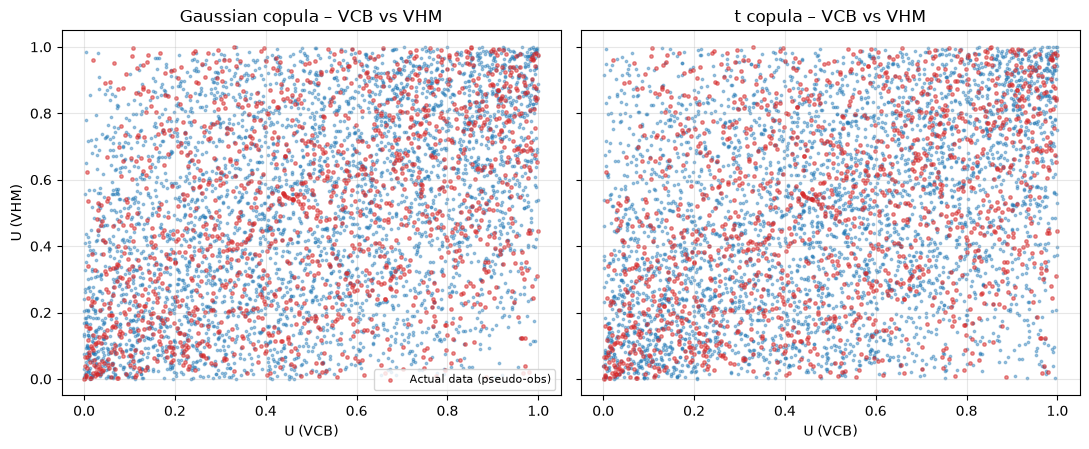

In [41]:
# ===================== 4b COPULA GAUSS vs STUDENT-t =====================
from scipy.optimize import minimize_scalar

T_c, d_ = std_resid.shape
U = (std_resid.rank() / (T_c + 1)).values                   # pseudo-observations ∈ (0, 1)


def nearest_corr(R, eps=1e-8):
    """Make the correlation matrix positive definite (if sin(πτ/2) breaks positive definiteness)."""
    ev, V = np.linalg.eigh((R + R.T) / 2)
    A = V @ np.diag(np.clip(ev, eps, None)) @ V.T
    s = 1 / np.sqrt(np.diag(A))
    return A * np.outer(s, s)


R_gauss = nearest_corr(np.corrcoef(stats.norm.ppf(U).T))
R_tc = nearest_corr(np.sin(np.pi / 2 * std_resid.corr(method="kendall").values))


def ll_gauss():
    x = stats.norm.ppf(U); Ri = np.linalg.inv(R_gauss)
    return float(np.sum(-0.5 * np.linalg.slogdet(R_gauss)[1] - 0.5 * np.einsum("ij,jk,ik->i", x, Ri - np.eye(d_), x)))


def ll_t(nu):
    x = stats.t.ppf(U, nu); q = np.einsum("ij,jk,ik->i", x, np.linalg.inv(R_tc), x)
    l = (gammaln((nu + d_) / 2) - gammaln(nu / 2) - d_ / 2 * np.log(nu * np.pi)
         - 0.5 * np.linalg.slogdet(R_tc)[1] - (nu + d_) / 2 * np.log1p(q / nu))
    return float(np.sum(l - stats.t.logpdf(x, nu).sum(axis=1)))


nu_c = float(minimize_scalar(lambda v: -ll_t(v), bounds=(2.5, 50), method="bounded").x)
llg, llt = ll_gauss(), ll_t(nu_c)
k_cop = d_ * (d_ - 1) // 2
cop_fit = pd.DataFrame({
    "Gaussian": {"log-lik": llg, "k": k_cop, "AIC": -2 * llg + 2 * k_cop, "BIC": -2 * llg + k_cop * np.log(T_c), "ν": np.nan},
    "Student-t": {"log-lik": llt, "k": k_cop + 1, "AIC": -2 * llt + 2 * (k_cop + 1),
                  "BIC": -2 * llt + (k_cop + 1) * np.log(T_c), "ν": nu_c}}).T
display(cop_fit.round(2))
print(f"t-copula {'BETTER THAN' if cop_fit.loc['Student-t', 'BIC'] < cop_fit.loc['Gaussian', 'BIC'] else 'NOT better than'} "
      f"Gauss by BIC (ν = {nu_c:.1f}: " + ("ν < 10 => substantial tail dependence)." if nu_c < 10 else "ν ≥ 10 => weak tail dependence, t-copula close to Gaussian)."))

lam = 2 * stats.t.cdf(-np.sqrt((nu_c + 1) * np.clip(1 - R_tc, 0, None) / (1 + R_tc)), nu_c + 1)   # lower tail dependence of the t-copula
np.fill_diagonal(lam, 1.0)
tail_dep = pd.DataFrame(lam, index=tickers, columns=tickers)
print("Lower tail-dependence coefficient λ_L of the t-copula (Gaussian copula: λ_L = 0):")
display(tail_dep.round(3))
lam_off = lam[~np.eye(d_, dtype=bool)].mean()

# ---- Simulate the portfolio's 1-day loss (margins = empirical residuals, μ & σ forecast for T+1) ----
M, rng = 200_000, np.random.default_rng(2024)
mu1 = mu_vec.loc[tickers].values                              # decimal
sd1 = sigma_fcst.loc[tickers].values
emp = np.sort(std_resid.values, axis=0)


def simulate(copula):
    G = rng.standard_normal((M, d_))
    if copula == "Gaussian":
        u = stats.norm.cdf(G @ np.linalg.cholesky(R_gauss).T)
    else:
        W = rng.chisquare(nu_c, (M, 1)) / nu_c
        u = stats.t.cdf(G @ np.linalg.cholesky(R_tc).T / np.sqrt(W), nu_c)
    z = np.take_along_axis(emp, np.minimum((u * T_c).astype(int), T_c - 1), axis=0)
    return -(mu1 + sd1 * z), u                                # loss per ticker (decimal), copula sample


rows, sims = {}, {}
for cop in ("Gaussian", "t"):
    L, u = simulate(cop); sims[cop] = u; Lp = L @ w
    row = {}
    for cl in VAR_LEVELS:
        v = np.quantile(Lp, cl); tail = Lp >= v
        row[f"VaR {int(cl * 100)}%"] = v * 100
        row[f"ES {int(cl * 100)}%"] = Lp[tail].mean() * 100
    tail = Lp >= np.quantile(Lp, EULER_CL)
    for c, s in zip(tickers, w * L[tail].mean(axis=0) / Lp[tail].mean()):
        row[f"ES share {c} (%)"] = s * 100
    rows[f"{cop} copula"] = row

sig_p1 = float(np.sqrt(w @ H_fcst @ w)); mu_p1 = float(w @ mu1)
for lab, fun in [("Normal (DCC, section 4)", lambda a: var_es_normal(sig_p1, a)),
                 ("Student-t (DCC, section 4)", (lambda a: var_es_t(sig_p1, a, nu_p)) if "nu_p" in globals() else None)]:
    if fun is None:
        continue
    row = {}
    for cl in VAR_LEVELS:
        v, e = fun(1 - cl)
        row[f"VaR {int(cl * 100)}%"], row[f"ES {int(cl * 100)}%"] = (v - mu_p1) * 100, (e - mu_p1) * 100
    rows[lab] = row
cop_tbl = pd.DataFrame(rows).T
print("Portfolio 1-day VaR/ES (% of portfolio value), session T+1:")
display(cop_tbl.round(3))
key = f"ES {int(EULER_CL * 100)}%"
es_ratio = cop_tbl.loc["t copula", key] / cop_tbl.loc["Gaussian copula", key]
print(f"{key}: t-copula / Gauss-copula = {es_ratio:.3f} -> " + (
    "negligible difference (< 1%)" if abs(es_ratio - 1) < 0.01 else
    f"ignoring tail dependence makes ES {'lower' if es_ratio > 1 else 'higher'} by about {abs(es_ratio - 1):.1%}")
    + f" (average λ_L across pairs = {lam_off:.3f}).")

pa, pb = (PAIRS[0] if all(p in tickers for p in PAIRS[0]) else tuple(tickers[:2]))
ia, ib_ = tickers.index(pa), tickers.index(pb)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, cop in zip(axes, ("Gaussian", "t")):
    u = sims[cop][:4000]
    ax.scatter(u[:, ia], u[:, ib_], s=3, alpha=0.4)
    ax.scatter(U[:, ia], U[:, ib_], s=6, color="tab:red", alpha=0.5, label="Actual data (pseudo-obs)")
    ax.set_title(f"{cop} copula – {pa} vs {pb}"); ax.set_xlabel(f"U ({pa})"); ax.grid(alpha=0.3)
axes[0].set_ylabel(f"U ({pb})"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT["TV4"] / "4b_copula_scatter.png", dpi=150); plt.show()

cop_fit.to_csv(OUT["TV4"] / "4b_copula_fit.csv", encoding="utf-8-sig")
tail_dep.to_csv(OUT["TV4"] / "4b_tail_dependence.csv", encoding="utf-8-sig")
cop_tbl.to_csv(OUT["TV4"] / "4b_copula_var_es.csv", encoding="utf-8-sig")


---
# PART 5: EULER RISK ALLOCATION & STRESS TESTING
## 5.0 Integration check

In [42]:
# ===================== 5.0 INTEGRATION CHECK =====================
eig_min_all = np.linalg.eigvalsh(H_t).min()
checks = [
    ("Same ticker list in Parts 1/2/3", "TV5", list(log_ret.columns) == list(std_resid.columns) == list(cond_vol.columns) == tickers, ", ".join(tickers)),
    ("Same date calendar in Parts 1/2/4", "TV5", log_ret.index.equals(std_resid.index) and log_ret.index.equals(var_es.index),
     f"{len(log_ret)} sessions {log_ret.index[0].date()} → {log_ret.index[-1].date()}"),
    ("H_t has shape T × N × N", "TV5", H_t.shape == (T, N, N), str(H_t.shape)),
    ("No NaN in r, ε, σ, H", "TV5", not (log_ret.isna().any().any() or std_resid.isna().any().any()
                                                  or cond_vol.isna().any().any() or np.isnan(H_t).any()), ""),
    ("sqrt(diag H_t) = σ_t (TV2 ↔ TV3)", "TV5", np.allclose(np.sqrt(np.einsum("tii->ti", H_t)), cond_vol.values), ""),
    ("H_t symmetric & positive definite", "TV5", np.allclose(H_t, H_t.transpose(0, 2, 1)) and eig_min_all > 0, f"λ_min = {eig_min_all:.2e}"),
    ("DCC stationary: a ≥ 0, b ≥ 0, a + b < 1", "TV5", bool(ok_stat), f"a + b = {a_hat + b_hat:.4f}"),
    ("σ_p of Part 4 = sqrt(w'H_t w) with the same w", "TV5", np.allclose(sigma_p.values, np.sqrt(np.einsum("i,tij,j->t", w, H_t, w))),
     "w = " + str({tk: round(float(x), 4) for tk, x in zip(tickers, w)})),
    ("Weights sum to 1", "TV5", np.isclose(w.sum(), 1), ""),
    ("All univariate GARCH models converge", "TV5", all(f["converged"] for f in selected.values()), ""),
    ("Out-of-sample VaR/ES: N_TEST days, no NaN, same calendar as var_es", "TV5",
     len(oos) == N_TEST and not oos.isna().any().any() and oos.index.isin(var_es.index).all(), f"{len(oos)} sessions"),
]
integration = pd.DataFrame(checks, columns=["Item", "Part", "Pass", "Note"])
display(integration)
integration.to_csv(OUT["TV5"] / "integration_check.csv", index=False, encoding="utf-8-sig")
print("✔ The whole pipeline Part 1 → Part 4 is consistent." if integration["Pass"].all() else "✘ SOME ITEMS FAILED – see the table above.")

,Item,Part,Pass,Note
0,Same ticker list in Parts 1/2/3,TV5,True,"FPT, HPG, MWG, VCB, VHM"
1,Same date calendar in Parts 1/2/4,TV5,True,1453 sessions 2019-01-03 → 2024-12-31
2,H_t has shape T × N × N,TV5,True,"(1453, 5, 5)"
3,"No NaN in r, ε, σ, H",TV5,True,
4,sqrt(diag H_t) = σ_t (TV2 ↔ TV3),TV5,True,
5,H_t symmetric & positive definite,TV5,True,λ_min = 7.03e-05
6,"DCC stationary: a ≥ 0, b ≥ 0, a + b < 1",TV5,True,a + b = 0.9581
7,σ_p of Part 4 = sqrt(w'H_t w) with the same w,TV5,True,"w = {'FPT': 0.2, 'HPG': 0.2, 'MWG': 0.2, 'VCB'..."
8,Weights sum to 1,TV5,True,
9,All univariate GARCH models converge,TV5,True,


✔ The whole pipeline Part 1 → Part 4 is consistent.


## 5.1 Euler risk contributions

Euler additivity check:  max_t |Σ RC_i − VaR_p| = 2.78e-17 -> PASS
Matches the Normal VaR 99% of Part 4: True

Forecast for session T+1 (after 2024-12-31): VaR_p 99% = 2.1414% | Σ RC_i = 2.1414%


,w_i (%),σ_i T+1 (%/day),MC-VaR_i,RC_i (%),%RC_i,%RC_i − w_i (pp)
FPT,20.0,1.218,0.019,0.387,18.089,-1.911
HPG,20.0,1.414,0.025,0.493,23.038,3.038
MWG,20.0,1.522,0.026,0.527,24.607,4.607
VCB,20.0,1.159,0.017,0.331,15.479,-4.521
VHM,20.0,1.340,0.020,0.402,18.787,-1.213
TOTAL,100.0,NaN,NaN,2.141,100.000,0.000


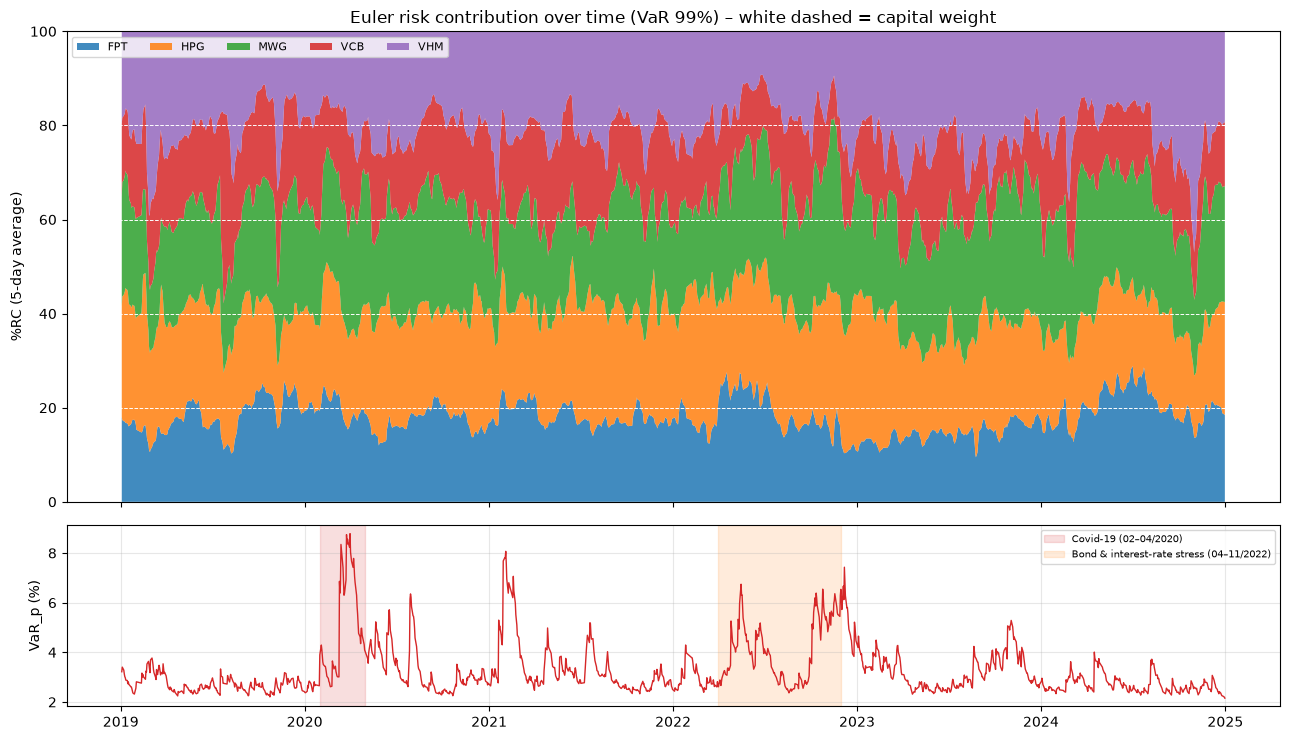

In [43]:
# ===================== 5.1 EULER RC =====================
z_cl = stats.norm.ppf(EULER_CL)


def euler(H, w):
    """Returns VaR_p, MC-VaR (N), RC (N) for a matrix H (N×N)."""
    sp = np.sqrt(w @ H @ w)
    mc = z_cl * (H @ w) / sp
    rc = w * mc
    return z_cl * sp, mc, rc


Hw = np.einsum("tij,j->ti", H_t, w)
VaR_p_ts = z_cl * sigma_p.values
MC_ts = z_cl * Hw / sigma_p.values[:, None]
RC_ts = w * MC_ts
pct_rc = pd.DataFrame(RC_ts / VaR_p_ts[:, None] * 100, index=log_ret.index, columns=tickers)
err = np.abs(RC_ts.sum(axis=1) - VaR_p_ts).max()
print(f"Euler additivity check:  max_t |Σ RC_i − VaR_p| = {err:.2e} -> {'PASS' if err < 1e-10 else 'FAIL'}")
print(f"Matches the Normal VaR {int(EULER_CL * 100)}% of Part 4: "
      f"{np.allclose(VaR_p_ts, var_es[f'VaR_Normal_{int(EULER_CL * 100)}'].values)}")

VaR_f, MC_f, RC_f = euler(H_fcst, w)
tbl_fcst = pd.DataFrame({"w_i (%)": w * 100, "σ_i T+1 (%/day)": sigma_fcst.values * 100, "MC-VaR_i": MC_f,
                         "RC_i (%)": RC_f * 100, "%RC_i": RC_f / VaR_f * 100}, index=tickers)
tbl_fcst["%RC_i − w_i (pp)"] = tbl_fcst["%RC_i"] - tbl_fcst["w_i (%)"]
tbl_fcst.loc["TOTAL"] = [100, np.nan, np.nan, RC_f.sum() * 100, 100, 0]
print(f"\nForecast for session T+1 (after {log_ret.index[-1].date()}): VaR_p {int(EULER_CL * 100)}% = {VaR_f:.4%} | Σ RC_i = {RC_f.sum():.4%}")
display(tbl_fcst.round(3))

# ---- Export the full daily series: MC-VaR, RC, %RC, VaR_p (keeps the old file format) ----
mc_df = pd.DataFrame(MC_ts, index=log_ret.index, columns=tickers)
rc_df = pd.DataFrame(RC_ts, index=log_ret.index, columns=tickers)
euler_daily = pd.concat({"MC_VaR": mc_df, "RC": rc_df, "PctRC": pct_rc / 100,
                         "Portfolio": pd.DataFrame({"VaR_p": VaR_p_ts}, index=log_ret.index)}, axis=1)
euler_daily.index.name = "Date"
euler_daily.to_csv(OUT["TV5"] / "euler_rc_timeseries.csv", encoding="utf-8-sig")

# ---- Figure: %RC smoothed over 5 days (less noise); white dashed = cumulative capital weight ----
pct_sm = pct_rc.rolling(5, min_periods=1).mean()
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True, gridspec_kw={"height_ratios": [2.6, 1]})
axes[0].stackplot(pct_sm.index, pct_sm.T.values, labels=tickers, alpha=0.85)
for c_ in np.cumsum(w)[:-1] * 100:
    axes[0].axhline(c_, color="white", ls="--", lw=0.7)
axes[0].set_ylim(0, 100); axes[0].set_ylabel("%RC (5-day average)")
axes[0].set_title(f"Euler risk contribution over time (VaR {int(EULER_CL * 100)}%) – white dashed = capital weight")
axes[0].legend(ncol=N, fontsize=8, loc="upper left")
axes[1].plot(log_ret.index, VaR_p_ts * 100, color="tab:red", lw=1)
shade_stress(axes[1], alpha=0.15)
axes[1].set_ylabel("VaR_p (%)"); axes[1].grid(alpha=0.3); axes[1].legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.savefig(OUT["TV5"] / "5_euler_rc_timeseries.png", dpi=150); plt.show()


## 5.2 Stress period analysis

Portfolio overview by period (cumulative return depends on period length – compare using the daily average row):


,Non-stress,Covid-19 (02–04/2020),Bond & interest-rate stress (04–11/2022)
Sessions,1225.000,61.000,167.000
Cumulative portfolio return over the period (%),341.047,-18.554,-27.088
Average daily portfolio return (%),0.121,-0.336,-0.189
Average annualised portfolio return (%) – reference,30.528,-84.785,-47.671
Annualised σ_p (%),21.022,35.714,28.117
VaR_p 99% TB (%),3.081,5.234,4.121
Largest 1-day loss (%),7.215,7.212,5.007
Average pairwise correlation,0.358,0.459,0.378
Diversification ratio DR,1.435,1.324,1.396
Diversification benefit 1 − 1/DR (%),30.103,24.234,28.241


Average risk-contribution share %RC_i by period:


,Weight w (%),Non-stress,Covid-19 (02–04/2020),Bond & interest-rate stress (04–11/2022),Δ%RC Covid-19 (02–04/2020) (pp),Δ%RC Bond & interest-rate stress (04–11/2022) (pp)
FPT,20.0,17.66,20.06,19.57,2.40,1.90
HPG,20.0,22.23,22.17,24.46,-0.06,2.24
MWG,20.0,22.25,24.63,26.22,2.39,3.97
VCB,20.0,15.78,14.44,13.56,-1.34,-2.22
VHM,20.0,22.08,18.70,16.19,-3.38,-5.89


Average MC-VaR_i by period (decimal):


,Non-stress,Covid-19 (02–04/2020),Bond & interest-rate stress (04–11/2022)
FPT,0.0268,0.0502,0.0404
HPG,0.0346,0.0552,0.0513
MWG,0.0340,0.0645,0.0554
VCB,0.0241,0.0404,0.0266
VHM,0.0344,0.0514,0.0322



[Covid-19 (02–04/2020)]
  • Largest risk contribution: MWG (24.6% of VaR, weight 20%).
  • Largest increase in contribution vs non-stress: FPT (+2.4 pp); largest decrease: VHM (-3.4 pp).
  • Annualised σ_p: 21.0% → 35.7%; average correlation: 0.358 → 0.459; diversification benefit: 30.1% → 24.2%.

[Bond & interest-rate stress (04–11/2022)]
  • Largest risk contribution: MWG (26.2% of VaR, weight 20%).
  • Largest increase in contribution vs non-stress: MWG (+4.0 pp); largest decrease: VHM (-5.9 pp).
  • Annualised σ_p: 21.0% → 28.1%; average correlation: 0.358 → 0.378; diversification benefit: 30.1% → 28.2%.


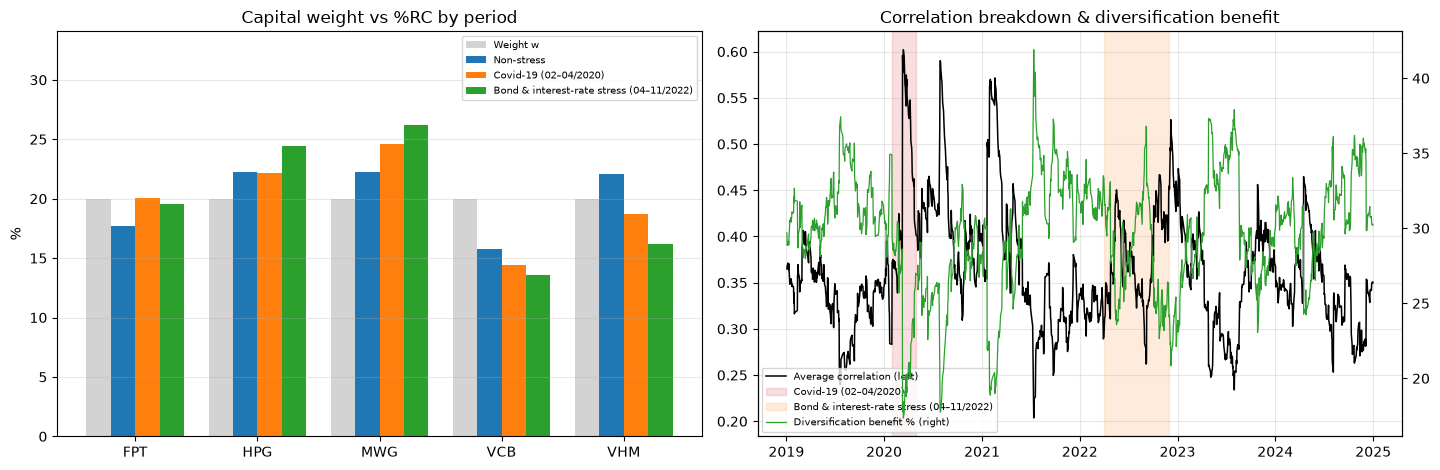

In [44]:
# ===================== 5.2 STRESS PERIODS =====================
ann = np.sqrt(TRADING_DAYS)
hits99 = (-var_es["r_p"] > var_es[f"VaR_Normal_{int(EULER_CL * 100)}"]).where(var_es.index >= bt.index[0])
DR = undiv / sigma_p
stress_summary = pd.DataFrame({name: {
    "Sessions": int(m.sum()),
    "Cumulative portfolio return over the period (%)": (np.exp(r_p[m].sum()) - 1) * 100,   # used instead of annualised figures, which can mislead
    "Average daily portfolio return (%)": r_p[m].mean() * 100,
    "Average annualised portfolio return (%) – reference": r_p[m].mean() * TRADING_DAYS * 100,
    "Annualised σ_p (%)": sigma_p[m].mean() * ann * 100,
    f"VaR_p {int(EULER_CL * 100)}% TB (%)": VaR_p_ts[m].mean() * 100,
    "Largest 1-day loss (%)": -r_p[m].min() * 100,
    "Average pairwise correlation": avg_corr[m].mean(),
    "Diversification ratio DR": DR[m].mean(),
    "Diversification benefit 1 − 1/DR (%)": (1 - 1 / DR[m]).mean() * 100,
    f"VaR-N violation rate {int(EULER_CL * 100)}% (%)": hits99[m].mean() * 100,
} for name, m in masks.items()})
print("Portfolio overview by period (cumulative return depends on period length – compare using the daily average row):"); display(stress_summary.round(3))

prc_period = pd.DataFrame({name: pct_rc[m].mean() for name, m in masks.items()})
prc_period.insert(0, "Weight w (%)", w * 100)
mc_period = pd.DataFrame({name: mc_df[m].mean() for name, m in masks.items()})     # average MC-VaR by period
for name in STRESS:
    prc_period[f"Δ%RC {name} (pp)"] = prc_period[name] - prc_period["Non-stress"]
print("Average risk-contribution share %RC_i by period:"); display(prc_period.round(2))
print("Average MC-VaR_i by period (decimal):"); display(mc_period.round(4))

for name in STRESS:
    m = masks[name]
    top = prc_period[name].idxmax()
    up = prc_period[f"Δ%RC {name} (pp)"].idxmax()
    dn = prc_period[f"Δ%RC {name} (pp)"].idxmin()
    print(f"\n[{name}]")
    print(f"  • Largest risk contribution: {top} ({prc_period.loc[top, name]:.1f}% of VaR, weight {w[idx_tk[top]] * 100:.0f}%).")
    print(f"  • Largest increase in contribution vs non-stress: {up} ({prc_period.loc[up, f'Δ%RC {name} (pp)']:+.1f} pp); "
          f"largest decrease: {dn} ({prc_period.loc[dn, f'Δ%RC {name} (pp)']:+.1f} pp).")
    print(f"  • Annualised σ_p: {stress_summary.loc['Annualised σ_p (%)', 'Non-stress']:.1f}% → {stress_summary.loc['Annualised σ_p (%)', name]:.1f}%; "
          f"average correlation: {stress_summary.loc['Average pairwise correlation', 'Non-stress']:.3f} → {stress_summary.loc['Average pairwise correlation', name]:.3f}; "
          f"diversification benefit: {stress_summary.loc['Diversification benefit 1 − 1/DR (%)', 'Non-stress']:.1f}% → "
          f"{stress_summary.loc['Diversification benefit 1 − 1/DR (%)', name]:.1f}%.")

cols_p = ["Non-stress"] + list(STRESS)
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))
xpos, bw = np.arange(N), 0.2
axes[0].bar(xpos - 1.5 * bw, w * 100, bw, color="lightgrey", label="Weight w")
for j, (cn, col) in enumerate(zip(cols_p, ["tab:blue", "tab:orange", "tab:green"])):
    axes[0].bar(xpos + (j - 0.5) * bw, prc_period[cn].values, bw, color=col, label=cn)
axes[0].set_xticks(xpos); axes[0].set_xticklabels(tickers); axes[0].set_ylabel("%")
axes[0].set_title("Capital weight vs %RC by period"); axes[0].grid(alpha=0.3, axis="y")
axes[0].set_ylim(0, max(prc_period[cols_p].values.max(), w.max() * 100) * 1.3)
axes[0].legend(fontsize=7, loc="upper right")
l1, = axes[1].plot(avg_corr.index, avg_corr, color="black", lw=1.1, label="Average correlation (left)")
ax2 = axes[1].twinx()
l2, = ax2.plot(DR.index, (1 - 1 / DR) * 100, color="tab:green", lw=0.9, label="Diversification benefit % (right)")
shade_stress(axes[1], alpha=0.15)
h_sh, l_sh = axes[1].get_legend_handles_labels()
axes[1].set_title("Correlation breakdown & diversification benefit"); axes[1].grid(alpha=0.3)
axes[1].legend(h_sh + [l2], l_sh + [l2.get_label()], fontsize=7, loc="lower left")
plt.tight_layout(); plt.savefig(OUT["TV5"] / "5_stress_periods.png", dpi=150); plt.show()


### 5.2b Correlation breakdown scenarios

In [45]:
# ===================== 5.2b CORRELATION SCENARIOS =====================
scen = {"ρ forecast T+1 (DCC)": R_fcst}
scen.update({f"ρ TB {name}": R_t[m].mean(axis=0) for name, m in masks.items()})
scen["ρ = 1 (worst case)"] = np.ones((N, N))
rows = {}
for name, R in scen.items():
    Hs = R * np.outer(sigma_fcst.values, sigma_fcst.values)
    v, _, rc = euler(Hs, w)
    rows[name] = {"VaR_p (%)": v * 100, **{f"%RC {tk}": rc[i] / v * 100 for i, tk in enumerate(tickers)}}
corr_scen = pd.DataFrame(rows).T
display(corr_scen.round(3))
base_var = corr_scen.iloc[0, 0]
for k in corr_scen.index[1:]:
    v = corr_scen.loc[k, "VaR_p (%)"]
    print(f"• With {k}: VaR_p = {v:.2f}% ({(v / base_var - 1):+.1%} vs the DCC forecast {base_var:.2f}%)")

,VaR_p (%),%RC FPT,%RC HPG,%RC MWG,%RC VCB,%RC VHM
ρ forecast T+1 (DCC),2.141,18.089,23.038,24.607,15.479,18.787
ρ TB Non-stress,2.163,19.155,22.170,23.813,15.787,19.076
ρ TB Covid-19 (02–04/2020),2.339,18.456,22.056,24.222,15.976,19.290
ρ TB Bond & interest-rate stress (04–11/2022),2.200,19.168,21.628,24.437,15.476,19.291
ρ = 1 (worst case),3.095,18.305,21.257,22.873,17.426,20.139


• With ρ TB Non-stress: VaR_p = 2.16% (+1.0% vs the DCC forecast 2.14%)
• With ρ TB Covid-19 (02–04/2020): VaR_p = 2.34% (+9.2% vs the DCC forecast 2.14%)
• With ρ TB Bond & interest-rate stress (04–11/2022): VaR_p = 2.20% (+2.7% vs the DCC forecast 2.14%)
• With ρ = 1 (worst case): VaR_p = 3.10% (+44.5% vs the DCC forecast 2.14%)


### 5.2c Equal Risk Contribution (risk parity) portfolio

In [46]:
# ===================== 5.2c RISK PARITY (ERC) =====================
def risk_parity(Hm, n_iter=1000, tol=1e-12):
    wv = np.ones(len(Hm)) / len(Hm)
    for _ in range(n_iter):
        mrc = Hm @ wv
        new = 1 / mrc
        new /= new.sum()
        new = 0.5 * wv + 0.5 * new                      # damping step for stable convergence
        if np.abs(new - wv).max() < tol:
            break
        wv = new
    return wv


w_erc = risk_parity(H_fcst)
v_erc, _, rc_erc = euler(H_fcst, w_erc)
rp_table = pd.DataFrame({"Current w (%)": w * 100, "Current %RC": RC_f / VaR_f * 100,
                         "w ERC (%)": w_erc * 100, "%RC ERC": rc_erc / v_erc * 100}, index=tickers)
for name, m in masks.items():                           # ERC based on the average H_t of each (stress) period
    if name != "Non-stress":
        rp_table[f"ERC theo H TB {name} (%)"] = risk_parity(H_t[m].mean(axis=0)) * 100
display(rp_table.round(2))
print(f"VaR_p {int(EULER_CL * 100)}% (T+1): current = {VaR_f:.3%} | ERC portfolio = {v_erc:.3%}")

,Current w (%),Current %RC,w ERC (%),%RC ERC,ERC theo H TB Covid-19 (02–04/2020) (%),ERC theo H TB Bond & interest-rate stress (04–11/2022) (%)
FPT,20.0,18.09,21.55,20.0,21.25,19.50
HPG,20.0,23.04,17.49,20.0,19.53,15.64
MWG,20.0,24.61,16.63,20.0,16.51,14.59
VCB,20.0,15.48,23.82,20.0,23.41,27.16
VHM,20.0,18.79,20.51,20.0,19.31,23.11


VaR_p 99% (T+1): current = 2.141% | ERC portfolio = 2.099%


## 5.3 Interpretation & risk-management recommendations

In [47]:
# ===================== 5.3 AUTOMATIC RECOMMENDATIONS =====================
over = tbl_fcst.drop("TOTAL")["%RC_i − w_i (pp)"].sort_values(ascending=False)
lines = ["RISK-MANAGEMENT RECOMMENDATIONS (auto-generated from the results)", "=" * 80,
         "1. Current risk concentration (T+1): " + ", ".join(
             f"{tk} carries {tbl_fcst.loc[tk, '%RC_i']:.1f}% of risk with {tbl_fcst.loc[tk, 'w_i (%)']:.0f}% of capital"
             for tk in over.index[over > 0]) + " -> candidate to REDUCE weight.",
         "   Tickers contributing less risk than their weight (good diversifiers): " + ", ".join(over[over <= 0].sort_values().index) + "."]
for i, name in enumerate(STRESS, start=1):
    s = stress_summary[name]; nrm = stress_summary["Non-stress"]
    up = prc_period[f"Δ%RC {name} (pp)"].idxmax()
    lines.append(f"2.{i} {name}: σ_p rises {s['Annualised σ_p (%)'] / nrm['Annualised σ_p (%)']:.2f} times, average correlation "
                 f"{nrm['Average pairwise correlation']:.2f} → {s['Average pairwise correlation']:.2f}, diversification benefit "
                 f"{nrm['Diversification benefit 1 − 1/DR (%)']:.1f}% → {s['Diversification benefit 1 − 1/DR (%)']:.1f}%; "
                 f"{up} has the largest increase in contribution ({prc_period.loc[up, f'Δ%RC {name} (pp)']:+.1f} pp).")
lines += [
    "3. When the market enters a stress phase (σ_p or average correlation above historical thresholds): cut the weights of tickers with the largest %RC − w,"
    " shift gradually towards the ERC portfolio (risk-parity table), and/or reduce TOTAL exposure rather than only swapping tickers, since rising correlation weakens diversification among domestic stocks.",
    "4. Sector diversification: keep it (cross-sector tickers have lower correlation), BUT the benefit erodes in a crisis (DR falls) ->  "
    "for large portfolios add assets with low correlation to equities (government bonds, deposits, gold).",
    "5. Use Euler RC as limits: cap %RC_i (e.g. ≤ 30% of VaR) and warn early when %RC_i − w_i > 5 pp, monitored daily with H_t from DCC;  "
    "per-ticker VaR limit = %RC_i × total VaR; breach -> rebalance. Currently above the 5 pp warning threshold: "
    + (", ".join(over.index[over > 5]) or "none") + ".",
    f"6. Part 4 backtest (in-sample, VaR 99%): " + "; ".join(f"{r['Method']}: {r['Violations']}/{r['Expected']:.0f} violations ({r['Conclusion']})" for _, r in bt_table.iterrows()
                                                         if r["Confidence level"] == "99%") + ". "
    + "Out-of-sample (re-estimated every {} days): ".format(REFIT)
    + "; ".join(f"VaR {lv}: best by quantile loss = "
                f"{oos_bt[oos_bt['Confidence level'] == lv].set_index('Method')['Quantile loss (x1e4)'].idxmin()}, "
                f"methods flagged as over-/under-estimating risk = "
                f"{', '.join(oos_bt[(oos_bt['Confidence level'] == lv) & oos_bt['Assessment'].str.contains('UNDER|OVER')]['Method']) or 'none'}"
                for lv in ['95%', '99%'])
    + ". Choose the reporting model based on the out-of-sample results before using it for capital calculation.",
]
rec_text = "\n".join(lines)
print(rec_text)
(OUT["TV5"] / "recommendations.txt").write_text(rec_text, encoding="utf-8")

with pd.ExcelWriter(OUT["TV5"] / "TV5_euler_stress.xlsx", engine="openpyxl") as xw:
    integration.to_excel(xw, sheet_name="Kiem_tra_tich_hop", index=False)
    tbl_fcst.to_excel(xw, sheet_name="Euler_T+1")
    stress_summary.to_excel(xw, sheet_name="Stress_tong_quan")
    prc_period.to_excel(xw, sheet_name="PctRC_theo_giai_doan")
    corr_scen.to_excel(xw, sheet_name="Kich_ban_tuong_quan")
    rp_table.to_excel(xw, sheet_name="Risk_parity")
    mc_period.to_excel(xw, sheet_name="MC_VaR_theo_giai_doan")
    pct_rc.to_excel(xw, sheet_name="PctRC_hang_ngay")
print(f"\n✔ FULL PIPELINE COMPLETE. Results are in: {ROOT_OUT}")

RISK-MANAGEMENT RECOMMENDATIONS (auto-generated from the results)
1. Current risk concentration (T+1): MWG carries 24.6% of risk with 20% of capital, HPG carries 23.0% of risk with 20% of capital -> candidate to REDUCE weight.
   Tickers contributing less risk than their weight (good diversifiers): VCB, FPT, VHM.
2.1 Covid-19 (02–04/2020): σ_p rises 1.70 times, average correlation 0.36 → 0.46, diversification benefit 30.1% → 24.2%; FPT has the largest increase in contribution (+2.4 pp).
2.2 Bond & interest-rate stress (04–11/2022): σ_p rises 1.34 times, average correlation 0.36 → 0.38, diversification benefit 30.1% → 28.2%; MWG has the largest increase in contribution (+4.0 pp).
3. When the market enters a stress phase (σ_p or average correlation above historical thresholds): cut the weights of tickers with the largest %RC − w, shift gradually towards the ERC portfolio (risk-parity table), and/or reduce TOTAL exposure rather than only swapping tickers, since rising correlation weakens 

## 6. Conclusions, limitations and future work

In [48]:
# ===================== 6. AUTOMATIC CONCLUSIONS =====================
def _g(fn, default="(no results for this section yet)"):
    try:
        return fn()
    except Exception:
        return default


Ls = ["GENERAL CONCLUSIONS (auto-generated from the results)", "=" * 80]
Ls.append("1. Stylized facts: " + _g(lambda: (
    f"{int((desc['Kurtosis'] > 3).sum())}/{N} tickers have kurtosis > 3 (fat tails); "
    f"ARCH-LM rejects H0 for {int((archlm[archlm['Lag'] == archlm['Lag'].max()]['p-value'] < ALPHA).sum())}/{N} tickers "
    f"-> volatility clustering present, so use the GARCH family with fat-tailed distributions.")))
Ls.append("2. Mean model: " + _g(lambda: (
    f"{int(mean_tbl['Conclusion'].str.startswith('Keep').sum())}/{N} tickers: a constant mean is reasonable (ARMA does not improve materially).")))
Ls.append("3. Variance model: " + _g(lambda: (
    "selected by BIC: " + ", ".join(f"{tk}: {best_name[tk]}" for tk in tickers) + ". "
    f"Out-of-sample (QLIKE): the BIC-selected model is also the winner for {int((cmp_oos['Matches BIC?'] == 'YES').sum())}/{N} tickers; "
    f"EWMA wins for {int((cmp_oos['Best QLIKE'] == 'EWMA 0.94').sum())}/{N} tickers.")))
def _dcc_text():
    txt = (f"a = {a_hat:.4f}, b = {b_hat:.4f}, a + b = {a_hat + b_hat:.4f} (half-life {half_life_corr:.0f} sessions) -> ")
    txt += ("parameter a is statistically significant: correlation changes over time"
            if dcc_params.loc["a", "p-value"] < ALPHA else "parameter a is insignificant: weak evidence of dynamic correlation")
    txt += ("; a + b > 0.9: correlation shocks persist; " if a_hat + b_hat > 0.9 else "; a + b ≤ 0.9: correlation shocks fade quickly; ")
    txt += f"full-sample average correlation = {dyn_corr.values.mean():.2f}"
    txt += "; " + "; ".join(f"{k}: {v['Average pairwise correlation']:.2f}" for k, v in stress_summary.items()) + "."
    return txt


Ls.append("4. Dynamic correlation (DCC): " + _g(_dcc_text))
Ls.append("5. Additional multivariate models: " + _g(lambda: (
    (f"VAR({var_res.k_ar}): {n_sig}/{N * (N - 1)} Granger relations significant; " if var_ok else "VAR not run; ")
    + (f"Johansen cointegration rank = {rank}." if coint_ok else "cointegration not run."))))
Ls.append("6. VaR 99% backtest (in-sample): " + _g(lambda: "; ".join(
    f"{r['Method']}: {r['Violations']}/{r['Expected']:.0f} violations ({r['Conclusion']})"
    for _, r in bt_table.iterrows() if r["Confidence level"] == "99%")))
Ls.append("7. Out-of-sample VaR/ES: " + _g(lambda: "; ".join(
    f"VaR {lv}: best by quantile loss = "
    f"{oos_bt[oos_bt['Confidence level'] == lv].set_index('Method')['Quantile loss (x1e4)'].idxmin()}"
    for lv in ["95%", "99%"]) + "."))
Ls.append("8. Tail dependence (copula): " + _g(lambda: (
    f"t-copula ν = {nu_c:.1f}, average λ_L = {lam_off:.3f}; the t-copula 99% ES equals {es_ratio:.2f} times the Gaussian-copula ES.")))
Ls.append("9. Recommendation: " + _g(lambda: (
    "based on the backtests and out-of-sample comparison (items 6–7), the VaR 99% method with the lowest out-of-sample quantile loss is "
    + oos_bt[oos_bt["Confidence level"] == "99%"].set_index("Method")["Quantile loss (x1e4)"].idxmin()
    + "; prefer a method not flagged as over-/under-estimating risk. Add the t-copula ES (item 8) as a tail-risk check "
    "and use Euler RC as per-ticker limits (section 5.3).")))
concl_text = "\n".join(Ls)
print(concl_text)
(OUT["TV5"] / "conclusions.txt").write_text(concl_text, encoding="utf-8")


GENERAL CONCLUSIONS (auto-generated from the results)
1. Stylized facts: 5/5 tickers have kurtosis > 3 (fat tails); ARCH-LM rejects H0 for 5/5 tickers -> volatility clustering present, so use the GARCH family with fat-tailed distributions.
2. Mean model: 5/5 tickers: a constant mean is reasonable (ARMA does not improve materially).
3. Variance model: selected by BIC: FPT: GJR-GARCH-t, HPG: GJR-GARCH-t, MWG: GJR-GARCH-t, VCB: GARCH-t, VHM: GARCH-t. Out-of-sample (QLIKE): the BIC-selected model is also the winner for 0/5 tickers; EWMA wins for 3/5 tickers.
4. Dynamic correlation (DCC): a = 0.0279, b = 0.9302, a + b = 0.9581 (half-life 16 sessions) -> parameter a is statistically significant: correlation changes over time; a + b > 0.9: correlation shocks persist; full-sample average correlation = 0.36; Non-stress: 0.36; Covid-19 (02–04/2020): 0.46; Bond & interest-rate stress (04–11/2022): 0.38.
5. Additional multivariate models: VAR(3): 6/20 Granger relations significant; Johansen cointe

1906

### Limitations and future work

* **Data:** Yahoo Finance may miss sessions or mis-adjust dividends/splits for Vietnamese stocks; forward-filling (up to 10 sessions) creates zero returns. Five stocks do not represent the whole VN30.
* **Price limits (±7% on HOSE):** truncate the return distribution, so Normal/Student-t are only approximate.
* **Margins:** chosen by in-sample BIC, fixed (1,1) order, constant ν, symmetric t, constant mean (ARMA only tested).
* **Scalar DCC(1,1):** one (a, b) for all pairs; no correlation asymmetry (ADCC); hard to scale to many assets. No tail dependence (hence the copulas in 4b).
* **VAR / cointegration (3.5):** fixed VECM lag; Johansen test is sensitive to rank and deterministic-term choices.
* **Backtesting:** few VaR 99% exceedances, so Kupiec/Christoffersen have low power; the 250-session Basel window is short.
* **Portfolio:** equal weights, no transaction costs or liquidity risk; 1-day horizon rather than Basel's 10 days.
* **Next steps:** ADCC, skewed-t, filtered historical simulation, multi-day VaR/ES, CVaR optimisation, more stocks and the VN30 index.